In [1]:
!git clone https://github.com/ycwsorry/maize-disease-detection-dataset.git /kaggle/working/maize-disease-detection


Cloning into '/kaggle/working/maize-disease-detection'...
remote: Enumerating objects: 18853, done.
remote: Total 18853 (delta 0), reused 0 (delta 0), pack-reused 18853 (from 3)
Receiving objects: 100% (18853/18853), 879.23 MiB | 44.28 MiB/s, done.
Resolving deltas: 100% (305/305), done.
Updating files: 100% (30252/30252), done.


In [2]:
import pandas as pd

RESULTS_CSV = "/kaggle/input/datasets/siam2461/result/results.csv"

results_df = pd.read_csv(RESULTS_CSV)

print("Shape:", results_df.shape)
print("\nColumns:")
for col in results_df.columns:
    print(col)

print("\nFirst 5 rows:")
display(results_df.head())

Shape: (120, 20)

Columns:
epoch
time
train/box_loss
train/cls_loss
train/dfl_loss
metrics/precision(B)
metrics/recall(B)
metrics/mAP50(B)
metrics/mAP50-95(B)
val/box_loss
val/cls_loss
val/dfl_loss
lr/pg0
lr/pg1
lr/pg2
lr/pg3
lr/pg4
lr/pg5
lr/pg6
lr/pg7

First 5 rows:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
0,1,164.959,1.00530,2.71705,1.56384,0.45657,0.31750,0.31238,0.20868,1.37454,2.80917,1.65066,0.009985,0.003328,0.009985,0.003328,0.009985,0.003328,0.009985,0.003328
1,2,299.673,0.93544,1.96743,1.50786,0.38829,0.35023,0.30003,0.18436,1.57717,2.67841,1.85053,0.019820,0.006607,0.019820,0.006607,0.019820,0.006607,0.019820,0.006607
2,3,431.041,0.97389,1.93851,1.53592,0.45240,0.29126,0.26896,0.17203,1.56888,3.09204,1.85364,0.029490,0.009830,0.029490,0.009830,0.029490,0.009830,0.029490,0.009830
3,4,560.912,0.97252,1.90106,1.53706,0.41316,0.32278,0.31935,0.20452,1.46629,2.35863,1.72102,0.029257,0.009753,0.029257,0.009753,0.029257,0.009753,0.029257,0.009753
4,5,691.276,0.92441,1.77274,1.51401,0.53603,0.30980,0.34645,0.24186,1.34051,2.27606,1.63050,0.029010,0.009670,0.029010,0.009670,0.029010,0.009670,0.029010,0.009670


In [3]:
from pathlib import Path

# ============================================================
# PAPER RESULTS DIRECTORY
# ============================================================

PAPER_RESULTS = Path(
    "/kaggle/working/maize_paper_results"
)

YOLO_RESULTS = PAPER_RESULTS / "YOLO_Results"
THREE_D_RESULTS = PAPER_RESULTS / "3D_Results"

DEPTH_VIZ_DIR = THREE_D_RESULTS / "depth_visualizations"
COMBINED_VIZ_DIR = THREE_D_RESULTS / "detection_depth_visualizations"

# Create all folders
for folder in [
    PAPER_RESULTS,
    YOLO_RESULTS,
    THREE_D_RESULTS,
    DEPTH_VIZ_DIR,
    COMBINED_VIZ_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("Folders created successfully:\n")

print("Main folder:")
print(PAPER_RESULTS)

print("\nYOLO results:")
print(YOLO_RESULTS)

print("\n3D results:")
print(THREE_D_RESULTS)

print("\nDepth visualizations:")
print(DEPTH_VIZ_DIR)

print("\nCombined visualizations:")
print(COMBINED_VIZ_DIR)

Folders created successfully:

Main folder:
/kaggle/working/maize_paper_results

YOLO results:
/kaggle/working/maize_paper_results/YOLO_Results

3D results:
/kaggle/working/maize_paper_results/3D_Results

Depth visualizations:
/kaggle/working/maize_paper_results/3D_Results/depth_visualizations

Combined visualizations:
/kaggle/working/maize_paper_results/3D_Results/detection_depth_visualizations


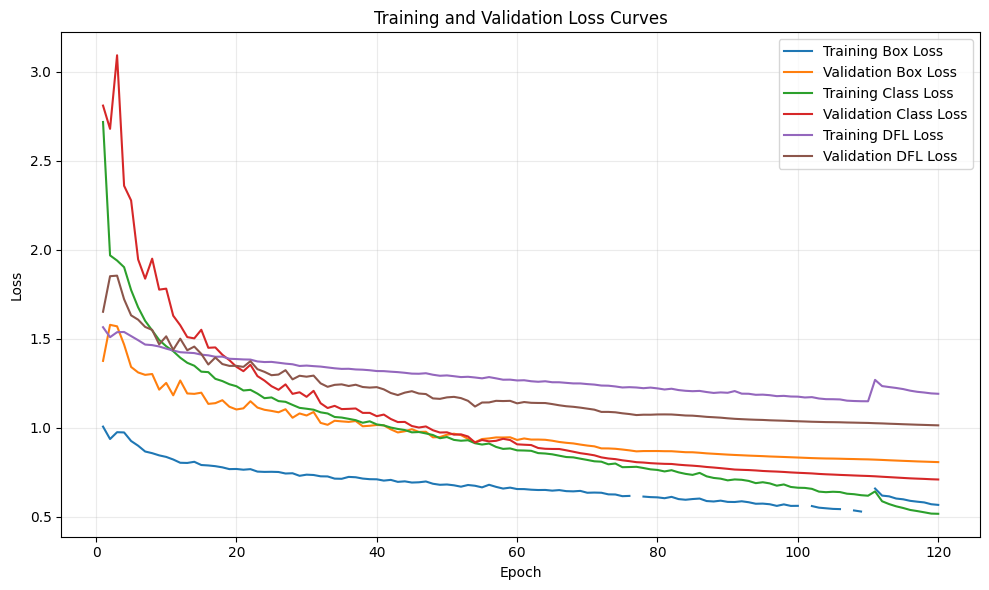

Saved: /kaggle/working/maize_paper_results/YOLO_Results/training_validation_loss.png


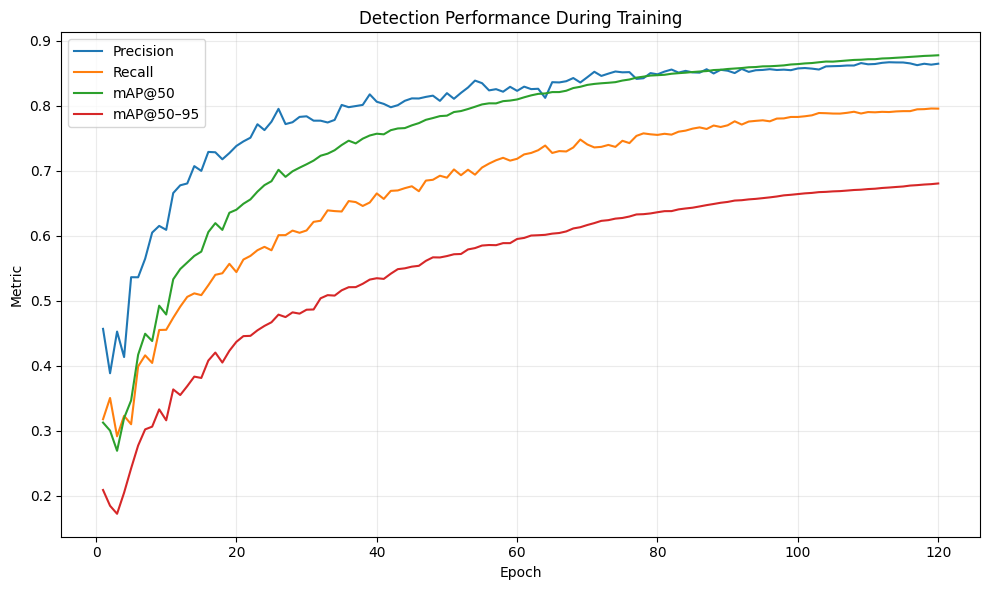

Saved: /kaggle/working/maize_paper_results/YOLO_Results/detection_metrics.png


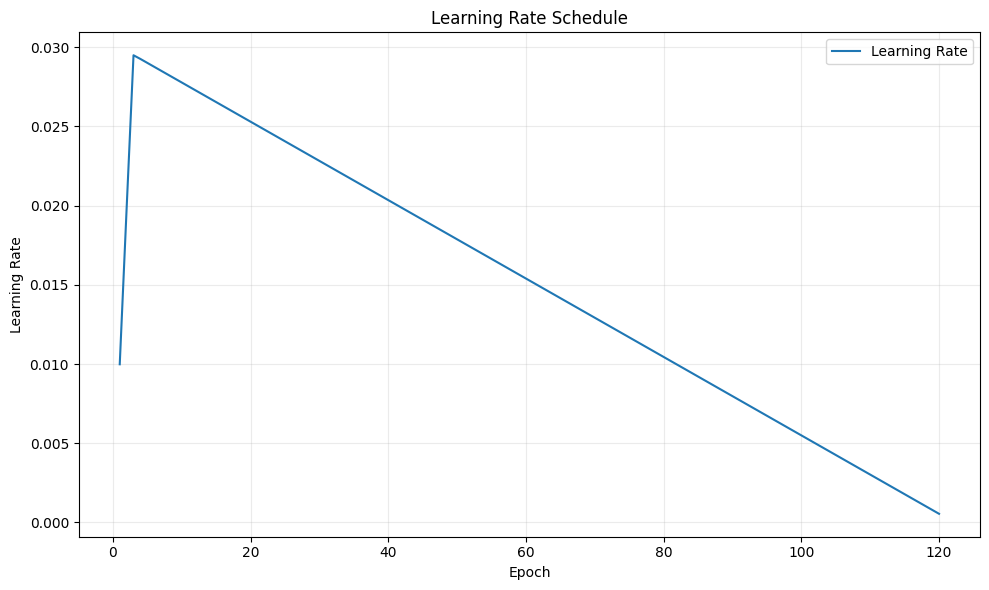

Saved: /kaggle/working/maize_paper_results/YOLO_Results/learning_rate.png


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# LOAD RESULTS
# ============================================================

RESULTS_CSV = "/kaggle/input/datasets/siam2461/result/results.csv"

results_df = pd.read_csv(RESULTS_CSV)

# Epoch numbering
epochs = results_df["epoch"]


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

CURVE_DIR = YOLO_RESULTS
CURVE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# FIGURE 1 — TRAINING & VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    results_df["train/box_loss"],
    label="Training Box Loss"
)

plt.plot(
    epochs,
    results_df["val/box_loss"],
    label="Validation Box Loss"
)

plt.plot(
    epochs,
    results_df["train/cls_loss"],
    label="Training Class Loss"
)

plt.plot(
    epochs,
    results_df["val/cls_loss"],
    label="Validation Class Loss"
)

plt.plot(
    epochs,
    results_df["train/dfl_loss"],
    label="Training DFL Loss"
)

plt.plot(
    epochs,
    results_df["val/dfl_loss"],
    label="Validation DFL Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Curves")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

loss_path = CURVE_DIR / "training_validation_loss.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", loss_path)


# ============================================================
# FIGURE 2 — PRECISION, RECALL, mAP
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    results_df["metrics/precision(B)"],
    label="Precision"
)

plt.plot(
    epochs,
    results_df["metrics/recall(B)"],
    label="Recall"
)

plt.plot(
    epochs,
    results_df["metrics/mAP50(B)"],
    label="mAP@50"
)

plt.plot(
    epochs,
    results_df["metrics/mAP50-95(B)"],
    label="mAP@50–95"
)

plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("Detection Performance During Training")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

metric_path = CURVE_DIR / "detection_metrics.png"
plt.savefig(metric_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", metric_path)


# ============================================================
# FIGURE 3 — LEARNING RATE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    results_df["lr/pg0"],
    label="Learning Rate"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

lr_path = CURVE_DIR / "learning_rate.png"
plt.savefig(lr_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", lr_path)

In [5]:
!pip -q install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.9 MB/s eta 0:00:00


In [6]:
from pathlib import Path

print("Searching for uploaded weight folder...\n")

for p in Path("/kaggle/input").rglob("data.pkl"):
    print("data.pkl found at:")
    print(p)

Searching for uploaded weight folder...

data.pkl found at:
/kaggle/input/datasets/siam2461/model/best/best/data.pkl


In [7]:
# ============================================================
# STEP 6 — RECONSTRUCT best.pt CORRECTLY
# ============================================================

from pathlib import Path
import zipfile

# Uploaded extracted weight
WEIGHT_DIR = Path(
    "/kaggle/input/datasets/siam2461/model/best/best"
)

# Output .pt
RECONSTRUCTED_PT = Path(
    "/kaggle/working/best_reconstructed.pt"
)

print("Source exists:", WEIGHT_DIR.exists())

# Remove previous incorrect reconstruction
if RECONSTRUCTED_PT.exists():
    RECONSTRUCTED_PT.unlink()

# ------------------------------------------------------------
# Create ZIP with ALL files inside a subdirectory
# ------------------------------------------------------------

with zipfile.ZipFile(
    RECONSTRUCTED_PT,
    mode="w",
    compression=zipfile.ZIP_STORED
) as zf:

    for file_path in WEIGHT_DIR.rglob("*"):

        if file_path.is_file():

            relative_path = file_path.relative_to(
                WEIGHT_DIR
            )

            # Put everything inside "archive/"
            arcname = Path("archive") / relative_path

            zf.write(
                file_path,
                arcname=str(arcname)
            )

print("=" * 70)
print("CORRECTED RECONSTRUCTION COMPLETE")
print("=" * 70)

print("Path:")
print(RECONSTRUCTED_PT)

print(
    "Size:",
    f"{RECONSTRUCTED_PT.stat().st_size / (1024**2):.2f} MB"
)

# ------------------------------------------------------------
# Show archive structure
# ------------------------------------------------------------

print("\nArchive structure:")

with zipfile.ZipFile(RECONSTRUCTED_PT, "r") as zf:

    for name in zf.namelist()[:20]:
        print(name)

print("=" * 70)

Source exists: True
CORRECTED RECONSTRUCTION COMPLETE
Path:
/kaggle/working/best_reconstructed.pt
Size: 5.22 MB

Archive structure:
archive/.format_version
archive/.storage_alignment
archive/byteorder
archive/data.pkl
archive/version
archive/.data/serialization_id
archive/data/0
archive/data/1
archive/data/10
archive/data/100
archive/data/101
archive/data/102
archive/data/103
archive/data/104
archive/data/105
archive/data/106
archive/data/107
archive/data/108
archive/data/109
archive/data/11


In [8]:
# ============================================================
# STEP 7 — TEST RECONSTRUCTED YOLO WEIGHT
# ============================================================

from ultralytics import YOLO

RECONSTRUCTED_PT = "/kaggle/working/best_reconstructed.pt"

try:

    test_model = YOLO(RECONSTRUCTED_PT)

    print("=" * 70)
    print("SUCCESS — YOLO WEIGHT LOADED")
    print("=" * 70)

    print("\nModel classes:")

    for class_id, name in test_model.names.items():
        print(f"{class_id}: {name}")

except Exception as e:

    print("=" * 70)
    print("WEIGHT LOAD FAILED")
    print("=" * 70)

    print(type(e).__name__)
    print(e)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
SUCCESS — YOLO WEIGHT LOADED

Model classes:
0: Blight
1: brown_spot
2: corn_rust
3: corn_smut
4: downy_mildew
5: grey_leaf_spot
6: healthy
7: maize-streak-disease


In [9]:
# ============================================================
# STEP 8.1 — DISPLAY YOLO EVALUATION VISUALIZATIONS
# ============================================================

from pathlib import Path
from IPython.display import display
from PIL import Image

evaluation_dir = Path(
    "/kaggle/working/maize_paper_results/"
    "YOLO_Results/test_evaluation"
)

print("=" * 75)
print("YOLO EVALUATION VISUALIZATIONS")
print("=" * 75)

print("\nVisualization directory:")
print(evaluation_dir)

# ============================================================
# 1. FIND PNG FILES
# ============================================================

plot_files = sorted(
    evaluation_dir.glob("*.png")
)

print(
    f"\nTotal visualization files found: "
    f"{len(plot_files)}"
)

for file in plot_files:
    print(" -", file.name)

# ============================================================
# 2. DISPLAY EACH VISUALIZATION
# ============================================================

for file in plot_files:

    print("\n" + "-" * 75)
    print(file.name)
    print("-" * 75)

    img = Image.open(file)

    display(img)

# ============================================================
# 3. FINAL MESSAGE
# ============================================================

print("\n" + "=" * 75)
print("ALL YOLO VISUALIZATIONS DISPLAYED")
print("=" * 75)

print(
    "\nSaved location:"
)
print(
    evaluation_dir
)

YOLO EVALUATION VISUALIZATIONS

Visualization directory:
/kaggle/working/maize_paper_results/YOLO_Results/test_evaluation

Total visualization files found: 0

ALL YOLO VISUALIZATIONS DISPLAYED

Saved location:
/kaggle/working/maize_paper_results/YOLO_Results/test_evaluation


TRAINING HISTORY
Total recorded epochs: 120
Epoch range: 1 - 120


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
0,1,164.959,1.00530,2.71705,1.56384,0.45657,0.31750,0.31238,0.20868,1.37454,2.80917,1.65066,0.009985,0.003328,0.009985,0.003328,0.009985,0.003328,0.009985,0.003328
1,2,299.673,0.93544,1.96743,1.50786,0.38829,0.35023,0.30003,0.18436,1.57717,2.67841,1.85053,0.019820,0.006607,0.019820,0.006607,0.019820,0.006607,0.019820,0.006607
2,3,431.041,0.97389,1.93851,1.53592,0.45240,0.29126,0.26896,0.17203,1.56888,3.09204,1.85364,0.029490,0.009830,0.029490,0.009830,0.029490,0.009830,0.029490,0.009830
3,4,560.912,0.97252,1.90106,1.53706,0.41316,0.32278,0.31935,0.20452,1.46629,2.35863,1.72102,0.029257,0.009753,0.029257,0.009753,0.029257,0.009753,0.029257,0.009753
4,5,691.276,0.92441,1.77274,1.51401,0.53603,0.30980,0.34645,0.24186,1.34051,2.27606,1.63050,0.029010,0.009670,0.029010,0.009670,0.029010,0.009670,0.029010,0.009670


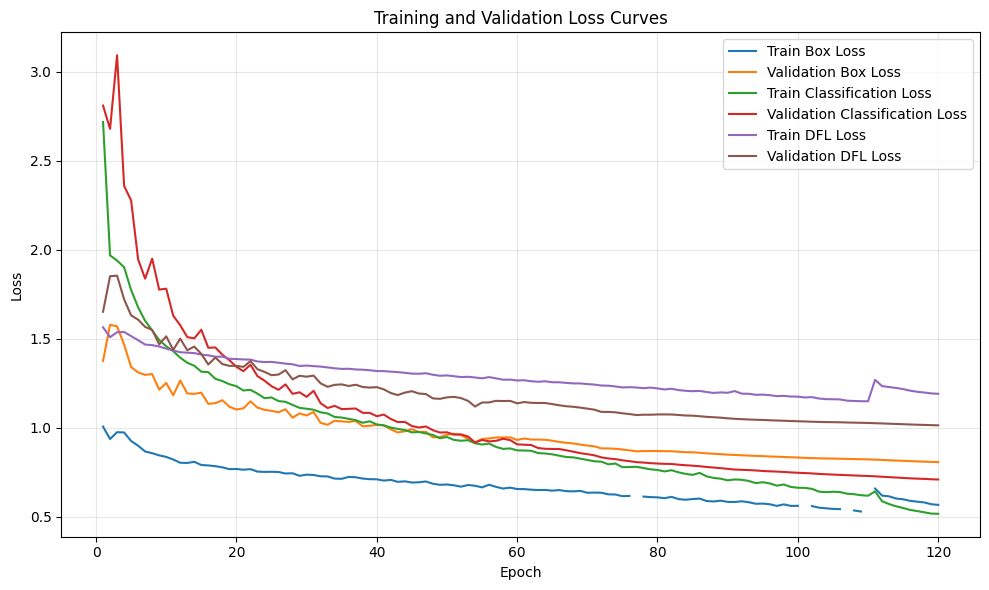


Saved: /kaggle/working/maize_paper_results/YOLO_Results/training_validation_loss.png


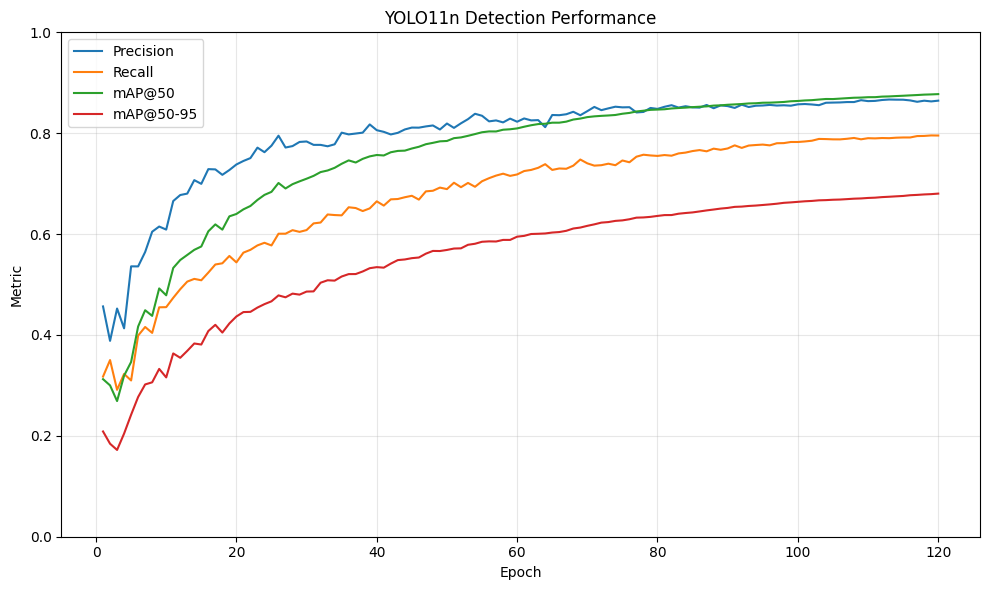


Saved: /kaggle/working/maize_paper_results/YOLO_Results/detection_metrics.png


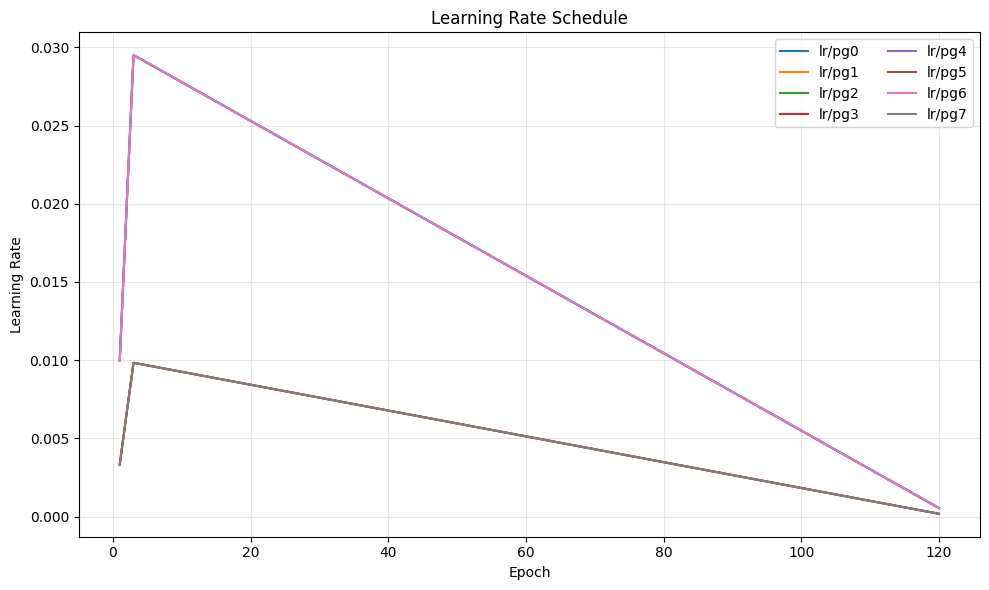


Saved: /kaggle/working/maize_paper_results/YOLO_Results/learning_rate.png

BEST RECORDED TRAINING EPOCH
Epoch       : 120
Precision   : 0.8645
Recall      : 0.7954
mAP50       : 0.8775
mAP50-95    : 0.6803

STEP 8.2 COMPLETE

Figures saved:
1. /kaggle/working/maize_paper_results/YOLO_Results/training_validation_loss.png
2. /kaggle/working/maize_paper_results/YOLO_Results/detection_metrics.png
3. /kaggle/working/maize_paper_results/YOLO_Results/learning_rate.png

Training summary:
/kaggle/working/maize_paper_results/YOLO_Results/best_training_epoch.csv


In [10]:
# ============================================================
# STEP 8.2 — TRAINING & VALIDATION CURVES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. PATHS
# ============================================================

RESULTS_CSV = Path(
    "/kaggle/input/datasets/siam2461/result/results.csv"
)

YOLO_RESULTS = Path(
    "/kaggle/working/maize_paper_results/YOLO_Results"
)

YOLO_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 2. LOAD RESULTS.CSV
# ============================================================

results_df = pd.read_csv(
    RESULTS_CSV
)

print("=" * 75)
print("TRAINING HISTORY")
print("=" * 75)

print(
    f"Total recorded epochs: "
    f"{len(results_df)}"
)

print(
    f"Epoch range: "
    f"{results_df['epoch'].min()} - "
    f"{results_df['epoch'].max()}"
)

display(
    results_df.head()
)

# ============================================================
# 3. TRAINING & VALIDATION LOSS
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.plot(
    results_df["epoch"],
    results_df["train/box_loss"],
    label="Train Box Loss"
)

ax.plot(
    results_df["epoch"],
    results_df["val/box_loss"],
    label="Validation Box Loss"
)

ax.plot(
    results_df["epoch"],
    results_df["train/cls_loss"],
    label="Train Classification Loss"
)

ax.plot(
    results_df["epoch"],
    results_df["val/cls_loss"],
    label="Validation Classification Loss"
)

ax.plot(
    results_df["epoch"],
    results_df["train/dfl_loss"],
    label="Train DFL Loss"
)

ax.plot(
    results_df["epoch"],
    results_df["val/dfl_loss"],
    label="Validation DFL Loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title(
    "Training and Validation Loss Curves"
)

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()

loss_path = (
    YOLO_RESULTS /
    "training_validation_loss.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved:",
    loss_path
)

# ============================================================
# 4. DETECTION PERFORMANCE METRICS
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.plot(
    results_df["epoch"],
    results_df["metrics/precision(B)"],
    label="Precision"
)

ax.plot(
    results_df["epoch"],
    results_df["metrics/recall(B)"],
    label="Recall"
)

ax.plot(
    results_df["epoch"],
    results_df["metrics/mAP50(B)"],
    label="mAP@50"
)

ax.plot(
    results_df["epoch"],
    results_df["metrics/mAP50-95(B)"],
    label="mAP@50-95"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Metric")
ax.set_title(
    "YOLO11n Detection Performance"
)

ax.set_ylim(
    0,
    1
)

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()

metrics_path = (
    YOLO_RESULTS /
    "detection_metrics.png"
)

plt.savefig(
    metrics_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved:",
    metrics_path
)

# ============================================================
# 5. LEARNING RATE CURVES
# ============================================================

lr_columns = [
    col for col in results_df.columns
    if col.startswith("lr/")
]

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for col in lr_columns:

    ax.plot(
        results_df["epoch"],
        results_df[col],
        label=col
    )

ax.set_xlabel("Epoch")
ax.set_ylabel("Learning Rate")
ax.set_title(
    "Learning Rate Schedule"
)

ax.grid(True, alpha=0.3)
ax.legend(
    ncol=2
)

plt.tight_layout()

lr_path = (
    YOLO_RESULTS /
    "learning_rate.png"
)

plt.savefig(
    lr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved:",
    lr_path
)

# ============================================================
# 6. BEST RECORDED EPOCH
# ============================================================

best_idx = results_df[
    "metrics/mAP50-95(B)"
].idxmax()

best_row = results_df.loc[
    best_idx
]

best_epoch = int(
    best_row["epoch"]
)

best_precision = float(
    best_row["metrics/precision(B)"]
)

best_recall = float(
    best_row["metrics/recall(B)"]
)

best_map50 = float(
    best_row["metrics/mAP50(B)"]
)

best_map5095 = float(
    best_row["metrics/mAP50-95(B)"]
)

print("\n" + "=" * 75)
print("BEST RECORDED TRAINING EPOCH")
print("=" * 75)

print(
    f"Epoch       : {best_epoch}"
)

print(
    f"Precision   : {best_precision:.4f}"
)

print(
    f"Recall      : {best_recall:.4f}"
)

print(
    f"mAP50       : {best_map50:.4f}"
)

print(
    f"mAP50-95    : {best_map5095:.4f}"
)

# ============================================================
# 7. SAVE TRAINING SUMMARY
# ============================================================

training_summary = pd.DataFrame([
    {
        "best_epoch": best_epoch,
        "precision": best_precision,
        "recall": best_recall,
        "mAP50": best_map50,
        "mAP50-95": best_map5095
    }
])

training_summary_path = (
    YOLO_RESULTS /
    "best_training_epoch.csv"
)

training_summary.to_csv(
    training_summary_path,
    index=False
)

# ============================================================
# 8. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 75)
print("STEP 8.2 COMPLETE")
print("=" * 75)

print("\nFigures saved:")

print(
    "1.",
    loss_path
)

print(
    "2.",
    metrics_path
)

print(
    "3.",
    lr_path
)

print(
    "\nTraining summary:"
)

print(
    training_summary_path
)

In [11]:
# ============================================================
# STEP 9.1 — 3D PIPELINE SETUP
# ============================================================

from pathlib import Path
import torch
import pandas as pd
import numpy as np
import cv2

# ============================================================
# 1. PATHS
# ============================================================

REPO = Path(
    "/kaggle/working/maize-disease-detection"
)

TEST_DIR = (
    REPO /
    "images" /
    "test"
)

WEIGHT_PATH = Path(
    "/kaggle/working/best_reconstructed.pt"
)

YAML_PATH = Path(
    "/kaggle/input/datasets/siam2461/model/kaggle_data.yaml"
)

PAPER_RESULTS = Path(
    "/kaggle/working/maize_paper_results"
)

YOLO_RESULTS = (
    PAPER_RESULTS /
    "YOLO_Results"
)

RESULTS_3D = (
    PAPER_RESULTS /
    "3D_Results"
)

DEPTH_VIS_DIR = (
    RESULTS_3D /
    "depth_visualizations"
)

DETECTION_DEPTH_VIS_DIR = (
    RESULTS_3D /
    "detection_depth_visualizations"
)

# ============================================================
# 2. CREATE 3D OUTPUT FOLDERS
# ============================================================

RESULTS_3D.mkdir(
    parents=True,
    exist_ok=True
)

DEPTH_VIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DETECTION_DEPTH_VIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 3. DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("=" * 75)
print("3D PIPELINE SETUP")
print("=" * 75)

print("\nDevice:")
print(device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ============================================================
# 4. CHECK DATASET
# ============================================================

print("\n" + "=" * 75)
print("DATASET CHECK")
print("=" * 75)

print("\nRepository:")
print(REPO)
print("Exists:", REPO.exists())

print("\nTest directory:")
print(TEST_DIR)
print("Exists:", TEST_DIR.exists())

# ============================================================
# 5. FIND TEST IMAGES
# ============================================================

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
}

if TEST_DIR.exists():

    image_files = sorted(
        [
            p
            for p in TEST_DIR.iterdir()
            if p.suffix in image_extensions
        ]
    )

else:

    image_files = []

print(
    "\nTotal test images:",
    len(image_files)
)

# ============================================================
# 6. SHOW SAMPLE IMAGE PATHS
# ============================================================

print("\nFirst 5 test images:")

for img_path in image_files[:5]:

    print(
        " -",
        img_path.name
    )

# ============================================================
# 7. CHECK WEIGHT
# ============================================================

print("\n" + "=" * 75)
print("MODEL CHECK")
print("=" * 75)

print("\nYOLO weight:")
print(WEIGHT_PATH)

print(
    "Exists:",
    WEIGHT_PATH.exists()
)

# ============================================================
# 8. OUTPUT DIRECTORIES
# ============================================================

print("\n" + "=" * 75)
print("3D OUTPUT DIRECTORIES")
print("=" * 75)

print(
    "\nMain 3D results:"
)
print(
    RESULTS_3D
)

print(
    "\nDepth visualizations:"
)
print(
    DEPTH_VIS_DIR
)

print(
    "\nDetection + depth visualizations:"
)
print(
    DETECTION_DEPTH_VIS_DIR
)

print("\n" + "=" * 75)
print("STEP 9.1 COMPLETE")
print("=" * 75)

3D PIPELINE SETUP

Device:
cuda
GPU: Tesla T4

DATASET CHECK

Repository:
/kaggle/working/maize-disease-detection
Exists: True

Test directory:
/kaggle/working/maize-disease-detection/images/test
Exists: True

Total test images: 1506

First 5 test images:
 - 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_270deg_JPG_jpg.rf.621424bc15ab235f6713a6f7194acdb9.jpg
 - 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_90deg_JPG_jpg.rf.a2c40ae78ca87852512cf798ffb3c1d2.jpg
 - 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.3eae18f3e80ea236fdb5db3cc4568dc5.jpg
 - 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.7c338f732b4c42b6e56a135d4391e44a.jpg
 - 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.ba35bf7152cf71114b202321aa6bfc2d.jpg

MODEL CHECK

YOLO weight:
/kaggle/working/best_reconstructed.pt
Exists: True

3D OUTPUT DIRECTORIES

Main 3D results:
/kaggle/working/maize_paper_results/3D_Results

Depth visualizations:
/kaggle/working/maize_paper

In [12]:
# ============================================================
# STEP 9.2 — LOAD YOLO11n + DEPTH ANYTHING V2
# ============================================================

import torch
from ultralytics import YOLO
from transformers import (
    AutoImageProcessor,
    AutoModelForDepthEstimation
)

# ============================================================
# 1. LOAD YOLO11n
# ============================================================

print("=" * 75)
print("LOADING YOLO11n")
print("=" * 75)

yolo_model = YOLO(
    str(WEIGHT_PATH)
)

print("YOLO11n loaded successfully.")

# ============================================================
# 2. SHOW YOLO CLASSES
# ============================================================

class_names = yolo_model.names

print("\nYOLO Classes:")

for class_id, class_name in class_names.items():

    print(
        f"{class_id}: {class_name}"
    )

# ============================================================
# 3. LOAD DEPTH ANYTHING V2
# ============================================================

print("\n" + "=" * 75)
print("LOADING DEPTH ANYTHING V2")
print("=" * 75)

DEPTH_MODEL_NAME = (
    "depth-anything/Depth-Anything-V2-Small-hf"
)

depth_processor = (
    AutoImageProcessor.from_pretrained(
        DEPTH_MODEL_NAME
    )
)

depth_model = (
    AutoModelForDepthEstimation
    .from_pretrained(
        DEPTH_MODEL_NAME
    )
    .to(device)
)

depth_model.eval()

print(
    "\nDepth Anything V2 loaded successfully."
)

print(
    "Model:",
    DEPTH_MODEL_NAME
)

# ============================================================
# 4. MODEL DEVICE CHECK
# ============================================================

print("\n" + "=" * 75)
print("MODEL DEVICE CHECK")
print("=" * 75)

print(
    "YOLO device:",
    next(
        yolo_model.model.parameters()
    ).device
)

print(
    "Depth model device:",
    next(
        depth_model.parameters()
    ).device
)

# ============================================================
# 5. FINAL CHECK
# ============================================================

print("\n" + "=" * 75)
print("STEP 9.2 COMPLETE")
print("=" * 75)

print(
    "\nYOLO11n     : READY"
)

print(
    "Depth V2    : READY"
)

print(
    "Test images :",
    len(image_files)
)

print(
    "GPU         :",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

LOADING YOLO11n
YOLO11n loaded successfully.

YOLO Classes:
0: Blight
1: brown_spot
2: corn_rust
3: corn_smut
4: downy_mildew
5: grey_leaf_spot
6: healthy
7: maize-streak-disease

LOADING DEPTH ANYTHING V2


preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

The image processor of type `DPTImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/99.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]


Depth Anything V2 loaded successfully.
Model: depth-anything/Depth-Anything-V2-Small-hf

MODEL DEVICE CHECK
YOLO device: cpu
Depth model device: cuda:0

STEP 9.2 COMPLETE

YOLO11n     : READY
Depth V2    : READY
Test images : 1506
GPU         : Tesla T4


STEP 9.3 — SINGLE-IMAGE SANITY CHECK
Sample image: 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_270deg_JPG_jpg.rf.621424bc15ab235f6713a6f7194acdb9.jpg
Image size: 640 × 640
YOLO detections: 3
Depth range: 2.1267 → 5.3297
Normalized depth range: 0.0000 → 1.0000

Disease-region relative depth:
1. grey_leaf_spot | Conf=0.636 | Z_relative=0.8399
2. grey_leaf_spot | Conf=0.507 | Z_relative=0.9467
3. grey_leaf_spot | Conf=0.384 | Z_relative=0.8550


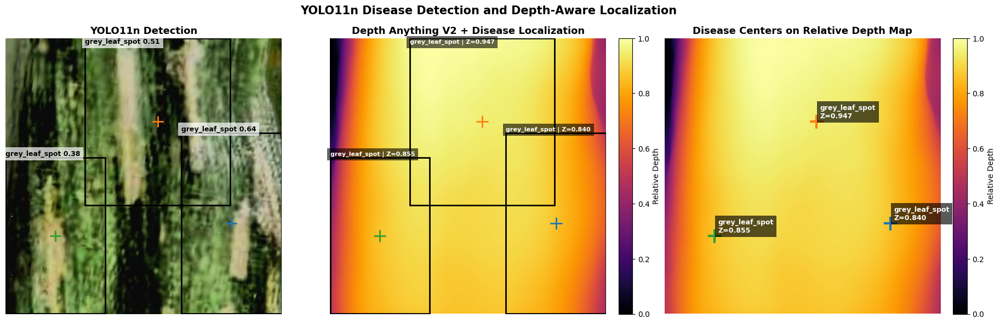


Saved:
/kaggle/working/maize_paper_results/3D_Results/detection_depth_visualizations/step9_3_single_image_check.png

STEP 9.3 COMPLETE


In [13]:
# ============================================================
# STEP 9.3 — SINGLE-IMAGE SANITY CHECK
# YOLO + DEPTH + DISEASE MARKING ON DEPTH MAP
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

print("=" * 75)
print("STEP 9.3 — SINGLE-IMAGE SANITY CHECK")
print("=" * 75)

# ------------------------------------------------------------
# 1. Select one test image
# ------------------------------------------------------------
image_files = sorted(
    list(TEST_DIR.glob("*.jpg")) +
    list(TEST_DIR.glob("*.jpeg")) +
    list(TEST_DIR.glob("*.png"))
)

sample_path = image_files[0]

print(f"Sample image: {sample_path.name}")

# ------------------------------------------------------------
# 2. Load image
# ------------------------------------------------------------
image_bgr = cv2.imread(str(sample_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

H, W = image_rgb.shape[:2]

print(f"Image size: {W} × {H}")

# ------------------------------------------------------------
# 3. YOLO detection
# ------------------------------------------------------------
yolo_results = yolo_model.predict(
    source=str(sample_path),
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

result = yolo_results[0]

detections = []

if result.boxes is not None and len(result.boxes) > 0:

    boxes = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, conf, cls_id in zip(boxes, confs, classes):

        x1, y1, x2, y2 = box

        # Clip coordinates
        x1 = max(0, min(W - 1, int(x1)))
        y1 = max(0, min(H - 1, int(y1)))
        x2 = max(0, min(W - 1, int(x2)))
        y2 = max(0, min(H - 1, int(y2)))

        # Center
        u = (x1 + x2) / 2
        v = (y1 + y2) / 2

        # Area ratio
        area_ratio = ((x2 - x1) * (y2 - y1)) / (W * H)

        detections.append({
            "class_id": int(cls_id),
            "class_name": class_names[int(cls_id)],
            "confidence": float(conf),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
            "u": u,
            "v": v,
            "area_ratio": area_ratio
        })

print(f"YOLO detections: {len(detections)}")

# ------------------------------------------------------------
# 4. Depth Anything V2
# ------------------------------------------------------------
pil_image = Image.fromarray(image_rgb)

depth_inputs = depth_processor(
    images=pil_image,
    return_tensors="pt"
)

depth_inputs = {
    k: v.to(device)
    for k, v in depth_inputs.items()
}

with torch.inference_mode():
    depth_outputs = depth_model(**depth_inputs)

depth_raw = (
    depth_outputs.predicted_depth
    .squeeze()
    .detach()
    .cpu()
    .numpy()
)

# Resize depth to original image size
depth_raw = cv2.resize(
    depth_raw,
    (W, H),
    interpolation=cv2.INTER_LINEAR
)

# ------------------------------------------------------------
# 5. Normalize depth
# ------------------------------------------------------------
d_min = np.nanmin(depth_raw)
d_max = np.nanmax(depth_raw)

if d_max > d_min:
    depth_norm = (depth_raw - d_min) / (d_max - d_min)
else:
    depth_norm = np.zeros_like(depth_raw)

print(
    f"Depth range: "
    f"{d_min:.4f} → {d_max:.4f}"
)

print(
    f"Normalized depth range: "
    f"{depth_norm.min():.4f} → {depth_norm.max():.4f}"
)

# ------------------------------------------------------------
# 6. Disease-region depth
# ------------------------------------------------------------
for d in detections:

    x1 = d["x1"]
    y1 = d["y1"]
    x2 = d["x2"]
    y2 = d["y2"]

    roi_depth = depth_norm[
        y1:y2 + 1,
        x1:x2 + 1
    ]

    valid_depth = roi_depth[np.isfinite(roi_depth)]

    if len(valid_depth) > 0:
        d["z_relative"] = float(
            np.median(valid_depth)
        )
    else:
        d["z_relative"] = np.nan

print("\nDisease-region relative depth:")

for i, d in enumerate(detections, 1):

    print(
        f"{i}. {d['class_name']} | "
        f"Conf={d['confidence']:.3f} | "
        f"Z_relative={d['z_relative']:.4f}"
    )

# ============================================================
# 7. CREATE DEPTH MAP WITH DISEASE MARKINGS
# ============================================================

depth_marked = depth_norm.copy()

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6)
)

# ------------------------------------------------------------
# PANEL 1 — Original + YOLO Detection
# ------------------------------------------------------------
axes[0].imshow(image_rgb)

for i, d in enumerate(detections, 1):

    x1, y1 = d["x1"], d["y1"]
    x2, y2 = d["x2"], d["y2"]

    u = int(d["u"])
    v = int(d["v"])

    # Bounding box
    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    axes[0].add_patch(rect)

    # Center marker
    axes[0].plot(
        u,
        v,
        marker="+",
        markersize=14,
        markeredgewidth=2
    )

    # Label
    axes[0].text(
        x1,
        max(12, y1 - 5),
        f"{d['class_name']} {d['confidence']:.2f}",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.7,
            edgecolor="none"
        )
    )

axes[0].set_title(
    "YOLO11n Detection",
    fontsize=13,
    fontweight="bold"
)

axes[0].axis("off")

# ------------------------------------------------------------
# PANEL 2 — DEPTH MAP + DISEASE BBOX + CENTER
# ------------------------------------------------------------
im = axes[1].imshow(
    depth_norm,
    cmap="inferno"
)

for i, d in enumerate(detections, 1):

    x1, y1 = d["x1"], d["y1"]
    x2, y2 = d["x2"], d["y2"]

    u = int(d["u"])
    v = int(d["v"])

    # Disease bounding box
    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    axes[1].add_patch(rect)

    # Disease center
    axes[1].plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2
    )

    # Label with relative depth
    axes[1].text(
        x1,
        max(12, y1 - 5),
        f"{d['class_name']} | Z={d['z_relative']:.3f}",
        fontsize=8,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            alpha=0.6,
            edgecolor="none"
        )
    )

axes[1].set_title(
    "Depth Anything V2 + Disease Localization",
    fontsize=13,
    fontweight="bold"
)

axes[1].axis("off")

plt.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Relative Depth"
)

# ------------------------------------------------------------
# PANEL 3 — DEPTH MAP + ONLY DISEASE CENTERS
# ------------------------------------------------------------
im2 = axes[2].imshow(
    depth_norm,
    cmap="inferno"
)

for i, d in enumerate(detections, 1):

    u = int(d["u"])
    v = int(d["v"])

    # Center marker
    axes[2].plot(
        u,
        v,
        marker="+",
        markersize=18,
        markeredgewidth=3
    )

    # Label
    axes[2].text(
        u + 8,
        v - 8,
        f"{d['class_name']}\nZ={d['z_relative']:.3f}",
        fontsize=9,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            alpha=0.65,
            edgecolor="none"
        )
    )

axes[2].set_title(
    "Disease Centers on Relative Depth Map",
    fontsize=13,
    fontweight="bold"
)

axes[2].axis("off")

plt.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046,
    pad=0.04,
    label="Relative Depth"
)

# ------------------------------------------------------------
# 8. Compact layout
# ------------------------------------------------------------
plt.suptitle(
    "YOLO11n Disease Detection and Depth-Aware Localization",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

plt.subplots_adjust(
    left=0.02,
    right=0.96,
    bottom=0.04,
    top=0.88,
    wspace=0.08
)

# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------
sanity_path = (
    PAPER_RESULTS /
    "3D_Results" /
    "detection_depth_visualizations" /
    "step9_3_single_image_check.png"
)

plt.savefig(
    sanity_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(sanity_path)

print("\n" + "=" * 75)
print("STEP 9.3 COMPLETE")
print("=" * 75)

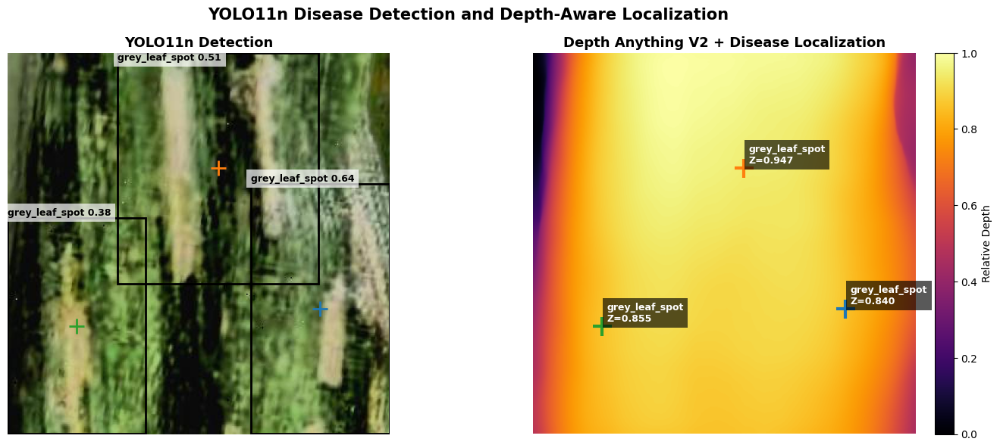


Saved:
/kaggle/working/maize_paper_results/3D_Results/detection_depth_visualizations/step9_3_single_image_check.png

STEP 9.3 COMPLETE


In [14]:
# ============================================================
# 7. TWO-PANEL VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

# ------------------------------------------------------------
# PANEL 1 — Original + YOLO Detection
# ------------------------------------------------------------
axes[0].imshow(image_rgb)

for i, d in enumerate(detections, 1):

    x1, y1 = d["x1"], d["y1"]
    x2, y2 = d["x2"], d["y2"]

    u = int(d["u"])
    v = int(d["v"])

    # Bounding box
    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    axes[0].add_patch(rect)

    # Disease center
    axes[0].plot(
        u,
        v,
        marker="+",
        markersize=14,
        markeredgewidth=2
    )

    # Label
    axes[0].text(
        x1,
        max(12, y1 - 5),
        f"{d['class_name']} {d['confidence']:.2f}",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.7,
            edgecolor="none"
        )
    )

axes[0].set_title(
    "YOLO11n Detection",
    fontsize=13,
    fontweight="bold"
)

axes[0].axis("off")


# ------------------------------------------------------------
# PANEL 2 — Depth Map + Disease Centers
# ------------------------------------------------------------
im = axes[1].imshow(
    depth_norm,
    cmap="inferno"
)

for i, d in enumerate(detections, 1):

    u = int(d["u"])
    v = int(d["v"])

    # Disease center
    axes[1].plot(
        u,
        v,
        marker="+",
        markersize=18,
        markeredgewidth=3
    )

    # Disease label + relative depth
    axes[1].text(
        u + 8,
        v - 8,
        f"{d['class_name']}\nZ={d['z_relative']:.3f}",
        fontsize=9,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            alpha=0.65,
            edgecolor="none"
        )
    )

# IMPORTANT:
# Title taken from the previous 2nd panel
axes[1].set_title(
    "Depth Anything V2 + Disease Localization",
    fontsize=13,
    fontweight="bold"
)

axes[1].axis("off")

plt.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Relative Depth"
)


# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------
plt.suptitle(
    "YOLO11n Disease Detection and Depth-Aware Localization",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

plt.subplots_adjust(
    left=0.02,
    right=0.96,
    bottom=0.04,
    top=0.88,
    wspace=0.08
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
sanity_path = (
    PAPER_RESULTS /
    "3D_Results" /
    "detection_depth_visualizations" /
    "step9_3_single_image_check.png"
)

plt.savefig(
    sanity_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(sanity_path)

print("\n" + "=" * 75)
print("STEP 9.3 COMPLETE")
print("=" * 75)

STEP 9.3 — SINGLE-IMAGE SANITY CHECK
Sample image: 0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_270deg_JPG_jpg.rf.621424bc15ab235f6713a6f7194acdb9.jpg
Image size: 640 × 640
YOLO detections: 3
1. grey_leaf_spot | Conf=0.636 | BBox=(407,220,639,639) | Area=0.237
2. grey_leaf_spot | Conf=0.507 | BBox=(184,0,520,387) | Area=0.317
3. grey_leaf_spot | Conf=0.384 | BBox=(0,277,230,639) | Area=0.203

Depth range: 2.1267 → 5.3297
Normalized depth range: 0.0000 → 1.0000

Disease-region relative depth:
1. grey_leaf_spot | Z_relative = 0.8399
2. grey_leaf_spot | Z_relative = 0.9467
3. grey_leaf_spot | Z_relative = 0.8550


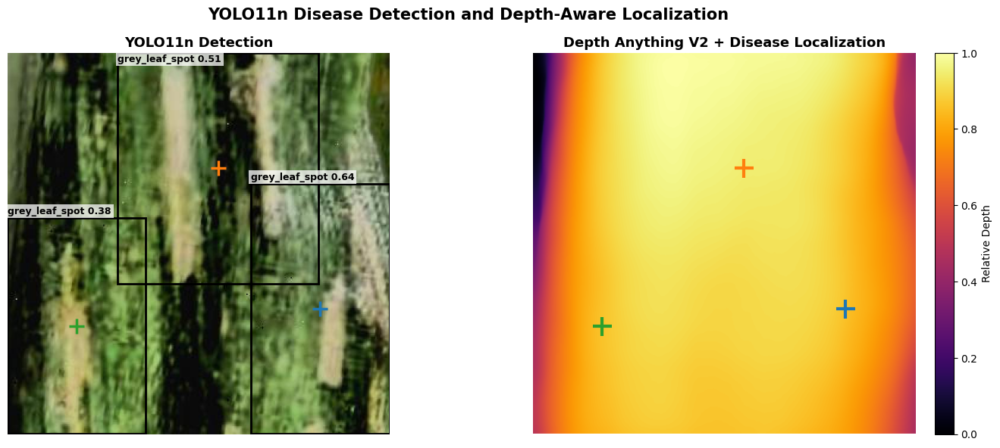


Saved:
/kaggle/working/maize_paper_results/3D_Results/detection_depth_visualizations/step9_3_single_image_check.png

STEP 9.3 COMPLETE


In [15]:
# ============================================================
# STEP 9.3 — SINGLE-IMAGE SANITY CHECK
# YOLO11n + DEPTH ANYTHING V2
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch

print("=" * 75)
print("STEP 9.3 — SINGLE-IMAGE SANITY CHECK")
print("=" * 75)


# ============================================================
# 1. SELECT ONE TEST IMAGE
# ============================================================

image_files = sorted(
    list(TEST_DIR.glob("*.jpg")) +
    list(TEST_DIR.glob("*.jpeg")) +
    list(TEST_DIR.glob("*.png"))
)

if len(image_files) == 0:
    raise RuntimeError("No test images found.")

sample_path = image_files[0]

print(f"Sample image: {sample_path.name}")


# ============================================================
# 2. LOAD IMAGE
# ============================================================

image_bgr = cv2.imread(str(sample_path))

if image_bgr is None:
    raise RuntimeError(f"Could not read image: {sample_path}")

image_rgb = cv2.cvtColor(
    image_bgr,
    cv2.COLOR_BGR2RGB
)

H, W = image_rgb.shape[:2]

print(f"Image size: {W} × {H}")


# ============================================================
# 3. YOLO11n DETECTION
# ============================================================

yolo_results = yolo_model.predict(
    source=str(sample_path),
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

result = yolo_results[0]

detections = []


if result.boxes is not None and len(result.boxes) > 0:

    boxes = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for box, conf, cls_id in zip(
        boxes,
        confs,
        classes
    ):

        x1, y1, x2, y2 = box

        # ----------------------------------------------------
        # Clip bounding box
        # ----------------------------------------------------
        x1 = max(0, min(W - 1, int(x1)))
        y1 = max(0, min(H - 1, int(y1)))
        x2 = max(0, min(W - 1, int(x2)))
        y2 = max(0, min(H - 1, int(y2)))

        # ----------------------------------------------------
        # Detection center
        # ----------------------------------------------------
        u = (x1 + x2) / 2.0
        v = (y1 + y2) / 2.0

        # ----------------------------------------------------
        # Bounding-box area ratio
        # ----------------------------------------------------
        area_ratio = (
            ((x2 - x1) * (y2 - y1))
            / (W * H)
        )

        detections.append({
            "class_id": int(cls_id),
            "class_name": class_names[int(cls_id)],
            "confidence": float(conf),

            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,

            "u": u,
            "v": v,

            "area_ratio": area_ratio
        })


print(f"YOLO detections: {len(detections)}")


# ============================================================
# 4. PRINT YOLO DETECTIONS
# ============================================================

for i, d in enumerate(detections, 1):

    print(
        f"{i}. {d['class_name']} | "
        f"Conf={d['confidence']:.3f} | "
        f"BBox=({d['x1']},{d['y1']},"
        f"{d['x2']},{d['y2']}) | "
        f"Area={d['area_ratio']:.3f}"
    )


# ============================================================
# 5. DEPTH ANYTHING V2
# ============================================================

pil_image = Image.fromarray(image_rgb)

depth_inputs = depth_processor(
    images=pil_image,
    return_tensors="pt"
)

depth_inputs = {
    key: value.to(device)
    for key, value in depth_inputs.items()
}


with torch.inference_mode():

    depth_outputs = depth_model(
        **depth_inputs
    )


# ------------------------------------------------------------
# Get predicted depth
# ------------------------------------------------------------

depth_raw = (
    depth_outputs.predicted_depth
    .squeeze()
    .detach()
    .cpu()
    .numpy()
)


# ============================================================
# 6. RESIZE DEPTH MAP TO ORIGINAL IMAGE SIZE
# ============================================================

depth_raw = cv2.resize(
    depth_raw,
    (W, H),
    interpolation=cv2.INTER_LINEAR
)


# ============================================================
# 7. NORMALIZE DEPTH TO RELATIVE DEPTH [0, 1]
# ============================================================

d_min = np.nanmin(depth_raw)
d_max = np.nanmax(depth_raw)

if d_max > d_min:

    depth_norm = (
        depth_raw - d_min
    ) / (
        d_max - d_min
    )

else:

    depth_norm = np.zeros_like(
        depth_raw
    )


print(
    f"\nDepth range: "
    f"{d_min:.4f} → {d_max:.4f}"
)

print(
    f"Normalized depth range: "
    f"{depth_norm.min():.4f} → "
    f"{depth_norm.max():.4f}"
)


# ============================================================
# 8. EXTRACT DISEASE-REGION RELATIVE DEPTH
# ============================================================

print("\nDisease-region relative depth:")


for i, d in enumerate(detections, 1):

    x1 = d["x1"]
    y1 = d["y1"]
    x2 = d["x2"]
    y2 = d["y2"]

    # --------------------------------------------------------
    # Depth values ONLY inside YOLO disease bounding box
    # --------------------------------------------------------
    roi_depth = depth_norm[
        y1:y2 + 1,
        x1:x2 + 1
    ]

    valid_depth = roi_depth[
        np.isfinite(roi_depth)
    ]

    if len(valid_depth) > 0:

        z_relative = float(
            np.median(valid_depth)
        )

    else:

        z_relative = np.nan

    d["z_relative"] = z_relative

    print(
        f"{i}. {d['class_name']} | "
        f"Z_relative = {z_relative:.4f}"
    )


# ============================================================
# 9. CREATE TWO-PANEL FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


# ============================================================
# PANEL 1 — YOLO11n DETECTION
# ============================================================

axes[0].imshow(image_rgb)


for i, d in enumerate(detections, 1):

    x1 = d["x1"]
    y1 = d["y1"]
    x2 = d["x2"]
    y2 = d["y2"]

    u = int(d["u"])
    v = int(d["v"])

    # --------------------------------------------------------
    # Bounding box
    # --------------------------------------------------------
    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    axes[0].add_patch(rect)

    # --------------------------------------------------------
    # Disease center
    # --------------------------------------------------------
    axes[0].plot(
        u,
        v,
        marker="+",
        markersize=15,
        markeredgewidth=2.5
    )

    # --------------------------------------------------------
    # Class + confidence
    # --------------------------------------------------------
    axes[0].text(
        x1,
        max(15, y1 - 7),
        f"{d['class_name']} "
        f"{d['confidence']:.2f}",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.75,
            edgecolor="none",
            pad=2
        )
    )


axes[0].set_title(
    "YOLO11n Detection",
    fontsize=13,
    fontweight="bold"
)

axes[0].axis("off")


# ============================================================
# PANEL 2 — DEPTH MAP + DISEASE CENTERS
# ============================================================

im = axes[1].imshow(
    depth_norm,
    cmap="inferno"
)


for i, d in enumerate(detections, 1):

    u = int(d["u"])
    v = int(d["v"])

    # --------------------------------------------------------
    # ONLY disease center
    # --------------------------------------------------------
    axes[1].plot(
        u,
        v,
        marker="+",
        markersize=18,
        markeredgewidth=3
    )


axes[1].set_title(
    "Depth Anything V2 + Disease Localization",
    fontsize=13,
    fontweight="bold"
)

axes[1].axis("off")


# ------------------------------------------------------------
# Relative depth colorbar
# ------------------------------------------------------------

cbar = plt.colorbar(
    im,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Relative Depth",
    fontsize=10
)


# ============================================================
# 10. OVERALL FIGURE TITLE
# ============================================================

plt.suptitle(
    "YOLO11n Disease Detection and Depth-Aware Localization",
    fontsize=15,
    fontweight="bold",
    y=0.98
)


# ============================================================
# 11. COMPACT LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.02,
    right=0.96,
    bottom=0.04,
    top=0.88,
    wspace=0.08
)


# ============================================================
# 12. SAVE FIGURE
# ============================================================

sanity_path = (
    PAPER_RESULTS
    / "3D_Results"
    / "detection_depth_visualizations"
    / "step9_3_single_image_check.png"
)

plt.savefig(
    sanity_path,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# 13. DISPLAY
# ============================================================

plt.show()


print("\nSaved:")
print(sanity_path)

print("\n" + "=" * 75)
print("STEP 9.3 COMPLETE")
print("=" * 75)

In [16]:
# ============================================================
# STEP 9.4 — MOVE YOLO11n TO GPU
# ============================================================

print("=" * 75)
print("STEP 9.4 — YOLO11n GPU SETUP")
print("=" * 75)

# ------------------------------------------------------------
# 1. Check CUDA
# ------------------------------------------------------------
print(f"CUDA available: {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

print(f"GPU: {torch.cuda.get_device_name(0)}")


# ------------------------------------------------------------
# 2. Move YOLO11n to GPU
# ------------------------------------------------------------
yolo_model.to("cuda:0")


# ------------------------------------------------------------
# 3. Verify devices
# ------------------------------------------------------------
yolo_device = next(
    yolo_model.model.parameters()
).device

depth_device = next(
    depth_model.parameters()
).device


print("\nModel Device Check")
print("-" * 50)
print(f"YOLO11n device       : {yolo_device}")
print(f"Depth Anything V2    : {depth_device}")


# ------------------------------------------------------------
# 4. Final verification
# ------------------------------------------------------------
if str(yolo_device) == "cuda:0":
    print("\nYOLO11n successfully moved to GPU.")
else:
    print("\nWARNING: YOLO11n is not on GPU.")


if str(depth_device) == "cuda:0":
    print("Depth Anything V2 is on GPU.")
else:
    print("WARNING: Depth Anything V2 is not on GPU.")


print("\n" + "=" * 75)
print("STEP 9.4 COMPLETE")
print("=" * 75)

STEP 9.4 — YOLO11n GPU SETUP
CUDA available: True
GPU: Tesla T4

Model Device Check
--------------------------------------------------
YOLO11n device       : cuda:0
Depth Anything V2    : cuda:0

YOLO11n successfully moved to GPU.
Depth Anything V2 is on GPU.

STEP 9.4 COMPLETE


In [17]:
# ============================================================
# STEP 9.5 — 3D LOCALIZATION CALCULATION CHECK
# ============================================================

print("=" * 75)
print("STEP 9.5 — 3D LOCALIZATION CALCULATION CHECK")
print("=" * 75)

# ------------------------------------------------------------
# Use detections and depth values from STEP 9.3
# ------------------------------------------------------------

if len(detections) == 0:
    raise RuntimeError(
        "No YOLO detections found in the sample image."
    )

# ------------------------------------------------------------
# Approximate camera parameters
# ------------------------------------------------------------
fx = float(W)
fy = float(W)

cx = W / 2.0
cy = H / 2.0

print("\nApproximate Camera Parameters")
print("-" * 50)
print(f"fx = {fx:.2f}")
print(f"fy = {fy:.2f}")
print(f"cx = {cx:.2f}")
print(f"cy = {cy:.2f}")

# ------------------------------------------------------------
# Calculate relative 3D coordinates
# ------------------------------------------------------------

print("\nRelative 3D Localization")
print("-" * 75)

for i, d in enumerate(detections, 1):

    u = d["u"]
    v = d["v"]
    z = d["z_relative"]

    if not np.isfinite(z):
        d["x_relative"] = np.nan
        d["y_relative"] = np.nan
        continue

    # --------------------------------------------------------
    # Back-projection
    # --------------------------------------------------------
    x_relative = (
        (u - cx) * z / fx
    )

    y_relative = (
        (v - cy) * z / fy
    )

    d["x_relative"] = float(x_relative)
    d["y_relative"] = float(y_relative)

    print(
        f"{i}. {d['class_name']}\n"
        f"   Center       : "
        f"({u:.2f}, {v:.2f})\n"
        f"   Z_relative   : {z:.4f}\n"
        f"   X_relative   : {x_relative:.4f}\n"
        f"   Y_relative   : {y_relative:.4f}\n"
    )

# ------------------------------------------------------------
# Create sample dataframe
# ------------------------------------------------------------

import pandas as pd

sample_3d_df = pd.DataFrame([
    {
        "image": sample_path.name,
        "class_id": d["class_id"],
        "class_name": d["class_name"],
        "confidence": d["confidence"],
        "x1": d["x1"],
        "y1": d["y1"],
        "x2": d["x2"],
        "y2": d["y2"],
        "center_u": d["u"],
        "center_v": d["v"],
        "bbox_area_ratio": d["area_ratio"],
        "Z_relative": d["z_relative"],
        "X_relative": d["x_relative"],
        "Y_relative": d["y_relative"]
    }
    for d in detections
])

# ------------------------------------------------------------
# Display table
# ------------------------------------------------------------

print("=" * 75)
print("SAMPLE 3D LOCALIZATION TABLE")
print("=" * 75)

display(sample_3d_df)

print("\n" + "=" * 75)
print("STEP 9.5 COMPLETE")
print("=" * 75)

STEP 9.5 — 3D LOCALIZATION CALCULATION CHECK

Approximate Camera Parameters
--------------------------------------------------
fx = 640.00
fy = 640.00
cx = 320.00
cy = 320.00

Relative 3D Localization
---------------------------------------------------------------------------
1. grey_leaf_spot
   Center       : (523.00, 429.50)
   Z_relative   : 0.8399
   X_relative   : 0.2664
   Y_relative   : 0.1437

2. grey_leaf_spot
   Center       : (352.00, 193.50)
   Z_relative   : 0.9467
   X_relative   : 0.0473
   Y_relative   : -0.1871

3. grey_leaf_spot
   Center       : (115.00, 458.00)
   Z_relative   : 0.8550
   X_relative   : -0.2739
   Y_relative   : 0.1844

SAMPLE 3D LOCALIZATION TABLE


,image,class_id,class_name,confidence,x1,y1,x2,y2,center_u,center_v,bbox_area_ratio,Z_relative,X_relative,Y_relative
0,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.635655,407,220,639,639,523.0,429.5,0.237324,0.839888,0.266402,0.143700
1,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.506967,184,0,520,387,352.0,193.5,0.317461,0.946695,0.047335,-0.187120
2,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.384098,0,277,230,639,115.0,458.0,0.203271,0.855021,-0.273874,0.184364



STEP 9.5 COMPLETE


In [18]:
# ============================================================
# STEP 9.6 — FULL TEST SET 3D LOCALIZATION
# YOLO11n + DEPTH ANYTHING V2
# ============================================================

import time
import gc
import pandas as pd
import numpy as np
import cv2
import torch
from PIL import Image
from tqdm.auto import tqdm

print("=" * 75)
print("STEP 9.6 — FULL TEST SET 3D LOCALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Get all test images
# ------------------------------------------------------------

image_files = sorted(
    list(TEST_DIR.glob("*.jpg")) +
    list(TEST_DIR.glob("*.jpeg")) +
    list(TEST_DIR.glob("*.png"))
)

print(f"Total test images: {len(image_files)}")

if len(image_files) == 0:
    raise RuntimeError("No test images found.")


# ------------------------------------------------------------
# 2. Approximate camera parameters
# ------------------------------------------------------------

# We use the image dimensions for each image.
# fx = W, fy = W
# cx = W/2, cy = H/2

print("\nApproximate camera model:")
print("fx = image width")
print("fy = image width")
print("cx = image width / 2")
print("cy = image height / 2")


# ------------------------------------------------------------
# 3. Output list
# ------------------------------------------------------------

all_3d_results = []

start_time = time.time()


# ============================================================
# 4. PROCESS ALL TEST IMAGES
# ============================================================

for img_idx, image_path in enumerate(
    tqdm(image_files, desc="Processing test images"),
    start=1
):

    try:

        # ----------------------------------------------------
        # LOAD IMAGE
        # ----------------------------------------------------
        image_bgr = cv2.imread(str(image_path))

        if image_bgr is None:
            print(
                f"\nWARNING: Could not read "
                f"{image_path.name}"
            )
            continue

        image_rgb = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB
        )

        H, W = image_rgb.shape[:2]


        # ----------------------------------------------------
        # CAMERA PARAMETERS
        # ----------------------------------------------------
        fx = float(W)
        fy = float(W)

        cx = W / 2.0
        cy = H / 2.0


        # ====================================================
        # YOLO11n DETECTION
        # ====================================================

        yolo_result = yolo_model.predict(
            source=image_bgr,
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False
        )[0]


        # ----------------------------------------------------
        # If no detections
        # ----------------------------------------------------

        if (
            yolo_result.boxes is None
            or len(yolo_result.boxes) == 0
        ):
            continue


        boxes = (
            yolo_result
            .boxes
            .xyxy
            .detach()
            .cpu()
            .numpy()
        )

        confs = (
            yolo_result
            .boxes
            .conf
            .detach()
            .cpu()
            .numpy()
        )

        classes = (
            yolo_result
            .boxes
            .cls
            .detach()
            .cpu()
            .numpy()
            .astype(int)
        )


        # ====================================================
        # DEPTH ANYTHING V2
        # ====================================================

        pil_image = Image.fromarray(
            image_rgb
        )

        depth_inputs = depth_processor(
            images=pil_image,
            return_tensors="pt"
        )

        depth_inputs = {
            key: value.to(device)
            for key, value in depth_inputs.items()
        }


        with torch.inference_mode():

            depth_outputs = depth_model(
                **depth_inputs
            )


        depth_raw = (
            depth_outputs
            .predicted_depth
            .squeeze()
            .detach()
            .cpu()
            .numpy()
        )


        # ----------------------------------------------------
        # Resize depth map
        # ----------------------------------------------------

        depth_raw = cv2.resize(
            depth_raw,
            (W, H),
            interpolation=cv2.INTER_LINEAR
        )


        # ====================================================
        # NORMALIZE DEPTH TO [0, 1]
        # ====================================================

        d_min = np.nanmin(depth_raw)
        d_max = np.nanmax(depth_raw)

        if d_max > d_min:

            depth_norm = (
                depth_raw - d_min
            ) / (
                d_max - d_min
            )

        else:

            depth_norm = np.zeros_like(
                depth_raw
            )


        # ====================================================
        # PROCESS EACH DETECTION
        # ====================================================

        for box, conf, cls_id in zip(
            boxes,
            confs,
            classes
        ):

            # ------------------------------------------------
            # Bounding box
            # ------------------------------------------------

            x1, y1, x2, y2 = box

            x1 = max(
                0,
                min(W - 1, int(x1))
            )

            y1 = max(
                0,
                min(H - 1, int(y1))
            )

            x2 = max(
                0,
                min(W - 1, int(x2))
            )

            y2 = max(
                0,
                min(H - 1, int(y2))
            )


            # ------------------------------------------------
            # Detection center
            # ------------------------------------------------

            u = (
                x1 + x2
            ) / 2.0

            v = (
                y1 + y2
            ) / 2.0


            # ------------------------------------------------
            # Bounding-box area ratio
            # ------------------------------------------------

            bbox_area = (
                (x2 - x1)
                *
                (y2 - y1)
            )

            bbox_area_ratio = (
                bbox_area
                /
                (W * H)
            )


            # =================================================
            # DISEASE-REGION DEPTH
            # =================================================

            roi_depth = depth_norm[
                y1:y2 + 1,
                x1:x2 + 1
            ]

            valid_depth = roi_depth[
                np.isfinite(roi_depth)
            ]


            if len(valid_depth) == 0:

                z_relative = np.nan
                x_relative = np.nan
                y_relative = np.nan

            else:

                # ---------------------------------------------
                # Median depth inside disease bounding box
                # ---------------------------------------------

                z_relative = float(
                    np.median(valid_depth)
                )


                # =============================================
                # RELATIVE 3D BACK-PROJECTION
                # =============================================

                x_relative = (
                    (u - cx)
                    *
                    z_relative
                    /
                    fx
                )

                y_relative = (
                    (v - cy)
                    *
                    z_relative
                    /
                    fy
                )


            # =================================================
            # SAVE RESULT
            # =================================================

            all_3d_results.append({

                "image_name":
                    image_path.name,

                "class_id":
                    int(cls_id),

                "class_name":
                    class_names[int(cls_id)],

                "confidence":
                    float(conf),

                "image_width":
                    W,

                "image_height":
                    H,

                "x1":
                    x1,

                "y1":
                    y1,

                "x2":
                    x2,

                "y2":
                    y2,

                "center_u":
                    float(u),

                "center_v":
                    float(v),

                "bbox_area_ratio":
                    float(bbox_area_ratio),

                "Z_relative":
                    z_relative,

                "X_relative":
                    x_relative,

                "Y_relative":
                    y_relative,

                "fx":
                    fx,

                "fy":
                    fy,

                "cx":
                    cx,

                "cy":
                    cy
            })


        # ----------------------------------------------------
        # GPU memory cleanup
        # ----------------------------------------------------

        del depth_inputs
        del depth_outputs
        del depth_raw
        del depth_norm

        if img_idx % 50 == 0:

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()


    except Exception as e:

        print(
            f"\nERROR in {image_path.name}: {e}"
        )

        continue


# ============================================================
# 5. CREATE DATAFRAME
# ============================================================

depth_results_df = pd.DataFrame(
    all_3d_results
)


# ============================================================
# 6. SAVE MAIN 3D CSV
# ============================================================

three_d_csv = (
    PAPER_RESULTS
    / "3D_Results"
    / "3d_localization.csv"
)

depth_results_csv = (
    PAPER_RESULTS
    / "3D_Results"
    / "depth_results.csv"
)

depth_results_df.to_csv(
    three_d_csv,
    index=False
)

depth_results_df.to_csv(
    depth_results_csv,
    index=False
)


# ============================================================
# 7. SUMMARY
# ============================================================

elapsed = time.time() - start_time

images_with_detection = (
    depth_results_df["image_name"]
    .nunique()
    if len(depth_results_df) > 0
    else 0
)

total_detections = len(
    depth_results_df
)


print("\n" + "=" * 75)
print("FULL TEST SET PROCESSING COMPLETE")
print("=" * 75)

print(f"Total test images        : {len(image_files)}")
print(f"Images with detections   : {images_with_detection}")
print(f"Total detections         : {total_detections}")
print(f"Processing time          : {elapsed/60:.2f} minutes")

print("\nOutput files:")
print(three_d_csv)
print(depth_results_csv)


# ============================================================
# 8. DISPLAY FIRST 20 RESULTS
# ============================================================

print("\n" + "=" * 75)
print("FIRST 20 3D LOCALIZATION RESULTS")
print("=" * 75)

display(
    depth_results_df.head(20)
)


print("\n" + "=" * 75)
print("STEP 9.6 COMPLETE")
print("=" * 75)

STEP 9.6 — FULL TEST SET 3D LOCALIZATION
Total test images: 1506

Approximate camera model:
fx = image width
fy = image width
cx = image width / 2
cy = image height / 2


Processing test images:   0%|          | 0/1506 [00:00<?, ?it/s]


FULL TEST SET PROCESSING COMPLETE
Total test images        : 1506
Images with detections   : 1493
Total detections         : 2903
Processing time          : 1.61 minutes

Output files:
/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv
/kaggle/working/maize_paper_results/3D_Results/depth_results.csv

FIRST 20 3D LOCALIZATION RESULTS


,image_name,class_id,class_name,confidence,image_width,image_height,x1,y1,x2,y2,center_u,center_v,bbox_area_ratio,Z_relative,X_relative,Y_relative,fx,fy,cx,cy
0,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.635655,640,640,407,220,639,639,523.0,429.5,0.237324,0.839888,0.266402,0.143700,640.0,640.0,320.0,320.0
1,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.506967,640,640,184,0,520,387,352.0,193.5,0.317461,0.946695,0.047335,-0.187120,640.0,640.0,320.0,320.0
2,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.384098,640,640,0,277,230,639,115.0,458.0,0.203271,0.855021,-0.273874,0.184364,640.0,640.0,320.0,320.0
3,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.585915,640,640,0,0,639,636,319.5,318.0,0.992197,0.587155,-0.000459,-0.001835,640.0,640.0,320.0,320.0
4,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.259012,640,640,266,345,639,639,452.5,492.0,0.267729,0.425883,0.088171,0.114456,640.0,640.0,320.0,320.0
5,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.571729,640,640,91,118,537,528,314.0,323.0,0.446436,0.819853,-0.007686,0.003843,640.0,640.0,320.0,320.0
6,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.514374,640,640,385,488,639,639,512.0,563.5,0.093638,0.973193,0.291958,0.370269,640.0,640.0,320.0,320.0
7,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.400739,640,640,401,24,639,301,520.0,162.5,0.160952,0.677006,0.211564,-0.166607,640.0,640.0,320.0,320.0
8,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.301495,640,640,132,297,537,520,334.5,408.5,0.220496,0.883838,0.020024,0.122218,640.0,640.0,320.0,320.0
9,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.771473,640,640,342,1,639,535,490.5,268.0,0.387202,0.263617,0.070229,-0.021419,640.0,640.0,320.0,320.0



STEP 9.6 COMPLETE


In [19]:
import pandas as pd

df = pd.DataFrame(all_3d_results)

print("total detections      :", len(df))
print("images with detections:", df["image_name"].nunique(), "of 1506")
print("mean confidence       :", round(df["confidence"].mean(), 3))
print()

gt = {"Blight":428, "brown_spot":347, "corn_rust":503, "corn_smut":395,
      "downy_mildew":330, "grey_leaf_spot":430, "healthy":438,
      "maize-streak-disease":76}

vc = df["class_name"].value_counts()
print(f"{'class':<24}{'detections':>11}{'instances':>11}{'ratio':>8}")
for k, v in sorted(gt.items()):
    d = int(vc.get(k, 0))
    print(f"{k:<24}{d:>11}{v:>11}{d/v:>8.2f}")

df.to_csv("/kaggle/working/detections_3d_fixed.csv", index=False)
print("\nsaved to /kaggle/working/detections_3d_fixed.csv")

total detections      : 2903
images with detections: 1493 of 1506
mean confidence       : 0.678

class                    detections  instances   ratio
Blight                          434        428    1.01
brown_spot                      376        347    1.08
corn_rust                       345        503    0.69
corn_smut                       429        395    1.09
downy_mildew                    342        330    1.04
grey_leaf_spot                  457        430    1.06
healthy                         443        438    1.01
maize-streak-disease             77         76    1.01

saved to /kaggle/working/detections_3d_fixed.csv


In [20]:
# ============================================================
# STEP 9.6.1 — CLASS-WISE 3D LOCALIZATION CHECK
# ============================================================

import pandas as pd
from IPython.display import display

CSV_PATH = "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"

df_3d = pd.read_csv(CSV_PATH)

print("=" * 75)
print("CLASS-WISE 3D LOCALIZATION RESULTS")
print("=" * 75)

# All 8 classes
class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

# Select up to 5 detections from each class
classwise_sample = (
    df_3d
    .groupby("class_name", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

# Display
display(classwise_sample[
    [
        "image_name",
        "class_id",
        "class_name",
        "confidence",
        "center_u",
        "center_v",
        "bbox_area_ratio",
        "Z_relative",
        "X_relative",
        "Y_relative"
    ]
])

print("\n" + "=" * 75)
print("CLASS COVERAGE CHECK")
print("=" * 75)

for cls in class_names:
    count = (df_3d["class_name"] == cls).sum()
    print(f"{cls:<22} : {count} detections")

print("=" * 75)
print(f"Total detections : {len(df_3d)}")
print(f"Classes found    : {df_3d['class_name'].nunique()} / 8")
print("=" * 75)

CLASS-WISE 3D LOCALIZATION RESULTS


,image_name,class_id,class_name,confidence,center_u,center_v,bbox_area_ratio,Z_relative,X_relative,Y_relative
0,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.635655,523.0,429.5,0.237324,0.839888,0.266402,0.143700
1,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.506967,352.0,193.5,0.317461,0.946695,0.047335,-0.187120
2,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.384098,115.0,458.0,0.203271,0.855021,-0.273874,0.184364
3,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.585915,319.5,318.0,0.992197,0.587155,-0.000459,-0.001835
4,0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp...,5,grey_leaf_spot,0.259012,452.5,492.0,0.267729,0.425883,0.088171,0.114456
5,100-12_11_16_jpeg_jpg.rf.f18d6ade667a7e36a760d...,7,maize-streak-disease,0.989808,319.5,319.5,0.996877,0.502377,-0.000392,-0.000392
6,101-12_11_36_jpeg_jpg.rf.d06d47f7c48137fa956b0...,7,maize-streak-disease,0.982264,319.5,319.5,0.996877,0.508306,-0.000397,-0.000397
7,104_jpg.rf.47477971eda57b975e3f6f0649bec343.jpg,2,corn_rust,0.966181,319.5,319.5,0.996877,0.892383,-0.000697,-0.000697
8,105_jpg.rf.afe51d3127cf09bf5ad4d2d25b18cd5b.jpg,2,corn_rust,0.979382,319.5,319.5,0.996877,0.802841,-0.000627,-0.000627
9,108_jpg.rf.9fa96b827a70cb08b3c715a6c59b1a27.jpg,2,corn_rust,0.836794,319.5,321.0,0.992197,0.690291,-0.000539,0.001079



CLASS COVERAGE CHECK
Blight                 : 434 detections
brown_spot             : 376 detections
corn_rust              : 345 detections
corn_smut              : 429 detections
downy_mildew           : 342 detections
grey_leaf_spot         : 457 detections
healthy                : 443 detections
maize-streak-disease   : 77 detections
Total detections : 2903
Classes found    : 8 / 8


In [21]:
# ============================================================
# STEP 9.7 — CLASS-WISE DEPTH & 3D STATISTICS
# ============================================================

import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
CSV_PATH = "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
OUTPUT_DIR = "/kaggle/working/maize_paper_results/3D_Results"

DEPTH_STATS_PATH = f"{OUTPUT_DIR}/classwise_depth_statistics.csv"
XYZ_STATS_PATH = f"{OUTPUT_DIR}/classwise_3d_statistics.csv"

# ------------------------------------------------------------
# Load full 3D localization results
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

print("=" * 80)
print("STEP 9.7 — CLASS-WISE DEPTH & 3D STATISTICS")
print("=" * 80)

print(f"Total detections used: {len(df)}")
print(f"Total classes found  : {df['class_name'].nunique()}")

# ============================================================
# 1. CLASS-WISE DEPTH STATISTICS
# ============================================================

depth_stats = (
    df.groupby(["class_id", "class_name"])["Z_relative"]
    .agg(
        detection_count="count",
        mean_Z="mean",
        median_Z="median",
        std_Z="std",
        min_Z="min",
        max_Z="max"
    )
    .reset_index()
)

depth_stats = depth_stats.round(6)

# Save
depth_stats.to_csv(DEPTH_STATS_PATH, index=False)

print("\n" + "=" * 80)
print("CLASS-WISE DEPTH STATISTICS")
print("=" * 80)

display(depth_stats)


# ============================================================
# 2. CLASS-WISE 3D SPATIAL STATISTICS
# ============================================================

xyz_stats = (
    df.groupby(["class_id", "class_name"])
    .agg(
        detection_count=("class_name", "count"),

        mean_X=("X_relative", "mean"),
        median_X=("X_relative", "median"),
        std_X=("X_relative", "std"),

        mean_Y=("Y_relative", "mean"),
        median_Y=("Y_relative", "median"),
        std_Y=("Y_relative", "std"),

        mean_Z=("Z_relative", "mean"),
        median_Z=("Z_relative", "median"),
        std_Z=("Z_relative", "std")
    )
    .reset_index()
)

xyz_stats = xyz_stats.round(6)

# Save
xyz_stats.to_csv(XYZ_STATS_PATH, index=False)

print("\n" + "=" * 80)
print("CLASS-WISE 3D SPATIAL STATISTICS")
print("=" * 80)

display(xyz_stats)


# ============================================================
# 3. OUTPUT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 9.7 COMPLETE")
print("=" * 80)

print(f"Depth statistics saved:")
print(DEPTH_STATS_PATH)

print(f"\n3D statistics saved:")
print(XYZ_STATS_PATH)

STEP 9.7 — CLASS-WISE DEPTH & 3D STATISTICS
Total detections used: 2903
Total classes found  : 8

CLASS-WISE DEPTH STATISTICS


,class_id,class_name,detection_count,mean_Z,median_Z,std_Z,min_Z,max_Z
0,0,Blight,434,0.687104,0.742511,0.218779,0.000000,0.977476
1,1,brown_spot,376,0.637936,0.674424,0.237651,0.084903,0.991145
2,2,corn_rust,345,0.623097,0.630527,0.194548,0.060126,0.973089
3,3,corn_smut,429,0.572097,0.580367,0.161978,0.056747,0.945204
4,4,downy_mildew,342,0.595744,0.611742,0.184937,0.000000,0.926799
5,5,grey_leaf_spot,457,0.616485,0.586367,0.206345,0.113389,0.973378
6,6,healthy,443,0.481103,0.489356,0.148313,0.000620,0.909135
7,7,maize-streak-disease,77,0.561844,0.530820,0.136124,0.210219,0.863314



CLASS-WISE 3D SPATIAL STATISTICS


,class_id,class_name,detection_count,mean_X,median_X,std_X,mean_Y,median_Y,std_Y,mean_Z,median_Z,std_Z
0,0,Blight,434,0.007714,-0.000260,0.168789,0.004646,-0.000506,0.155001,0.687104,0.742511,0.218779
1,1,brown_spot,376,-0.007700,-0.000428,0.161143,0.008571,-0.000896,0.171499,0.637936,0.674424,0.237651
2,2,corn_rust,345,0.006841,-0.000421,0.099384,0.008016,-0.000436,0.114334,0.623097,0.630527,0.194548
3,3,corn_smut,429,-0.006641,-0.000468,0.111002,0.002377,-0.000468,0.107995,0.572097,0.580367,0.161978
4,4,downy_mildew,342,-0.002361,-0.000457,0.117692,0.009611,-0.000472,0.143118,0.595744,0.611742,0.184937
5,5,grey_leaf_spot,457,-0.001915,-0.000420,0.141153,0.011084,-0.000423,0.146080,0.616485,0.586367,0.206345
6,6,healthy,443,-0.000580,-0.000387,0.083170,-0.000360,-0.000387,0.079211,0.481103,0.489356,0.148313
7,7,maize-streak-disease,77,-0.000954,-0.000413,0.007753,-0.006061,-0.000418,0.048817,0.561844,0.530820,0.136124



STEP 9.7 COMPLETE
Depth statistics saved:
/kaggle/working/maize_paper_results/3D_Results/classwise_depth_statistics.csv

3D statistics saved:
/kaggle/working/maize_paper_results/3D_Results/classwise_3d_statistics.csv


In [22]:
"""
STEP 9.7b - CLASS-WISE DEPTH STATISTICS AND SIGNIFICANCE TESTING

Produces every number reported in Table 3, Table 4 and the Class-wise
Relative Depth Analysis subsection:

  1. class-wise Z statistics            -> Table 3
  2. overall X, Y, Z statistics         -> Table 4
  3. Kruskal-Wallis H and epsilon-squared
  4. Dunn post-hoc with Holm correction
  5. interquartile ranges and their overlap

Run it after STEP 9.6 in the same session, or point CSV_PATH at the saved
detection file.
"""

import itertools

import numpy as np
import pandas as pd
from scipy import stats

# ----------------------------------------------------------------------------
CSV_PATH = "/kaggle/working/detections_3d_fixed.csv"
# ----------------------------------------------------------------------------

df = pd.read_csv(CSV_PATH).dropna(subset=["Z_relative"])

print("=" * 78)
print("INPUT")
print("=" * 78)
print("detections            :", len(df))
print("images with detections:", df["image_name"].nunique())
print("confidence threshold  : 0.25 (set in STEP 9.6)")


# class names as they are printed in the manuscript tables
DISPLAY = {
    "Blight":               "Blight",
    "brown_spot":           "Brown spot",
    "corn_rust":            "Corn rust",
    "corn_smut":            "Corn smut",
    "downy_mildew":         "Downy mildew",
    "grey_leaf_spot":       "Gray leaf spot",
    "healthy":              "Healthy",
    "maize-streak-disease": "Maize streak disease",
}


# ============================================================================
# 1. TABLE 3 - CLASS-WISE RELATIVE DEPTH  (manuscript layout)
# ============================================================================
print("\n" + "=" * 78)
print("TABLE 3   Class-wise relative depth (Z_rel) statistics")
print("=" * 78)

t3 = (df.groupby(["class_id", "class_name"])["Z_relative"]
        .agg(n="count", mean="mean", median="median",
             sd="std", min="min", max="max")
        .reset_index()
        .sort_values("class_id"))

hdr = (f"{'Class':<24}{'Detections':>12}{'Mean':>9}{'Median':>9}"
       f"{'Std.':>9}{'Min':>9}{'Max':>9}")
print(hdr)
print("-" * len(hdr))
for _, r in t3.iterrows():
    print(f"{DISPLAY.get(r['class_name'], r['class_name']):<24}"
          f"{int(r['n']):>12}{r['mean']:>9.3f}{r['median']:>9.3f}"
          f"{r['sd']:>9.3f}{r['min']:>9.3f}{r['max']:>9.3f}")


# ============================================================================
# 2. TABLE 4 - OVERALL RELATIVE 3D LOCALIZATION  (manuscript layout)
# ============================================================================
print("\n" + "=" * 78)
print("TABLE 4   Overall relative 3D localization summary")
print("=" * 78)

rows = [
    ("Total detections",          f"{len(df)}"),
    ("Images with detections",    f"{df['image_name'].nunique()}"),
    ("Number of disease classes", f"{df['class_name'].nunique()}"),
    ("Mean X_rel",                f"{df['X_relative'].mean():.4f}"),
    ("Median X_rel",              f"{df['X_relative'].median():.4f}"),
    ("Mean Y_rel",                f"{df['Y_relative'].mean():.4f}"),
    ("Median Y_rel",              f"{df['Y_relative'].median():.4f}"),
    ("Mean Z_rel",                f"{df['Z_relative'].mean():.3f}"),
    ("Median Z_rel",              f"{df['Z_relative'].median():.3f}"),
    ("Std. Z_rel",                f"{df['Z_relative'].std():.3f}"),
]
print(f"{'Metric':<28}{'Value':>12}")
print("-" * 40)
for label, value in rows:
    print(f"{label:<28}{value:>12}")


# ============================================================================
# 3. KRUSKAL-WALLIS
# ============================================================================
print("\n" + "=" * 78)
print("KRUSKAL-WALLIS")
print("=" * 78)

names = sorted(df["class_name"].unique())
groups = [df.loc[df.class_name == c, "Z_relative"].values for c in names]

H, p = stats.kruskal(*groups)
k, N = len(groups), len(df)
eps2 = (H - k + 1) / (N - k)

print(f"H = {H:.3f}   df = {k - 1}   p = {p:.3e}")
print(f"epsilon-squared = {eps2:.4f}   "
      f"({'small' if eps2 < 0.06 else 'moderate' if eps2 < 0.14 else 'large'})")
print(f"variance in ranked depth explained by class: {100 * eps2:.1f}%")


# ============================================================================
# 4. DUNN POST-HOC WITH HOLM CORRECTION
# ============================================================================
print("\n" + "=" * 78)
print("DUNN POST-HOC, HOLM-CORRECTED")
print("=" * 78)

ranks = stats.rankdata(df["Z_relative"].values)
mean_rank = pd.Series(ranks, index=df["class_name"].values).groupby(level=0).mean()
n_per = df.groupby("class_name").size()

# tie correction for the Dunn standard error
_, counts = np.unique(df["Z_relative"].values, return_counts=True)
ties = (counts ** 3 - counts).sum()
sigma2 = (N * (N + 1) / 12.0) - ties / (12.0 * (N - 1))

pairs, praw = [], []
for a, b in itertools.combinations(names, 2):
    zstat = (mean_rank[a] - mean_rank[b]) / np.sqrt(
        sigma2 * (1 / n_per[a] + 1 / n_per[b]))
    pairs.append((a, b, zstat))
    praw.append(2 * stats.norm.sf(abs(zstat)))

# Holm step-down
order = np.argsort(praw)
m = len(praw)
holm = np.empty(m)
running = 0.0
for i, idx in enumerate(order):
    running = max(running, min(1.0, (m - i) * praw[idx]))
    holm[idx] = running

sig = [(pairs[i][0], pairs[i][1], pairs[i][2], holm[i])
       for i in range(m) if holm[i] < 0.05]

print(f"{len(sig)} significant of {m} pairs at alpha = 0.05\n")
for a, b, zs, ph in sorted(sig, key=lambda t: t[3]):
    hi, lo = (a, b) if mean_rank[a] > mean_rank[b] else (b, a)
    print(f"   {hi:<22} > {lo:<22} z = {abs(zs):6.2f}   p_holm = {ph:.2e}")

appears = {c: sum(1 for a, b, _, _ in sig if c in (a, b)) for c in names}
print("\nnumber of significant pairs each class appears in:")
for c in sorted(appears, key=lambda c: -appears[c]):
    print(f"   {c:<24}{appears[c]}")


# ============================================================================
# 5. INTERQUARTILE RANGES AND OVERLAP
# ============================================================================
print("\n" + "=" * 78)
print("INTERQUARTILE RANGES")
print("=" * 78)

q = df.groupby("class_name")["Z_relative"].quantile([.25, .5, .75]).unstack()
q.columns = ["Q1", "median", "Q3"]
q["IQR"] = q["Q3"] - q["Q1"]
q = q.sort_values("median", ascending=False)

print(f"{'class':<24}{'Q1':>8}{'median':>9}{'Q3':>8}{'IQR':>8}")
for c, r in q.iterrows():
    print(f"{c:<24}{r['Q1']:>8.3f}{r['median']:>9.3f}{r['Q3']:>8.3f}{r['IQR']:>8.3f}")

non_overlap = [(a, b) for a, b in itertools.combinations(names, 2)
               if q.loc[a, "Q1"] > q.loc[b, "Q3"] or q.loc[b, "Q1"] > q.loc[a, "Q3"]]
print(f"\nclass pairs whose interquartile ranges do not overlap: "
      f"{len(non_overlap)} of {m}")
for a, b in non_overlap:
    print(f"   {a} vs {b}")

print("\n" + "=" * 78)
print("DONE")
print("=" * 78)

INPUT
detections            : 2903
images with detections: 1493
confidence threshold  : 0.25 (set in STEP 9.6)

TABLE 3   Class-wise relative depth (Z_rel) statistics
Class                     Detections     Mean   Median     Std.      Min      Max
---------------------------------------------------------------------------------
Blight                           434    0.687    0.743    0.219    0.000    0.977
Brown spot                       376    0.638    0.674    0.238    0.085    0.991
Corn rust                        345    0.623    0.631    0.195    0.060    0.973
Corn smut                        429    0.572    0.580    0.162    0.057    0.945
Downy mildew                     342    0.596    0.612    0.185    0.000    0.927
Gray leaf spot                   457    0.616    0.586    0.206    0.113    0.973
Healthy                          443    0.481    0.489    0.148    0.001    0.909
Maize streak disease              77    0.562    0.531    0.136    0.210    0.863

TABLE 4   Ov

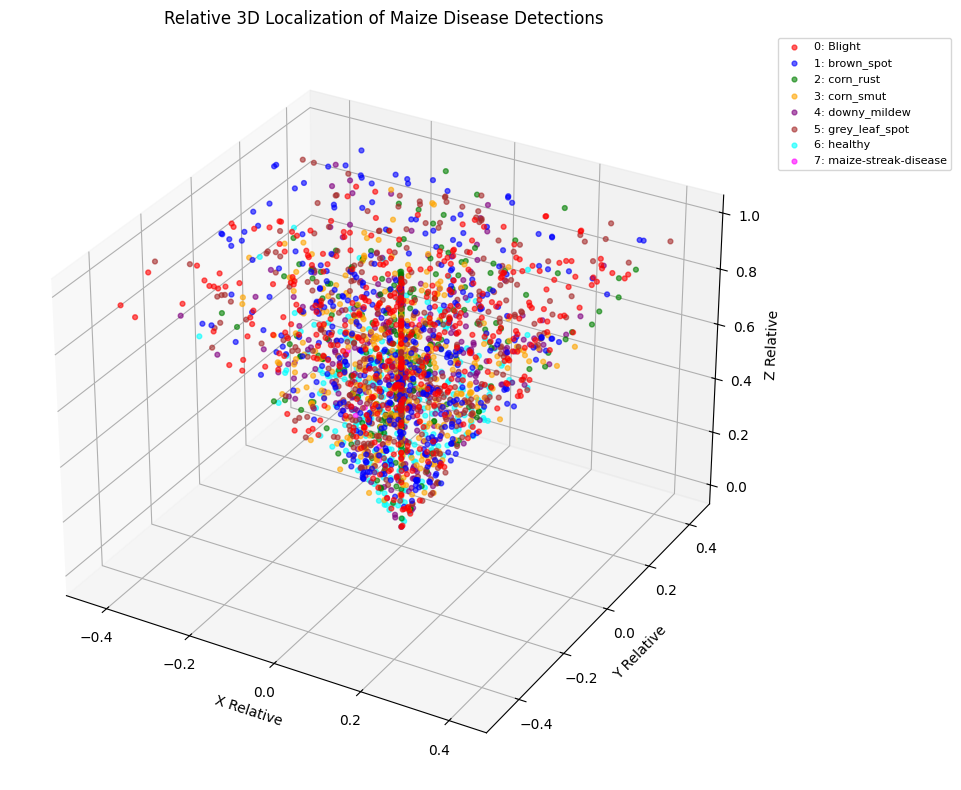

STEP 9.8 COMPLETE
Total detections plotted : 2903
Classes plotted          : 8
Figure saved             : /kaggle/working/maize_paper_results/3D_Results/3d_localization.png


In [23]:
# ============================================================
# STEP 9.8 — 3D LOCALIZATION VISUALIZATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

CSV_PATH = "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
FIG_PATH = "/kaggle/working/maize_paper_results/3D_Results/3d_localization.png"

df = pd.read_csv(CSV_PATH)

# ------------------------------------------------------------
# Class names and colors
# ------------------------------------------------------------
class_colors = {
    0: "red",
    1: "blue",
    2: "green",
    3: "orange",
    4: "purple",
    5: "brown",
    6: "cyan",
    7: "magenta"
}

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# ------------------------------------------------------------
# Plot each class
# ------------------------------------------------------------
for class_id, class_name in zip(
    sorted(df["class_id"].unique()),
    df.sort_values("class_id")["class_name"].unique()
):
    subset = df[df["class_id"] == class_id]

    ax.scatter(
        subset["X_relative"],
        subset["Y_relative"],
        subset["Z_relative"],
        label=f"{class_id}: {class_name}",
        c=class_colors.get(class_id, "gray"),
        s=12,
        alpha=0.6
    )

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------
ax.set_xlabel("X Relative")
ax.set_ylabel("Y Relative")
ax.set_zlabel("Z Relative")

ax.set_title("Relative 3D Localization of Maize Disease Detections")

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=8
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
plt.savefig(FIG_PATH, dpi=300, bbox_inches="tight")

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
plt.show()

print("=" * 75)
print("STEP 9.8 COMPLETE")
print("=" * 75)
print(f"Total detections plotted : {len(df)}")
print(f"Classes plotted          : {df['class_name'].nunique()}")
print(f"Figure saved             : {FIG_PATH}")

/tmp/ipykernel_24/1375972203.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


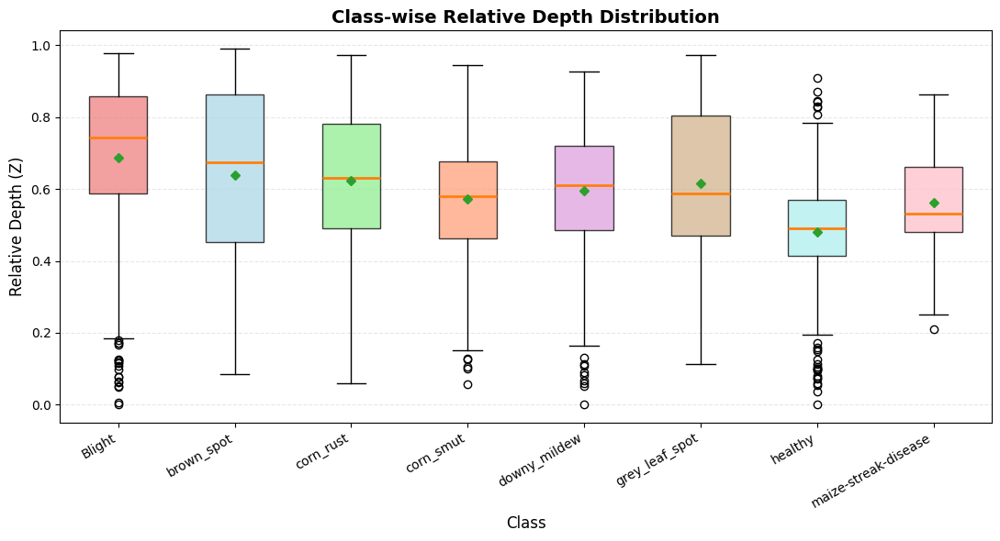

STEP 9.9 COMPLETE
Total detections : 2903
Classes plotted  : 8
Figure saved     : /kaggle/working/maize_paper_results/3D_Results/classwise_depth_distribution.png


In [24]:
# ============================================================
# STEP 9.9 — COLORFUL CLASS-WISE RELATIVE DEPTH BOXPLOT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/classwise_depth_distribution.png"
)

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

available_classes = [
    cls for cls in class_names
    if cls in df["class_name"].unique()
]

depth_data = [
    df.loc[df["class_name"] == cls, "Z_relative"].dropna()
    for cls in available_classes
]

# ------------------------------------------------------------
# Create colorful boxplot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    depth_data,
    labels=available_classes,
    patch_artist=True,
    showmeans=True,
    meanline=False
)

# Different color for each class
colors = [
    "lightcoral",
    "lightblue",
    "lightgreen",
    "lightsalmon",
    "plum",
    "tan",
    "paleturquoise",
    "pink"
]

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# Make median lines clearer
for median in bp["medians"]:
    median.set_linewidth(2)

# Mean markers
for mean in bp["means"]:
    mean.set_marker("D")
    mean.set_markersize(5)

# ------------------------------------------------------------
# Labels and formatting
# ------------------------------------------------------------
ax.set_xlabel("Class", fontsize=12)
ax.set_ylabel("Relative Depth (Z)", fontsize=12)
ax.set_title(
    "Class-wise Relative Depth Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.xticks(
    range(1, len(available_classes) + 1),
    available_classes,
    rotation=30,
    ha="right"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save high-resolution figure
# ------------------------------------------------------------
plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 80)
print("STEP 9.9 COMPLETE")
print("=" * 80)
print(f"Total detections : {len(df)}")
print(f"Classes plotted  : {len(available_classes)}")
print(f"Figure saved     : {FIG_PATH}")

SELECTED REPRESENTATIVE IMAGES
 class_id           class_name  confidence  Z_relative
        0               Blight    0.983937    0.512118
        1           brown_spot    0.950819    0.522530
        2            corn_rust    0.992984    0.573611
        3            corn_smut    0.986229    0.673106
        4         downy_mildew    0.993141    0.519956
        5       grey_leaf_spot    0.987393    0.623018
        6              healthy    0.993106    0.444437
        7 maize-streak-disease    0.992652    0.724909


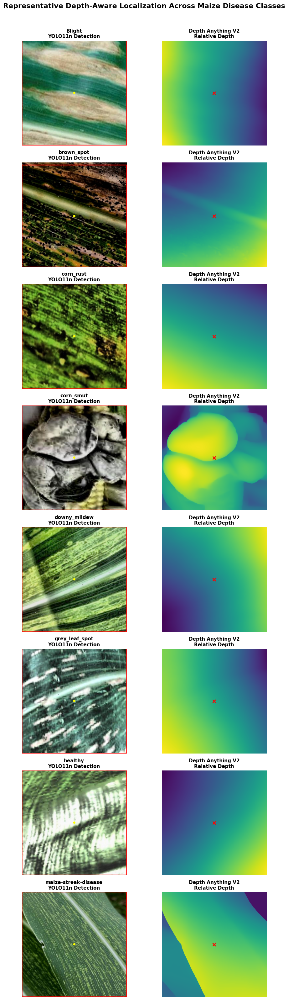


STEP 9.10 COMPLETE
Classes displayed : 8 / 8
Figure saved      : /kaggle/working/maize_paper_results/3D_Results/classwise_depth_maps.png


In [25]:
# ============================================================
# STEP 9.10 — REPRESENTATIVE DEPTH MAP FOR ALL 8 CLASSES
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

TEST_DIR = Path(
    "/kaggle/working/maize-disease-detection/images/test"
)

OUTPUT_DIR = Path(
    "/kaggle/working/maize_paper_results/3D_Results"
)

FIG_PATH = OUTPUT_DIR / "classwise_depth_maps.png"

# ------------------------------------------------------------
# Load localization results
# ------------------------------------------------------------
df = pd.read_csv(CSV_PATH)

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

# ------------------------------------------------------------
# Select ONE representative detection per class
# Prefer high-confidence detection
# ------------------------------------------------------------
representatives = []

for class_id, class_name in enumerate(class_names):

    subset = df[df["class_name"] == class_name].copy()

    if len(subset) == 0:
        print(f"WARNING: No detection found for {class_name}")
        continue

    # Select highest-confidence detection
    sample = subset.sort_values(
        "confidence",
        ascending=False
    ).iloc[0]

    representatives.append(sample)

rep_df = pd.DataFrame(representatives)

print("=" * 80)
print("SELECTED REPRESENTATIVE IMAGES")
print("=" * 80)

print(
    rep_df[
        ["class_id", "class_name", "confidence", "Z_relative"]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# Create 4 × 4 figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    8,
    2,
    figsize=(10, 32)
)

# ------------------------------------------------------------
# Process each class
# ------------------------------------------------------------
for row, (_, sample) in enumerate(rep_df.iterrows()):

    image_name = sample["image_name"]
    class_id = int(sample["class_id"])
    class_name = sample["class_name"]

    image_path = TEST_DIR / image_name

    # --------------------------------------------------------
    # Read image
    # --------------------------------------------------------
    image = Image.open(image_path).convert("RGB")

    image_np = np.array(image)

    H, W = image_np.shape[:2]

    # --------------------------------------------------------
    # YOLO bounding box
    # --------------------------------------------------------
    x1 = int(sample["x1"])
    y1 = int(sample["y1"])
    x2 = int(sample["x2"])
    y2 = int(sample["y2"])

    center_u = float(sample["center_u"])
    center_v = float(sample["center_v"])

    # --------------------------------------------------------
    # YOLO visualization
    # --------------------------------------------------------
    detection_img = image_np.copy()

    cv2.rectangle(
        detection_img,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        3
    )

    cv2.circle(
        detection_img,
        (int(center_u), int(center_v)),
        7,
        (255, 255, 0),
        -1
    )

    # --------------------------------------------------------
    # Depth Anything V2 inference
    # --------------------------------------------------------
    inputs = depth_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        outputs = depth_model(**inputs)

    predicted_depth = outputs.predicted_depth

    # --------------------------------------------------------
    # Resize depth to original image size
    # --------------------------------------------------------
    depth = torch.nn.functional.interpolate(
        predicted_depth.unsqueeze(1),
        size=(H, W),
        mode="bicubic",
        align_corners=False
    ).squeeze()

    depth = depth.cpu().numpy()

    # --------------------------------------------------------
    # Normalize relative depth
    # --------------------------------------------------------
    d_min = np.min(depth)
    d_max = np.max(depth)

    depth_norm = (
        (depth - d_min) /
        (d_max - d_min + 1e-8)
    )

    # --------------------------------------------------------
    # Depth visualization
    # --------------------------------------------------------
    ax1 = axes[row, 0]
    ax2 = axes[row, 1]

    ax1.imshow(detection_img)
    ax1.axis("off")

    ax1.set_title(
        f"{class_name}\nYOLO11n Detection",
        fontsize=11,
        fontweight="bold"
    )

    im = ax2.imshow(
        depth_norm,
        cmap="viridis"
    )

    # Disease center only
    ax2.scatter(
        center_u,
        center_v,
        s=50,
        c="red",
        marker="x",
        linewidths=2
    )

    ax2.axis("off")

    ax2.set_title(
        f"Depth Anything V2\nRelative Depth",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------
fig.suptitle(
    "Representative Depth-Aware Localization Across Maize Disease Classes",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.985]
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 80)
print("STEP 9.10 COMPLETE")
print("=" * 80)
print(f"Classes displayed : {len(rep_df)} / 8")
print(f"Figure saved      : {FIG_PATH}")

STEP 9.10 — CLASS-WISE DEPTH-AWARE LOCALIZATION
Total detections available: 2903

Selected representatives:
Blight                 Conf=0.984 | Z=0.512
brown_spot             Conf=0.951 | Z=0.523
corn_rust              Conf=0.993 | Z=0.574
corn_smut              Conf=0.986 | Z=0.673
downy_mildew           Conf=0.993 | Z=0.520
grey_leaf_spot         Conf=0.987 | Z=0.623
healthy                Conf=0.993 | Z=0.444
maize-streak-disease   Conf=0.993 | Z=0.725


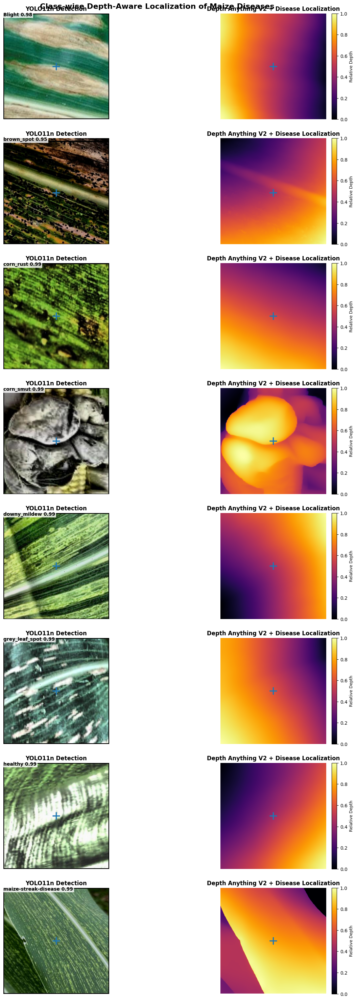


STEP 9.10 COMPLETE
Classes visualized: 8 / 8
Figure saved at:
/kaggle/working/maize_paper_results/3D_Results/classwise_depth_maps.png


In [26]:
# ============================================================
# STEP 9.10 — CLASS-WISE YOLO + DEPTH VISUALIZATION
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
import torch
from pathlib import Path

print("=" * 80)
print("STEP 9.10 — CLASS-WISE DEPTH-AWARE LOCALIZATION")
print("=" * 80)


# ============================================================
# 1. LOAD FULL 3D RESULTS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

df = pd.read_csv(CSV_PATH)

print(f"Total detections available: {len(df)}")


# ============================================================
# 2. CLASS ORDER
# ============================================================

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]


# ============================================================
# 3. SELECT ONE REPRESENTATIVE IMAGE PER CLASS
#    Highest-confidence detection
# ============================================================

representatives = []

for class_id, class_name in enumerate(class_names):

    class_df = df[
        df["class_name"] == class_name
    ].copy()

    if len(class_df) == 0:
        print(f"WARNING: {class_name} not found!")
        continue

    representative = class_df.loc[
        class_df["confidence"].idxmax()
    ]

    representatives.append(representative)


print("\nSelected representatives:")

for r in representatives:
    print(
        f"{r['class_name']:<22} "
        f"Conf={r['confidence']:.3f} | "
        f"Z={r['Z_relative']:.3f}"
    )


# ============================================================
# 4. CREATE FIGURE
#    8 classes × 2 panels
# ============================================================

fig, axes = plt.subplots(
    len(representatives),
    2,
    figsize=(12, 30)
)

if len(representatives) == 1:
    axes = np.expand_dims(axes, axis=0)


# ============================================================
# 5. PROCESS EACH CLASS
# ============================================================

for row, sample in enumerate(representatives):

    image_name = sample["image_name"]

    image_path = TEST_DIR / image_name

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    image_bgr = cv2.imread(
        str(image_path)
    )

    if image_bgr is None:
        print(
            f"Could not read: {image_name}"
        )
        continue

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    H, W = image_rgb.shape[:2]


    # ========================================================
    # YOLO BOUNDING BOX
    # ========================================================

    x1 = int(sample["x1"])
    y1 = int(sample["y1"])
    x2 = int(sample["x2"])
    y2 = int(sample["y2"])

    u = int(sample["center_u"])
    v = int(sample["center_v"])


    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    detection_img = image_rgb.copy()

    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2.5
    )

    axes[row, 0].imshow(
        detection_img
    )

    axes[row, 0].add_patch(
        rect
    )

    # Disease center
    axes[row, 0].plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )

    # Class + confidence
    axes[row, 0].text(
        x1,
        max(15, y1 - 8),
        f"{sample['class_name']} "
        f"{sample['confidence']:.2f}",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none",
            pad=2
        )
    )

    axes[row, 0].set_title(
        "YOLO11n Detection",
        fontsize=12,
        fontweight="bold"
    )

    axes[row, 0].axis("off")


    # ========================================================
    # PANEL 2 — DEPTH ANYTHING V2
    # ========================================================

    pil_image = Image.fromarray(
        image_rgb
    )

    depth_inputs = depth_processor(
        images=pil_image,
        return_tensors="pt"
    )

    depth_inputs = {
        key: value.to(device)
        for key, value in depth_inputs.items()
    }


    with torch.inference_mode():

        depth_outputs = depth_model(
            **depth_inputs
        )


    depth_raw = (
        depth_outputs.predicted_depth
        .squeeze()
        .detach()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Resize depth
    # --------------------------------------------------------

    depth_raw = cv2.resize(
        depth_raw,
        (W, H),
        interpolation=cv2.INTER_LINEAR
    )


    # --------------------------------------------------------
    # Normalize to relative depth [0,1]
    # --------------------------------------------------------

    d_min = np.nanmin(depth_raw)
    d_max = np.nanmax(depth_raw)

    if d_max > d_min:

        depth_norm = (
            depth_raw - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_raw
        )


    # --------------------------------------------------------
    # Display depth map
    # --------------------------------------------------------

    im = axes[row, 1].imshow(
        depth_norm,
        cmap="inferno"
    )


    # Disease center ONLY
    axes[row, 1].plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )


    axes[row, 1].set_title(
        "Depth Anything V2 + Disease Localization",
        fontsize=12,
        fontweight="bold"
    )

    axes[row, 1].axis("off")


    # --------------------------------------------------------
    # Colorbar for each depth map
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=axes[row, 1],
        fraction=0.046,
        pad=0.03
    )

    cbar.set_label(
        "Relative Depth",
        fontsize=9
    )


# ============================================================
# 6. OVERALL TITLE
# ============================================================

fig.suptitle(
    "Class-wise Depth-Aware Localization of Maize Diseases",
    fontsize=16,
    fontweight="bold",
    y=0.995
)


# ============================================================
# 7. COMPACT LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.03,
    right=0.95,
    bottom=0.02,
    top=0.985,
    wspace=0.08,
    hspace=0.18
)


# ============================================================
# 8. SAVE
# ============================================================

FIG_PATH = (
    PAPER_RESULTS
    / "3D_Results"
    / "classwise_depth_maps.png"
)

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# 9. DISPLAY
# ============================================================

plt.show()


print("\n" + "=" * 80)
print("STEP 9.10 COMPLETE")
print("=" * 80)

print(
    f"Classes visualized: "
    f"{len(representatives)} / 8"
)

print(
    f"Figure saved at:\n{FIG_PATH}"
)

STEP 9.10 — PAPER-READY CLASS-WISE DEPTH-AWARE LOCALIZATION
Total detections available: 2903

Selected representatives:
Blight                 Conf=0.984 | Z=0.512
brown_spot             Conf=0.951 | Z=0.523
corn_rust              Conf=0.993 | Z=0.574
corn_smut              Conf=0.986 | Z=0.673
downy_mildew           Conf=0.993 | Z=0.520
grey_leaf_spot         Conf=0.987 | Z=0.623
healthy                Conf=0.993 | Z=0.444
maize-streak-disease   Conf=0.993 | Z=0.725


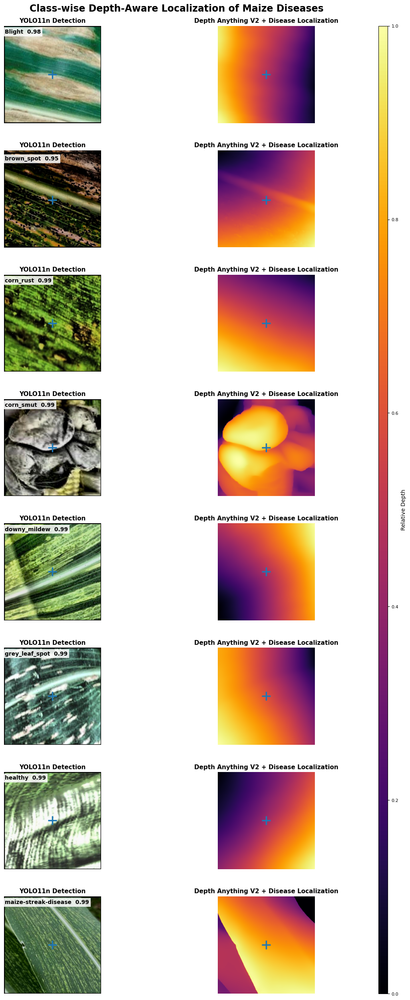


STEP 9.10 COMPLETE
Classes visualized: 8 / 8
Figure saved at:
/kaggle/working/maize_paper_results/3D_Results/classwise_depth_maps.png


In [27]:
# ============================================================
# STEP 9.10 — PAPER-READY CLASS-WISE YOLO + DEPTH VISUALIZATION
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

print("=" * 80)
print("STEP 9.10 — PAPER-READY CLASS-WISE DEPTH-AWARE LOCALIZATION")
print("=" * 80)


# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_PATH = (
    PAPER_RESULTS
    / "3D_Results"
    / "classwise_depth_maps.png"
)

df = pd.read_csv(CSV_PATH)

print(f"Total detections available: {len(df)}")


# ============================================================
# 2. CLASS ORDER
# ============================================================

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]


# ============================================================
# 3. SELECT ONE REPRESENTATIVE IMAGE PER CLASS
# ============================================================

representatives = []

for class_id, class_name in enumerate(class_names):

    class_df = df[
        df["class_name"] == class_name
    ].copy()

    if len(class_df) == 0:
        print(f"WARNING: {class_name} not found!")
        continue

    # Highest-confidence detection
    representative = class_df.loc[
        class_df["confidence"].idxmax()
    ]

    representatives.append(representative)


print("\nSelected representatives:")

for r in representatives:
    print(
        f"{r['class_name']:<22} "
        f"Conf={r['confidence']:.3f} | "
        f"Z={r['Z_relative']:.3f}"
    )


# ============================================================
# 4. FIGURE LAYOUT
#
# 8 rows × 2 image panels
# One shared colorbar on the right
# ============================================================

n = len(representatives)

fig = plt.figure(
    figsize=(12, 3.15 * n)
)

gs = GridSpec(
    nrows=n,
    ncols=3,
    figure=fig,
    width_ratios=[1, 1, 0.045],
    height_ratios=[1] * n,
    wspace=0.08,
    hspace=0.28
)


# Store last depth image for shared colorbar
last_depth_im = None


# ============================================================
# 5. PROCESS EACH CLASS
# ============================================================

for row, sample in enumerate(representatives):

    image_name = sample["image_name"]

    image_path = TEST_DIR / image_name

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    image_bgr = cv2.imread(
        str(image_path)
    )

    if image_bgr is None:
        print(f"Could not read: {image_name}")
        continue

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    H, W = image_rgb.shape[:2]


    # ========================================================
    # YOLO BOUNDING BOX
    # ========================================================

    x1 = int(sample["x1"])
    y1 = int(sample["y1"])
    x2 = int(sample["x2"])
    y2 = int(sample["y2"])

    u = int(sample["center_u"])
    v = int(sample["center_v"])


    # ========================================================
    # CREATE AXES
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row, 1]
    )


    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(
        image_rgb
    )

    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2.5
    )

    ax_yolo.add_patch(
        rect
    )


    # Disease center
    ax_yolo.plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )


    # --------------------------------------------------------
    # Label
    # --------------------------------------------------------

    label_y = y1 + 20

    ax_yolo.text(
        x1 + 5,
        label_y,
        f"{sample['class_name']}  "
        f"{sample['confidence']:.2f}",
        fontsize=10,
        fontweight="bold",
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.85,
            edgecolor="none",
            pad=3
        )
    )


    ax_yolo.set_title(
        "YOLO11n Detection",
        fontsize=11,
        fontweight="bold",
        pad=6
    )

    ax_yolo.set_xlim(
        0,
        W
    )

    ax_yolo.set_ylim(
        H,
        0
    )

    ax_yolo.set_aspect(
        "equal"
    )

    ax_yolo.axis("off")


    # ========================================================
    # PANEL 2 — DEPTH ANYTHING V2
    # ========================================================

    pil_image = Image.fromarray(
        image_rgb
    )

    depth_inputs = depth_processor(
        images=pil_image,
        return_tensors="pt"
    )

    depth_inputs = {
        key: value.to(device)
        for key, value in depth_inputs.items()
    }


    with torch.inference_mode():

        depth_outputs = depth_model(
            **depth_inputs
        )


    depth_raw = (
        depth_outputs.predicted_depth
        .squeeze()
        .detach()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Resize depth map
    # --------------------------------------------------------

    depth_raw = cv2.resize(
        depth_raw,
        (W, H),
        interpolation=cv2.INTER_LINEAR
    )


    # --------------------------------------------------------
    # Normalize to [0,1]
    # --------------------------------------------------------

    d_min = np.nanmin(
        depth_raw
    )

    d_max = np.nanmax(
        depth_raw
    )

    if d_max > d_min:

        depth_norm = (
            depth_raw - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_raw
        )


    # ========================================================
    # DISPLAY DEPTH MAP
    # ========================================================

    last_depth_im = ax_depth.imshow(
        depth_norm,
        cmap="inferno",
        vmin=0,
        vmax=1
    )


    # Disease center ONLY
    ax_depth.plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )


    ax_depth.set_title(
        "Depth Anything V2 + Disease Localization",
        fontsize=11,
        fontweight="bold",
        pad=6
    )

    ax_depth.set_xlim(
        0,
        W
    )

    ax_depth.set_ylim(
        H,
        0
    )

    ax_depth.set_aspect(
        "equal"
    )

    ax_depth.axis("off")


# ============================================================
# 6. SHARED COLORBAR
# ============================================================

cbar_ax = fig.add_subplot(
    gs[:, 2]
)

cbar = fig.colorbar(
    last_depth_im,
    cax=cbar_ax
)

cbar.set_label(
    "Relative Depth",
    fontsize=10
)

cbar.ax.tick_params(
    labelsize=8
)


# ============================================================
# 7. MAIN TITLE
# ============================================================

fig.suptitle(
    "Class-wise Depth-Aware Localization of Maize Diseases",
    fontsize=17,
    fontweight="bold",
    y=0.997
)


# ============================================================
# 8. FINAL LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.03,
    right=0.94,
    top=0.975,
    bottom=0.015
)


# ============================================================
# 9. SAVE
# ============================================================

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# 10. DISPLAY
# ============================================================

plt.show()


print("\n" + "=" * 80)
print("STEP 9.10 COMPLETE")
print("=" * 80)

print(
    f"Classes visualized: "
    f"{len(representatives)} / 8"
)

print(
    f"Figure saved at:\n{FIG_PATH}"
)

STEP 9.10 — CLASS-WISE DEPTH-AWARE LOCALIZATION
Total detections available: 2903

Selected representatives:
Blight                 Conf=0.984 | Z=0.512
brown_spot             Conf=0.951 | Z=0.523
corn_rust              Conf=0.993 | Z=0.574
corn_smut              Conf=0.986 | Z=0.673
downy_mildew           Conf=0.993 | Z=0.520
grey_leaf_spot         Conf=0.987 | Z=0.623
healthy                Conf=0.993 | Z=0.444
maize-streak-disease   Conf=0.993 | Z=0.725


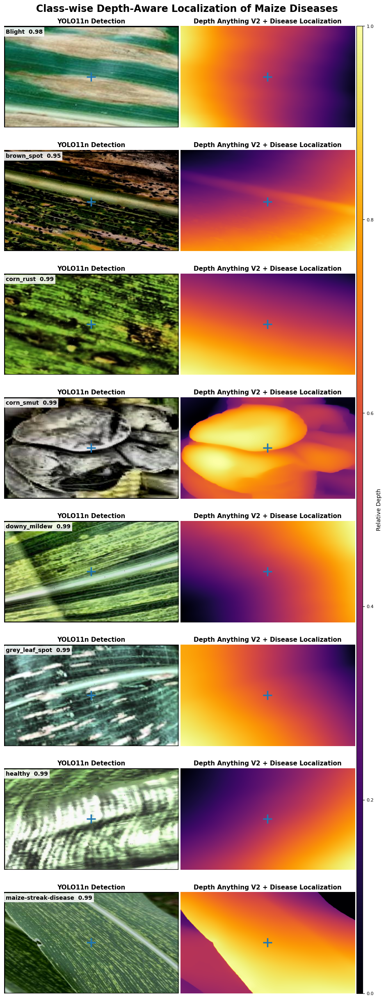


STEP 9.10 COMPLETE
Classes visualized: 8 / 8
Figure saved at:
/kaggle/working/maize_paper_results/3D_Results/classwise_depth_maps.png


In [28]:
# ============================================================
# STEP 9.10 — PAPER-READY CLASS-WISE YOLO + DEPTH VISUALIZATION
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

print("=" * 80)
print("STEP 9.10 — CLASS-WISE DEPTH-AWARE LOCALIZATION")
print("=" * 80)


# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_PATH = (
    PAPER_RESULTS
    / "3D_Results"
    / "classwise_depth_maps.png"
)

df = pd.read_csv(CSV_PATH)

print(f"Total detections available: {len(df)}")


# ============================================================
# 2. CLASS ORDER
# ============================================================

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]


# ============================================================
# 3. SELECT ONE REPRESENTATIVE IMAGE PER CLASS
# ============================================================

representatives = []

for class_id, class_name in enumerate(class_names):

    class_df = df[
        df["class_name"] == class_name
    ].copy()

    if len(class_df) == 0:
        print(f"WARNING: {class_name} not found!")
        continue

    # Highest-confidence detection
    representative = class_df.loc[
        class_df["confidence"].idxmax()
    ]

    representatives.append(representative)


print("\nSelected representatives:")

for r in representatives:
    print(
        f"{r['class_name']:<22} "
        f"Conf={r['confidence']:.3f} | "
        f"Z={r['Z_relative']:.3f}"
    )


# ============================================================
# 4. FIGURE LAYOUT
# ============================================================

n = len(representatives)

fig = plt.figure(
    figsize=(9.2, 3.05 * n)
)

gs = GridSpec(
    nrows=n,
    ncols=3,
    figure=fig,

    # YOLO | DEPTH | COLORBAR
    width_ratios=[1, 1, 0.035],

    height_ratios=[1] * n,

    # Very small horizontal gap
    wspace=0.015,

    # Moderate vertical gap between classes
    hspace=0.22
)

last_depth_im = None


# ============================================================
# 5. PROCESS EACH CLASS
# ============================================================

for row, sample in enumerate(representatives):

    image_name = sample["image_name"]

    image_path = TEST_DIR / image_name


    # ========================================================
    # LOAD IMAGE
    # ========================================================

    image_bgr = cv2.imread(
        str(image_path)
    )

    if image_bgr is None:
        print(
            f"Could not read: {image_name}"
        )
        continue

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    H, W = image_rgb.shape[:2]


    # ========================================================
    # YOLO BOUNDING BOX
    # ========================================================

    x1 = int(sample["x1"])
    y1 = int(sample["y1"])
    x2 = int(sample["x2"])
    y2 = int(sample["y2"])

    u = int(sample["center_u"])
    v = int(sample["center_v"])


    # ========================================================
    # CREATE TWO IMAGE AXES
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row, 1]
    )


    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(
        image_rgb
    )


    # Bounding box
    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2.5
    )

    ax_yolo.add_patch(
        rect
    )


    # Disease center
    ax_yolo.plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )


    # --------------------------------------------------------
    # Class + confidence label
    # --------------------------------------------------------

    ax_yolo.text(
        x1 + 5,
        max(18, y1 + 5),
        f"{sample['class_name']}  "
        f"{sample['confidence']:.2f}",
        fontsize=10,
        fontweight="bold",
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.85,
            edgecolor="none",
            pad=3
        )
    )


    ax_yolo.set_title(
        "YOLO11n Detection",
        fontsize=11,
        fontweight="bold",
        pad=5
    )


    # Important:
    # Do NOT use equal aspect here.
    # This prevents unnecessary horizontal spacing.
    ax_yolo.set_aspect(
        "auto"
    )

    ax_yolo.axis("off")


    # ========================================================
    # PANEL 2 — DEPTH ANYTHING V2
    # ========================================================

    pil_image = Image.fromarray(
        image_rgb
    )


    depth_inputs = depth_processor(
        images=pil_image,
        return_tensors="pt"
    )


    depth_inputs = {
        key: value.to(device)
        for key, value in depth_inputs.items()
    }


    # --------------------------------------------------------
    # Depth inference
    # --------------------------------------------------------

    with torch.inference_mode():

        depth_outputs = depth_model(
            **depth_inputs
        )


    depth_raw = (
        depth_outputs.predicted_depth
        .squeeze()
        .detach()
        .cpu()
        .numpy()
    )


    # ========================================================
    # RESIZE DEPTH MAP
    # ========================================================

    depth_raw = cv2.resize(
        depth_raw,
        (W, H),
        interpolation=cv2.INTER_LINEAR
    )


    # ========================================================
    # NORMALIZE TO RELATIVE DEPTH [0,1]
    # ========================================================

    d_min = np.nanmin(
        depth_raw
    )

    d_max = np.nanmax(
        depth_raw
    )


    if d_max > d_min:

        depth_norm = (
            depth_raw - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_raw
        )


    # ========================================================
    # DISPLAY DEPTH MAP
    # ========================================================

    last_depth_im = ax_depth.imshow(
        depth_norm,
        cmap="inferno",
        vmin=0,
        vmax=1
    )


    # Disease center ONLY
    ax_depth.plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )


    ax_depth.set_title(
        "Depth Anything V2 + Disease Localization",
        fontsize=11,
        fontweight="bold",
        pad=5
    )


    ax_depth.set_aspect(
        "auto"
    )

    ax_depth.axis("off")


# ============================================================
# 6. SHARED COLORBAR
# ============================================================

cbar_ax = fig.add_subplot(
    gs[:, 2]
)


cbar = fig.colorbar(
    last_depth_im,
    cax=cbar_ax
)


cbar.set_label(
    "Relative Depth",
    fontsize=10
)


cbar.ax.tick_params(
    labelsize=8
)


# ============================================================
# 7. OVERALL TITLE
# ============================================================

fig.suptitle(
    "Class-wise Depth-Aware Localization of Maize Diseases",
    fontsize=17,
    fontweight="bold",
    y=0.997
)


# ============================================================
# 8. FINAL LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.015,
    right=0.965,
    top=0.975,
    bottom=0.01,

    # Very small gap between YOLO and Depth
    wspace=0.015,

    # Vertical gap between classes
    hspace=0.22
)


# ============================================================
# 9. SAVE HIGH-RESOLUTION FIGURE
# ============================================================

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# 10. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 9.10 COMPLETE")
print("=" * 80)

print(
    f"Classes visualized: "
    f"{len(representatives)} / {len(class_names)}"
)

print(
    f"Figure saved at:\n{FIG_PATH}"
)

FINAL PAPER RESULTS EXPORT
YOLO11n + Depth Anything V2 + Relative 3D Localization

Loading result files...
3D detections : 2903
Training rows : 120

Copying existing YOLO results...
Copied: best_training_epoch.csv

Searching for confusion matrix...


TABLE 1 — OVERALL YOLO11n TEST PERFORMANCE
Overall YOLO metrics not available.


TABLE 2 — CLASS-WISE YOLO11n TEST PERFORMANCE
Class-wise YOLO metrics not available.

Generating Figure 1 — Training & Validation Loss...


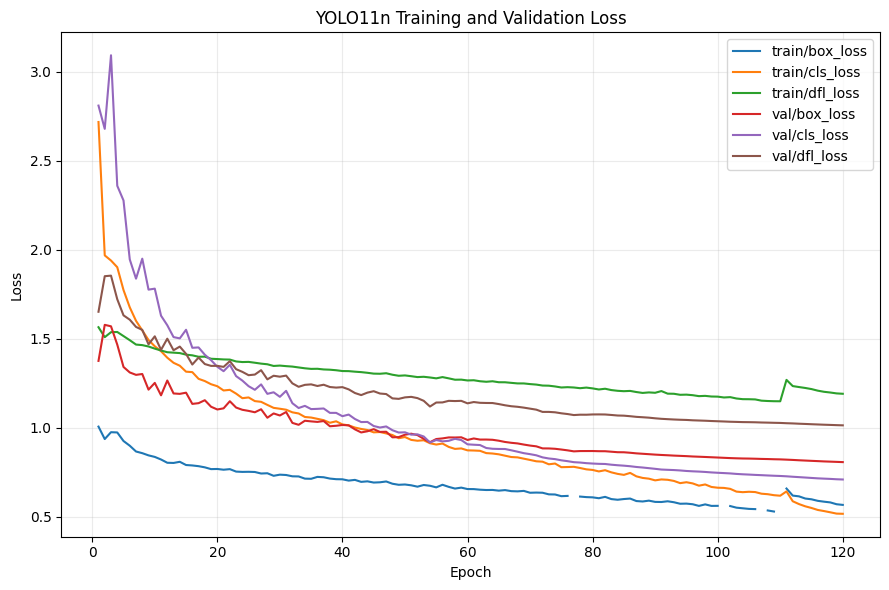

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_1_training_validation_loss.png

Generating Figure 2 — Detection Metrics...


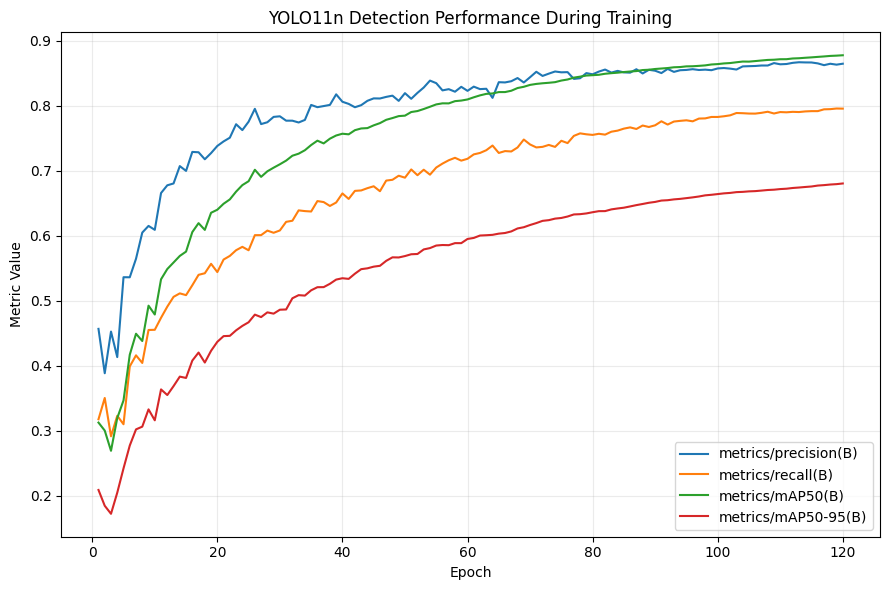

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_2_detection_metrics.png

Generating Figure 3 — Learning Rate...


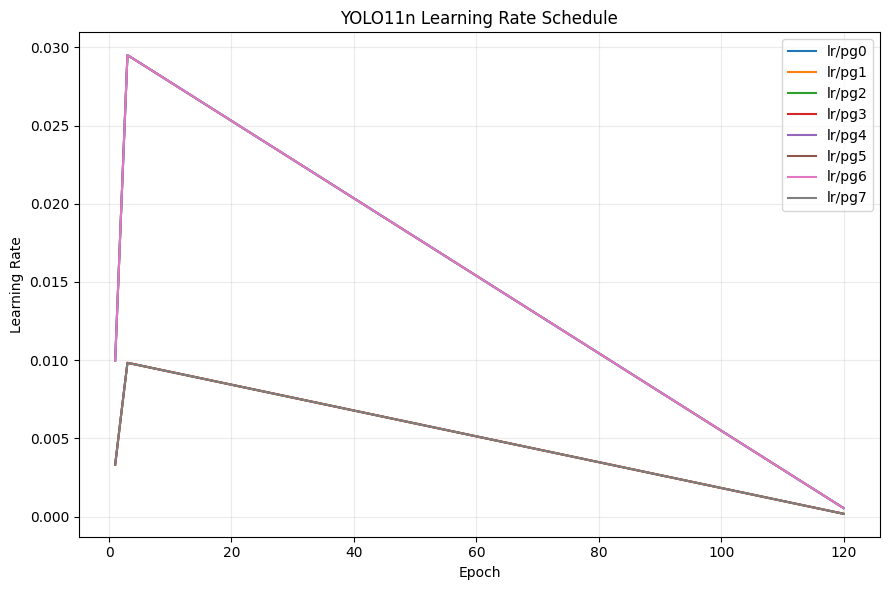

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_3_learning_rate.png

Calculating class-wise relative depth statistics...


TABLE 3 — CLASS-WISE RELATIVE DEPTH STATISTICS


,class_name,detection_count,mean_Z,median_Z,std_Z,min_Z,max_Z
0,Blight,434,0.68710,0.74251,0.21878,0.00000,0.97748
1,brown_spot,376,0.63794,0.67442,0.23765,0.08490,0.99115
2,corn_rust,345,0.62310,0.63053,0.19455,0.06013,0.97309
3,corn_smut,429,0.57210,0.58037,0.16198,0.05675,0.94520
4,downy_mildew,342,0.59574,0.61174,0.18494,0.00000,0.92680
5,grey_leaf_spot,457,0.61648,0.58637,0.20634,0.11339,0.97338
6,healthy,443,0.48110,0.48936,0.14831,0.00062,0.90913
7,maize-streak-disease,77,0.56184,0.53082,0.13612,0.21022,0.86331



Generating Figure 4 — Class-wise Relative Depth Distribution...


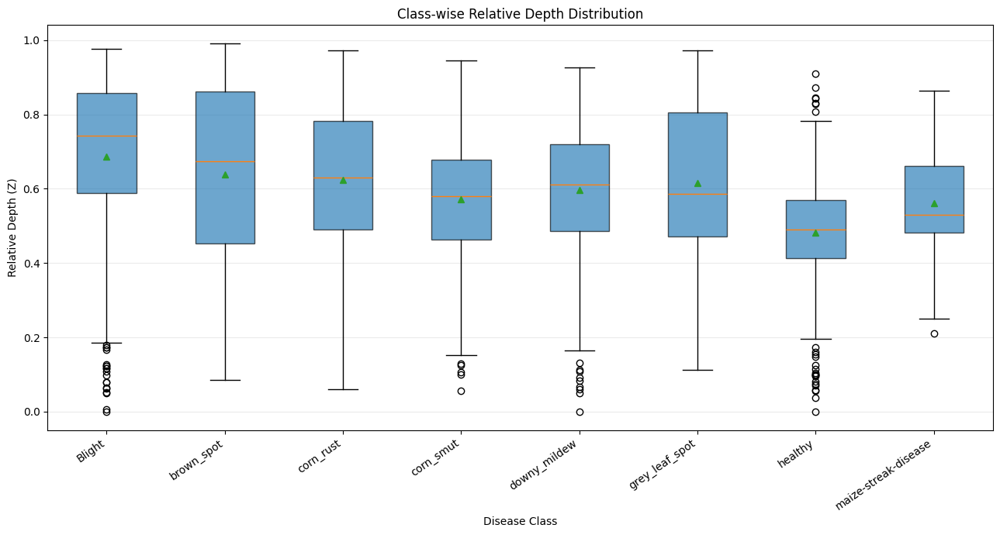

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_4_classwise_relative_depth_distribution.png

Calculating class-wise 3D spatial statistics...


TABLE 4 — CLASS-WISE RELATIVE 3D SPATIAL STATISTICS


,class_name,detection_count,mean_X,median_X,std_X,mean_Y,median_Y,std_Y,mean_Z,median_Z,std_Z
0,Blight,434,0.00771,-0.00026,0.16879,0.00465,-0.00051,0.15500,0.68710,0.74251,0.21878
1,brown_spot,376,-0.00770,-0.00043,0.16114,0.00857,-0.00090,0.17150,0.63794,0.67442,0.23765
2,corn_rust,345,0.00684,-0.00042,0.09938,0.00802,-0.00044,0.11433,0.62310,0.63053,0.19455
3,corn_smut,429,-0.00664,-0.00047,0.11100,0.00238,-0.00047,0.10800,0.57210,0.58037,0.16198
4,downy_mildew,342,-0.00236,-0.00046,0.11769,0.00961,-0.00047,0.14312,0.59574,0.61174,0.18494
5,grey_leaf_spot,457,-0.00192,-0.00042,0.14115,0.01108,-0.00042,0.14608,0.61648,0.58637,0.20634
6,healthy,443,-0.00058,-0.00039,0.08317,-0.00036,-0.00039,0.07921,0.48110,0.48936,0.14831
7,maize-streak-disease,77,-0.00095,-0.00041,0.00775,-0.00606,-0.00042,0.04882,0.56184,0.53082,0.13612




TABLE 5 — OVERALL RELATIVE 3D SUMMARY


,Metric,Value
0,Total detections,2903.00000
1,Images with detections,1493.00000
2,Number of disease classes,8.00000
3,Mean X_relative,-0.00071
4,Median X_relative,-0.00042
5,Mean Y_relative,0.00577
6,Median Y_relative,-0.00043
7,Mean Z_relative,0.59950
8,Median Z_relative,0.59888
9,Std Z_relative,0.20269



Generating Figure 5 — Relative 3D Localization...


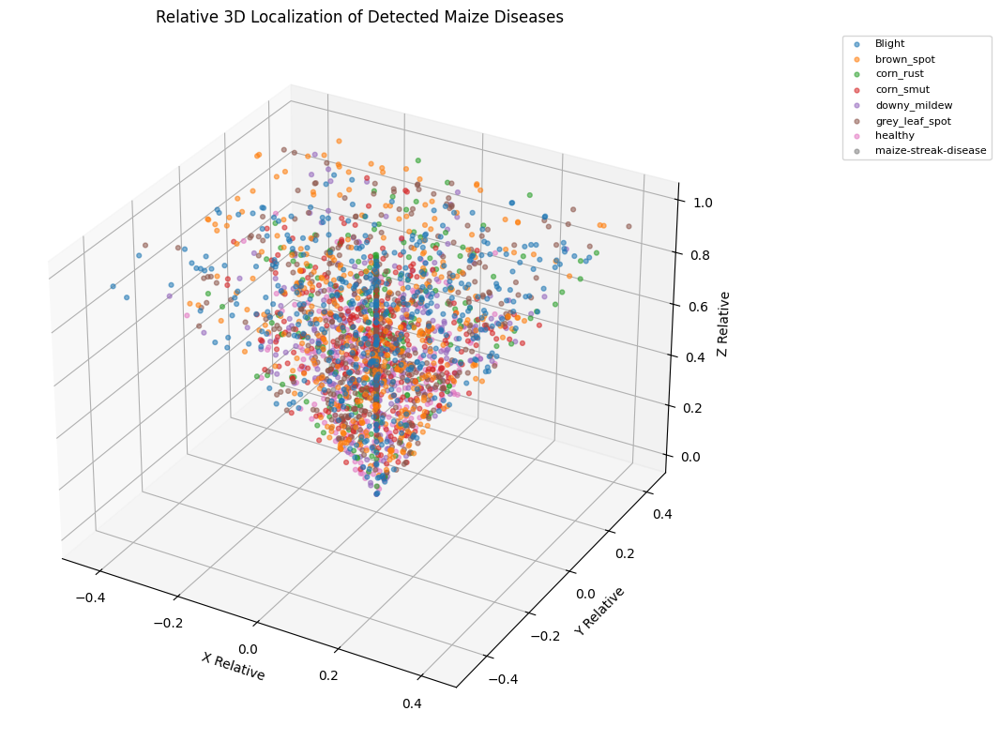

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_5_relative_3D_localization.png

Generating Figure 6 — Class-wise 3D Centroid Distribution...


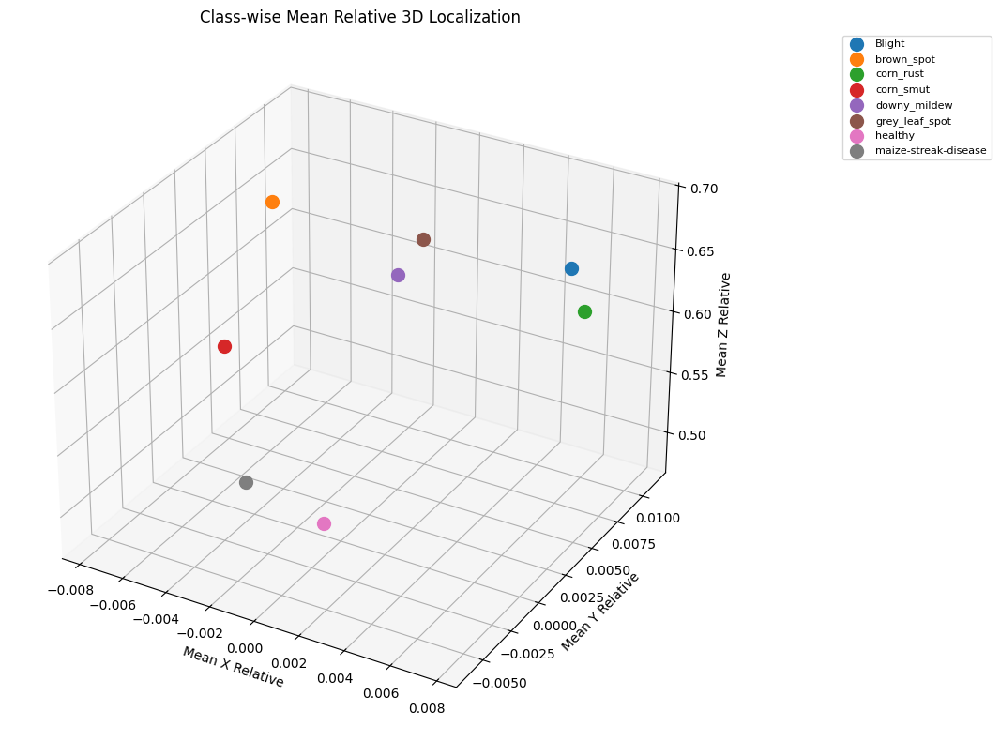

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_6_classwise_3D_centroids.png

Generating Figure 7 — Confidence vs Relative Depth...


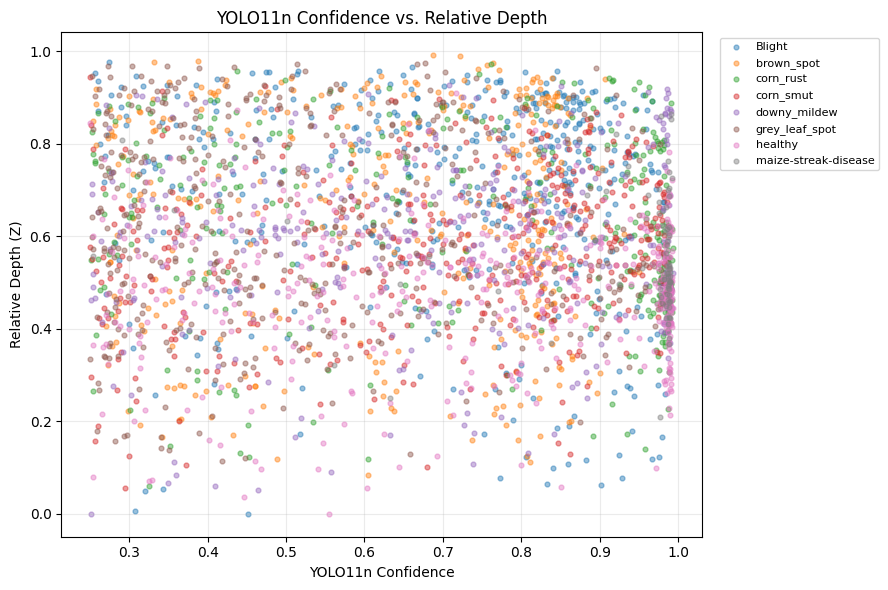

Saved: /kaggle/working/maize_paper_final_results/Figures/Figure_7_confidence_vs_relative_depth.png

Copied existing class-wise depth-aware localization figure.
Copied original 3D localization figure.


CREATING FINAL ZIP

ZIP created:
/kaggle/working/maize_paper_final_results.zip


FINAL PAPER RESULTS
maize_paper_final_results/
    README_paper_results.txt
    Figures/
        Figure_1_training_validation_loss.png
        Figure_2_detection_metrics.png
        Figure_3_learning_rate.png
        Figure_4_classwise_relative_depth_distribution.png
        Figure_5_relative_3D_localization.png
        Figure_6_classwise_3D_centroids.png
        Figure_7_confidence_vs_relative_depth.png
        Figure_8_classwise_depth_aware_localization.png
        Figure_9_original_3D_localization.png
    Tables/
        Table_3_classwise_relative_depth_statistics.csv
        Table_4_classwise_relative_3D_statistics.csv
        Table_5_overall_relative_3D_summary.csv
    3D_Results/
        3d_localizatio

In [29]:
# ============================================================
# FINAL PAPER RESULTS EXPORT
# YOLO11n + Depth Anything V2 + Relative 3D Localization
# ============================================================

import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("=" * 100)
print("FINAL PAPER RESULTS EXPORT")
print("YOLO11n + Depth Anything V2 + Relative 3D Localization")
print("=" * 100)


# ============================================================
# 1. DEFINE PATHS
# ============================================================

BASE_RESULTS = Path(
    "/kaggle/working/maize_paper_results"
)

YOLO_SOURCE = BASE_RESULTS / "YOLO_Results"
THREE_D_SOURCE = BASE_RESULTS / "3D_Results"

# Final separate folder
FINAL_RESULTS = Path(
    "/kaggle/working/maize_paper_final_results"
)

FINAL_YOLO = FINAL_RESULTS / "YOLO_Results"
FINAL_3D = FINAL_RESULTS / "3D_Results"

FINAL_TABLES = FINAL_RESULTS / "Tables"
FINAL_FIGURES = FINAL_RESULTS / "Figures"

# Create directories
for folder in [
    FINAL_RESULTS,
    FINAL_YOLO,
    FINAL_3D,
    FINAL_TABLES,
    FINAL_FIGURES
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 2. LOAD RESULTS
# ============================================================

THREE_D_CSV = (
    THREE_D_SOURCE /
    "3d_localization.csv"
)

TRAINING_CSV = Path(
    "/kaggle/input/datasets/siam2461/result/results.csv"
)

print("\nLoading result files...")

df_3d = pd.read_csv(
    THREE_D_CSV
)

df_training = pd.read_csv(
    TRAINING_CSV
)

print(
    f"3D detections : {len(df_3d)}"
)

print(
    f"Training rows : {len(df_training)}"
)


# ============================================================
# 3. CLASS ORDER
# ============================================================

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]


# ============================================================
# 4. COPY EXISTING IMPORTANT YOLO RESULTS
# ============================================================

print("\nCopying existing YOLO results...")

# Existing CSV / TXT files
for filename in [
    "overall_metrics.csv",
    "classwise_metrics.csv",
    "YOLO_test_summary.txt",
    "best_training_epoch.csv"
]:

    source = YOLO_SOURCE / filename

    if source.exists():

        shutil.copy2(
            source,
            FINAL_YOLO / filename
        )

        print(
            f"Copied: {filename}"
        )


# ============================================================
# 5. COPY EXISTING CONFUSION MATRIX
# ============================================================

print("\nSearching for confusion matrix...")

confusion_files = list(
    YOLO_SOURCE.rglob(
        "confusion_matrix*.png"
    )
)

if confusion_files:

    source = confusion_files[0]

    shutil.copy2(
        source,
        FINAL_FIGURES /
        "confusion_matrix.png"
    )

    print(
        f"Confusion matrix copied from:\n{source}"
    )

else:

    print(
        "WARNING: confusion matrix image not found."
    )


# ============================================================
# 6. LOAD OVERALL YOLO METRICS
# ============================================================

overall_metrics_path = (
    YOLO_SOURCE /
    "overall_metrics.csv"
)

classwise_metrics_path = (
    YOLO_SOURCE /
    "classwise_metrics.csv"
)

if overall_metrics_path.exists():

    overall_yolo = pd.read_csv(
        overall_metrics_path
    )

else:

    overall_yolo = pd.DataFrame()


if classwise_metrics_path.exists():

    classwise_yolo = pd.read_csv(
        classwise_metrics_path
    )

else:

    classwise_yolo = pd.DataFrame()


# ============================================================
# 7. SAVE / PRINT OVERALL YOLO TABLE
# ============================================================

print("\n")
print("=" * 100)
print("TABLE 1 — OVERALL YOLO11n TEST PERFORMANCE")
print("=" * 100)

if len(overall_yolo) > 0:

    display(
        overall_yolo
    )

    overall_yolo.to_csv(
        FINAL_TABLES /
        "Table_1_overall_YOLO11n_metrics.csv",
        index=False
    )

else:

    print(
        "Overall YOLO metrics not available."
    )


# ============================================================
# 8. SAVE / PRINT CLASS-WISE YOLO TABLE
# ============================================================

print("\n")
print("=" * 100)
print("TABLE 2 — CLASS-WISE YOLO11n TEST PERFORMANCE")
print("=" * 100)

if len(classwise_yolo) > 0:

    display(
        classwise_yolo
    )

    classwise_yolo.to_csv(
        FINAL_TABLES /
        "Table_2_classwise_YOLO11n_metrics.csv",
        index=False
    )

else:

    print(
        "Class-wise YOLO metrics not available."
    )


# ============================================================
# 9. TRAINING / VALIDATION LOSS FIGURE
# ============================================================

print("\nGenerating Figure 1 — Training & Validation Loss...")

loss_candidates = [
    c for c in df_training.columns
    if "loss" in c.lower()
]

train_loss_cols = [
    c for c in loss_candidates
    if "train" in c.lower()
]

val_loss_cols = [
    c for c in loss_candidates
    if "val" in c.lower()
]

plt.figure(
    figsize=(9, 6)
)

for col in train_loss_cols:

    plt.plot(
        df_training.index + 1,
        df_training[col],
        label=col
    )

for col in val_loss_cols:

    plt.plot(
        df_training.index + 1,
        df_training[col],
        label=col
    )

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "YOLO11n Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

loss_fig = (
    FINAL_FIGURES /
    "Figure_1_training_validation_loss.png"
)

plt.savefig(
    loss_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {loss_fig}"
)


# ============================================================
# 10. DETECTION METRICS FIGURE
# ============================================================

print("\nGenerating Figure 2 — Detection Metrics...")

metric_candidates = []

for col in df_training.columns:

    col_lower = col.lower()

    if any(
        key in col_lower
        for key in [
            "precision",
            "recall",
            "map50",
            "map50-95",
            "map_50",
            "map_50-95"
        ]
    ):

        metric_candidates.append(col)


plt.figure(
    figsize=(9, 6)
)

for col in metric_candidates:

    plt.plot(
        df_training.index + 1,
        df_training[col],
        label=col
    )

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Metric Value"
)

plt.title(
    "YOLO11n Detection Performance During Training"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

metrics_fig = (
    FINAL_FIGURES /
    "Figure_2_detection_metrics.png"
)

plt.savefig(
    metrics_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {metrics_fig}"
)


# ============================================================
# 11. LEARNING RATE FIGURE
# ============================================================

print("\nGenerating Figure 3 — Learning Rate...")

lr_cols = [
    c for c in df_training.columns
    if "lr/" in c.lower()
    or c.lower().startswith("lr")
    or "learning_rate" in c.lower()
]

plt.figure(
    figsize=(9, 6)
)

for col in lr_cols:

    plt.plot(
        df_training.index + 1,
        df_training[col],
        label=col
    )

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Learning Rate"
)

plt.title(
    "YOLO11n Learning Rate Schedule"
)

if lr_cols:
    plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

lr_fig = (
    FINAL_FIGURES /
    "Figure_3_learning_rate.png"
)

plt.savefig(
    lr_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {lr_fig}"
)


# ============================================================
# 12. CLASS-WISE DEPTH STATISTICS
# ============================================================

print("\nCalculating class-wise relative depth statistics...")

depth_stats = (
    df_3d
    .groupby(
        "class_name"
    )["Z_relative"]
    .agg(
        detection_count="count",
        mean_Z="mean",
        median_Z="median",
        std_Z="std",
        min_Z="min",
        max_Z="max"
    )
    .reindex(
        class_names
    )
    .reset_index()
)

depth_stats = depth_stats.round(
    5
)


# Save
depth_stats.to_csv(
    FINAL_TABLES /
    "Table_3_classwise_relative_depth_statistics.csv",
    index=False
)

print("\n")
print("=" * 100)
print("TABLE 3 — CLASS-WISE RELATIVE DEPTH STATISTICS")
print("=" * 100)

display(
    depth_stats
)


# ============================================================
# 13. CLASS-WISE RELATIVE DEPTH BOX PLOT
# ============================================================

print("\nGenerating Figure 4 — Class-wise Relative Depth Distribution...")

depth_data = []

labels = []

for class_name in class_names:

    values = df_3d.loc[
        df_3d["class_name"] == class_name,
        "Z_relative"
    ].dropna().values

    if len(values) > 0:

        depth_data.append(
            values
        )

        labels.append(
            class_name
        )


plt.figure(
    figsize=(13, 7)
)

bp = plt.boxplot(
    depth_data,
    patch_artist=True,
    showmeans=True
)

# Use different default matplotlib colors
for i, patch in enumerate(
    bp["boxes"]
):

    patch.set_alpha(
        0.65
    )


plt.xticks(
    range(
        1,
        len(labels) + 1
    ),
    labels,
    rotation=35,
    ha="right"
)

plt.ylabel(
    "Relative Depth (Z)"
)

plt.xlabel(
    "Disease Class"
)

plt.title(
    "Class-wise Relative Depth Distribution"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

depth_boxplot = (
    FINAL_FIGURES /
    "Figure_4_classwise_relative_depth_distribution.png"
)

plt.savefig(
    depth_boxplot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {depth_boxplot}"
)


# ============================================================
# 14. CLASS-WISE 3D STATISTICS
# ============================================================

print("\nCalculating class-wise 3D spatial statistics...")

stats_3d = (
    df_3d
    .groupby(
        "class_name"
    )
    .agg(
        detection_count=(
            "Z_relative",
            "count"
        ),

        mean_X=(
            "X_relative",
            "mean"
        ),

        median_X=(
            "X_relative",
            "median"
        ),

        std_X=(
            "X_relative",
            "std"
        ),

        mean_Y=(
            "Y_relative",
            "mean"
        ),

        median_Y=(
            "Y_relative",
            "median"
        ),

        std_Y=(
            "Y_relative",
            "std"
        ),

        mean_Z=(
            "Z_relative",
            "mean"
        ),

        median_Z=(
            "Z_relative",
            "median"
        ),

        std_Z=(
            "Z_relative",
            "std"
        )
    )
    .reindex(
        class_names
    )
    .reset_index()
)

stats_3d = stats_3d.round(
    5
)


stats_3d.to_csv(
    FINAL_TABLES /
    "Table_4_classwise_relative_3D_statistics.csv",
    index=False
)


print("\n")
print("=" * 100)
print("TABLE 4 — CLASS-WISE RELATIVE 3D SPATIAL STATISTICS")
print("=" * 100)

display(
    stats_3d
)


# ============================================================
# 15. OVERALL 3D SUMMARY TABLE
# ============================================================

overall_3d = pd.DataFrame({
    "Metric": [
        "Total detections",
        "Images with detections",
        "Number of disease classes",
        "Mean X_relative",
        "Median X_relative",
        "Mean Y_relative",
        "Median Y_relative",
        "Mean Z_relative",
        "Median Z_relative",
        "Std Z_relative"
    ],

    "Value": [
        len(df_3d),
        df_3d["image_name"].nunique(),
        df_3d["class_name"].nunique(),
        df_3d["X_relative"].mean(),
        df_3d["X_relative"].median(),
        df_3d["Y_relative"].mean(),
        df_3d["Y_relative"].median(),
        df_3d["Z_relative"].mean(),
        df_3d["Z_relative"].median(),
        df_3d["Z_relative"].std()
    ]
})

overall_3d["Value"] = overall_3d[
    "Value"
].round(5)


overall_3d.to_csv(
    FINAL_TABLES /
    "Table_5_overall_relative_3D_summary.csv",
    index=False
)


print("\n")
print("=" * 100)
print("TABLE 5 — OVERALL RELATIVE 3D SUMMARY")
print("=" * 100)

display(
    overall_3d
)


# ============================================================
# 16. RELATIVE 3D LOCALIZATION FIGURE
# ============================================================

print("\nGenerating Figure 5 — Relative 3D Localization...")

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

for class_id, class_name in enumerate(
    class_names
):

    subset = df_3d[
        df_3d["class_name"] == class_name
    ]

    if len(subset) == 0:
        continue

    ax.scatter(
        subset["X_relative"],
        subset["Y_relative"],
        subset["Z_relative"],
        s=12,
        alpha=0.55,
        label=class_name
    )


ax.set_xlabel(
    "X Relative"
)

ax.set_ylabel(
    "Y Relative"
)

ax.set_zlabel(
    "Z Relative"
)

ax.set_title(
    "Relative 3D Localization of Detected Maize Diseases"
)

ax.legend(
    bbox_to_anchor=(1.18, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

fig_3d = (
    FINAL_FIGURES /
    "Figure_5_relative_3D_localization.png"
)

plt.savefig(
    fig_3d,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {fig_3d}"
)


# ============================================================
# 17. CLASS-WISE 3D CENTROID DISTRIBUTION
# ============================================================

print(
    "\nGenerating Figure 6 — Class-wise 3D Centroid Distribution..."
)

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

for class_name in class_names:

    subset = df_3d[
        df_3d["class_name"] == class_name
    ]

    if len(subset) == 0:
        continue

    mean_x = subset[
        "X_relative"
    ].mean()

    mean_y = subset[
        "Y_relative"
    ].mean()

    mean_z = subset[
        "Z_relative"
    ].mean()

    ax.scatter(
        mean_x,
        mean_y,
        mean_z,
        s=100,
        label=class_name
    )


ax.set_xlabel(
    "Mean X Relative"
)

ax.set_ylabel(
    "Mean Y Relative"
)

ax.set_zlabel(
    "Mean Z Relative"
)

ax.set_title(
    "Class-wise Mean Relative 3D Localization"
)

ax.legend(
    bbox_to_anchor=(1.18, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

centroid_fig = (
    FINAL_FIGURES /
    "Figure_6_classwise_3D_centroids.png"
)

plt.savefig(
    centroid_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {centroid_fig}"
)


# ============================================================
# 18. CONFIDENCE VS RELATIVE DEPTH
# ============================================================

print(
    "\nGenerating Figure 7 — Confidence vs Relative Depth..."
)

plt.figure(
    figsize=(9, 6)
)

for class_name in class_names:

    subset = df_3d[
        df_3d["class_name"] == class_name
    ]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["confidence"],
        subset["Z_relative"],
        s=12,
        alpha=0.45,
        label=class_name
    )


plt.xlabel(
    "YOLO11n Confidence"
)

plt.ylabel(
    "Relative Depth (Z)"
)

plt.title(
    "YOLO11n Confidence vs. Relative Depth"
)

plt.legend(
    fontsize=8,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

conf_depth_fig = (
    FINAL_FIGURES /
    "Figure_7_confidence_vs_relative_depth.png"
)

plt.savefig(
    conf_depth_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved: {conf_depth_fig}"
)


# ============================================================
# 19. COPY CLASS-WISE DEPTH MAP
# ============================================================

existing_depth_map = (
    THREE_D_SOURCE /
    "classwise_depth_maps.png"
)

if existing_depth_map.exists():

    shutil.copy2(
        existing_depth_map,
        FINAL_FIGURES /
        "Figure_8_classwise_depth_aware_localization.png"
    )

    print(
        "\nCopied existing class-wise depth-aware localization figure."
    )


# ============================================================
# 20. COPY ORIGINAL 3D LOCALIZATION FIGURE IF AVAILABLE
# ============================================================

existing_3d = (
    THREE_D_SOURCE /
    "3d_localization.png"
)

if existing_3d.exists():

    shutil.copy2(
        existing_3d,
        FINAL_FIGURES /
        "Figure_9_original_3D_localization.png"
    )

    print(
        "Copied original 3D localization figure."
    )


# ============================================================
# 21. COPY ORIGINAL DEPTH STATISTICS IF AVAILABLE
# ============================================================

for filename in [
    "depth_results.csv",
    "classwise_depth_statistics.csv",
    "classwise_3d_statistics.csv",
    "3d_localization.csv"
]:

    source = THREE_D_SOURCE / filename

    if source.exists():

        shutil.copy2(
            source,
            FINAL_3D / filename
        )


# ============================================================
# 22. CREATE README / PAPER RESULTS INDEX
# ============================================================

readme_text = """
MAIZE DISEASE DEPTH-AWARE 3D LOCALIZATION
==========================================

Model:
YOLO11n + Depth Anything V2

Dataset:
Maize disease detection dataset

3D representation:
Relative monocular depth and approximate relative 3D coordinates.

Important scientific note:
The estimated Z values are relative/normalized depth values.
They are NOT metric depth values in meters.
The 3D coordinates are therefore relative spatial coordinates.

Figures:
---------
Figure 1  - YOLO11n Training and Validation Loss
Figure 2  - YOLO11n Detection Metrics
Figure 3  - YOLO11n Learning Rate Schedule
Figure 4  - Class-wise Relative Depth Distribution
Figure 5  - Relative 3D Localization
Figure 6  - Class-wise Mean Relative 3D Localization
Figure 7  - YOLO11n Confidence vs Relative Depth
Figure 8  - Class-wise Depth-Aware Localization
Figure 9  - Original 3D Localization

Tables:
-------
Table 1  - Overall YOLO11n Test Performance
Table 2  - Class-wise YOLO11n Test Performance
Table 3  - Class-wise Relative Depth Statistics
Table 4  - Class-wise Relative 3D Spatial Statistics
Table 5  - Overall Relative 3D Summary

Interpretation:
---------------
The 3D analysis provides depth-aware relative spatial localization
of detected disease regions. It should not be interpreted as
metric 3D reconstruction or physical distance estimation because
camera calibration and metric depth ground truth are unavailable.
"""

README_PATH = (
    FINAL_RESULTS /
    "README_paper_results.txt"
)

README_PATH.write_text(
    readme_text,
    encoding="utf-8"
)


# ============================================================
# 23. CREATE ZIP
# ============================================================

print("\n")
print("=" * 100)
print("CREATING FINAL ZIP")
print("=" * 100)

ZIP_BASE = Path(
    "/kaggle/working/maize_paper_final_results"
)

zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=FINAL_RESULTS.parent,
    base_dir=FINAL_RESULTS.name
)

print(
    f"\nZIP created:\n{zip_path}"
)


# ============================================================
# 24. LIST FINAL OUTPUTS
# ============================================================

print("\n")
print("=" * 100)
print("FINAL PAPER RESULTS")
print("=" * 100)

for root, dirs, files in os.walk(
    FINAL_RESULTS
):

    level = root.replace(
        str(FINAL_RESULTS),
        ""
    ).count(
        os.sep
    )

    indent = "    " * level

    print(
        f"{indent}{Path(root).name}/"
    )

    for file in sorted(files):

        print(
            f"{indent}    {file}"
        )


# ============================================================
# 25. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 100)
print("EXPORT COMPLETE")
print("=" * 100)

print(
    f"Final folder:\n{FINAL_RESULTS}"
)

print(
    f"\nZIP file:\n{zip_path}"
)

print(
    f"\nTotal 3D detections: {len(df_3d)}"
)

print(
    f"Images with detections: "
    f"{df_3d['image_name'].nunique()}"
)

print(
    f"Classes: "
    f"{df_3d['class_name'].nunique()}"
)

print("\nPaper-ready figures and tables have been saved.")
print("=" * 100)

STEP 9.11 — CLASS-WISE MULTI-DISEASE RGB + DEPTH + 3D
Total detections available: 2903

Detections before filtering : 2903
Detections after filtering  : 1920
Removed large/full-image boxes: 983

Images with >=2 meaningful detections: 478

Selected multi-disease representatives:
Blight                 | Image detections=15 | Conf=0.866 | Area=0.017 | X=-0.153 | Y=0.074 | Z=0.661
brown_spot             | Image detections=9 | Conf=0.798 | Area=0.064 | X=-0.056 | Y=0.207 | Z=0.904
corn_rust              | Image detections=11 | Conf=0.779 | Area=0.017 | X=-0.126 | Y=-0.127 | Z=0.667
corn_smut              | Image detections=11 | Conf=0.675 | Area=0.098 | X=-0.091 | Y=0.128 | Z=0.491
downy_mildew           | Image detections=6 | Conf=0.911 | Area=0.245 | X=-0.026 | Y=-0.195 | Z=0.535
grey_leaf_spot         | Image detections=8 | Conf=0.704 | Area=0.034 | X=-0.072 | Y=-0.094 | Z=0.413
healthy                | Image detections=8 | Conf=0.823 | Area=0.479 | X=0.072 | Y=0.040 | Z=0.374
maize-str

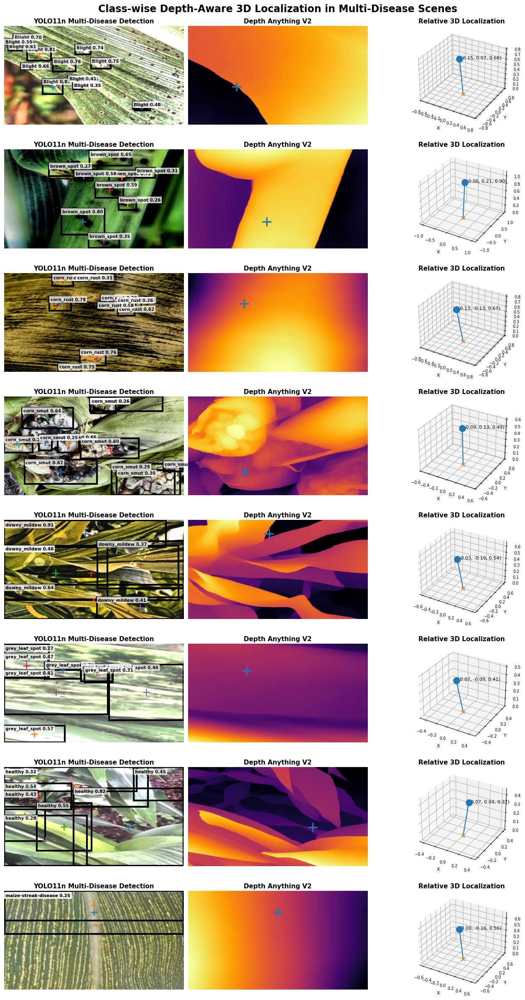


STEP 9.11 COMPLETE
Classes visualized: 8 / 8

Figure saved at:
/kaggle/working/maize_paper_final_results/Figures/Figure_8_classwise_multi_disease_RGB_Depth_3D.png

Selection strategy:
  ✓ Only images with >= 2 meaningful detections
  ✓ Very large/full-image boxes excluded
  ✓ All meaningful detections shown in YOLO panel
  ✓ Target class highlighted
  ✓ Target disease used for depth/3D localization
  ✓ Relative depth only
  ✓ No right-side colorbar


In [30]:
# ============================================================
# STEP 9.11 — CLASS-WISE MULTI-DISEASE RGB + DEPTH + 3D
#
# Select images containing MULTIPLE meaningful detections
# Avoid full-image disease boxes
# NO RIGHT-SIDE COLORBAR
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

print("=" * 100)
print("STEP 9.11 — CLASS-WISE MULTI-DISEASE RGB + DEPTH + 3D")
print("=" * 100)


# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

OUTPUT_DIR = Path(
    "/kaggle/working/maize_paper_final_results/Figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIG_PATH = (
    OUTPUT_DIR /
    "Figure_8_classwise_multi_disease_RGB_Depth_3D.png"
)

df = pd.read_csv(
    CSV_PATH
)

print(
    f"Total detections available: {len(df)}"
)


# ============================================================
# 2. CLASS ORDER
# ============================================================

class_names = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]


# ============================================================
# 3. REMOVE FULL-IMAGE / VERY LARGE BOXES
#
# These are NOT used for selecting representative disease
# detections.
# ============================================================

AREA_THRESHOLD = 0.60

meaningful_df = df[
    df["bbox_area_ratio"] <= AREA_THRESHOLD
].copy()

print(
    f"\nDetections before filtering : {len(df)}"
)

print(
    f"Detections after filtering  : {len(meaningful_df)}"
)

print(
    f"Removed large/full-image boxes: "
    f"{len(df) - len(meaningful_df)}"
)


# ============================================================
# 4. FIND IMAGES CONTAINING MULTIPLE MEANINGFUL DETECTIONS
# ============================================================

image_detection_counts = (
    meaningful_df
    .groupby("image_name")
    .size()
    .reset_index(
        name="meaningful_detection_count"
    )
)


# Keep only images with >= 2 meaningful detections
multi_detection_images = (
    image_detection_counts[
        image_detection_counts[
            "meaningful_detection_count"
        ] >= 2
    ]
)


print(
    f"\nImages with >=2 meaningful detections: "
    f"{len(multi_detection_images)}"
)


# Add count to dataframe
meaningful_df = meaningful_df.merge(
    multi_detection_images,
    on="image_name",
    how="inner"
)


# ============================================================
# 5. SELECT ONE REPRESENTATIVE IMAGE PER CLASS
#
# Preference:
#   1. Image contains multiple disease detections
#   2. Target class is present
#   3. Higher number of detections
#   4. Higher target confidence
#   5. Smaller bbox preferred over huge bbox
# ============================================================

representatives = []

for class_name in class_names:

    class_df = meaningful_df[
        meaningful_df["class_name"] == class_name
    ].copy()

    if len(class_df) == 0:

        print(
            f"WARNING: No suitable multi-disease image "
            f"found for {class_name}"
        )

        continue


    # Sort:
    # More detections first
    # Higher confidence next
    # Smaller bbox next

    class_df = class_df.sort_values(
        by=[
            "meaningful_detection_count",
            "confidence",
            "bbox_area_ratio"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )


    representative = class_df.iloc[0]

    representatives.append(
        representative
    )


# ============================================================
# 6. PRINT SELECTED REPRESENTATIVES
# ============================================================

print(
    "\nSelected multi-disease representatives:"
)

for r in representatives:

    print(
        f"{r['class_name']:<22} | "
        f"Image detections={int(r['meaningful_detection_count'])} | "
        f"Conf={r['confidence']:.3f} | "
        f"Area={r['bbox_area_ratio']:.3f} | "
        f"X={r['X_relative']:.3f} | "
        f"Y={r['Y_relative']:.3f} | "
        f"Z={r['Z_relative']:.3f}"
    )


# ============================================================
# 7. FIGURE LAYOUT
#
# Column 1 = YOLO11n multi-disease detection
# Column 2 = Depth Anything V2
# Column 3 = Relative 3D localization
# ============================================================

n = len(representatives)

fig = plt.figure(
    figsize=(13.5, 3.0 * n)
)

gs = GridSpec(
    nrows=n,
    ncols=3,
    figure=fig,

    width_ratios=[
        1,
        1,
        1
    ],

    height_ratios=[
        1
    ] * n,

    wspace=0.025,
    hspace=0.25
)


# ============================================================
# 8. PROCESS EACH CLASS
# ============================================================

for row, sample in enumerate(
    representatives
):

    target_class = sample[
        "class_name"
    ]

    image_name = sample[
        "image_name"
    ]

    image_path = TEST_DIR / image_name


    # ========================================================
    # LOAD IMAGE
    # ========================================================

    image_bgr = cv2.imread(
        str(image_path)
    )

    if image_bgr is None:

        print(
            f"Could not read: {image_name}"
        )

        continue


    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    H, W = image_rgb.shape[:2]


    # ========================================================
    # GET ALL MEANINGFUL DETECTIONS FROM SAME IMAGE
    # ========================================================

    image_detections = meaningful_df[
        meaningful_df["image_name"] == image_name
    ].copy()


    # ========================================================
    # TARGET DETECTION
    # ========================================================

    target_row = image_detections[
        image_detections["class_name"] == target_class
    ]

    # Use the selected target detection
    target = target_row.iloc[0]


    x1 = int(
        target["x1"]
    )

    y1 = int(
        target["y1"]
    )

    x2 = int(
        target["x2"]
    )

    y2 = int(
        target["y2"]
    )

    u = int(
        target["center_u"]
    )

    v = int(
        target["center_v"]
    )


    # ========================================================
    # CREATE AXES
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row, 1]
    )

    ax_3d = fig.add_subplot(
        gs[row, 2],
        projection="3d"
    )


    # ========================================================
    # PANEL 1 — YOLO11n MULTI-DISEASE DETECTIONS
    # ========================================================

    ax_yolo.imshow(
        image_rgb
    )


    # Draw ALL meaningful detections
    for _, det in image_detections.iterrows():

        dx1 = int(det["x1"])
        dy1 = int(det["y1"])
        dx2 = int(det["x2"])
        dy2 = int(det["y2"])

        du = int(det["center_u"])
        dv = int(det["center_v"])

        det_class = det["class_name"]
        det_conf = float(det["confidence"])


        # Target class gets thicker box
        if det_class == target_class:

            linewidth = 3.0

        else:

            linewidth = 1.8


        rect = plt.Rectangle(
            (dx1, dy1),
            dx2 - dx1,
            dy2 - dy1,
            fill=False,
            linewidth=linewidth
        )

        ax_yolo.add_patch(
            rect
        )


        # Center marker
        ax_yolo.plot(
            du,
            dv,
            marker="+",
            markersize=11,
            markeredgewidth=1.8
        )


        # Label
        label_y = max(
            16,
            dy1 + 5
        )

        ax_yolo.text(
            dx1 + 4,
            label_y,
            f"{det_class} {det_conf:.2f}",
            fontsize=7.5,
            fontweight=(
                "bold"
                if det_class == target_class
                else "normal"
            ),
            va="top",
            bbox=dict(
                facecolor="white",
                alpha=0.75,
                edgecolor="none",
                pad=2
            )
        )


    ax_yolo.set_title(
        "YOLO11n Multi-Disease Detection",
        fontsize=11,
        fontweight="bold",
        pad=5
    )

    ax_yolo.set_aspect(
        "auto"
    )

    ax_yolo.axis(
        "off"
    )


    # ========================================================
    # PANEL 2 — DEPTH ANYTHING V2
    # ========================================================

    pil_image = Image.fromarray(
        image_rgb
    )


    depth_inputs = depth_processor(
        images=pil_image,
        return_tensors="pt"
    )


    depth_inputs = {
        key: value.to(device)
        for key, value in depth_inputs.items()
    }


    with torch.inference_mode():

        depth_outputs = depth_model(
            **depth_inputs
        )


    depth_raw = (
        depth_outputs.predicted_depth
        .squeeze()
        .detach()
        .cpu()
        .numpy()
    )


    # Resize
    depth_raw = cv2.resize(
        depth_raw,
        (W, H),
        interpolation=cv2.INTER_LINEAR
    )


    # Normalize
    d_min = np.nanmin(
        depth_raw
    )

    d_max = np.nanmax(
        depth_raw
    )


    if d_max > d_min:

        depth_norm = (
            depth_raw - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_raw
        )


    ax_depth.imshow(
        depth_norm,
        cmap="inferno",
        vmin=0,
        vmax=1
    )


    # Target disease center
    ax_depth.plot(
        u,
        v,
        marker="+",
        markersize=16,
        markeredgewidth=2.5
    )


    ax_depth.set_title(
        "Depth Anything V2",
        fontsize=11,
        fontweight="bold",
        pad=5
    )


    ax_depth.set_aspect(
        "auto"
    )

    ax_depth.axis(
        "off"
    )


    # ========================================================
    # PANEL 3 — RELATIVE 3D LOCALIZATION
    # ========================================================

    X = float(
        target["X_relative"]
    )

    Y = float(
        target["Y_relative"]
    )

    Z = float(
        target["Z_relative"]
    )


    # Disease point
    ax_3d.scatter(
        [X],
        [Y],
        [Z],
        s=120,
        marker="o"
    )


    # Origin
    ax_3d.scatter(
        [0],
        [0],
        [0],
        s=35,
        marker="x"
    )


    # Origin to disease
    ax_3d.plot(
        [0, X],
        [0, Y],
        [0, Z],
        linewidth=1.5
    )


    # Coordinate label
    ax_3d.text(
        X,
        Y,
        Z,
        f"({X:.2f}, {Y:.2f}, {Z:.2f})",
        fontsize=8
    )


    # Axes
    ax_3d.set_xlabel(
        "X",
        fontsize=8,
        labelpad=2
    )

    ax_3d.set_ylabel(
        "Y",
        fontsize=8,
        labelpad=2
    )

    ax_3d.set_zlabel(
        "Z",
        fontsize=8,
        labelpad=2
    )


    ax_3d.set_title(
        "Relative 3D Localization",
        fontsize=11,
        fontweight="bold",
        pad=5
    )


    # Consistent limits
    max_range = max(
        abs(X),
        abs(Y),
        abs(Z),
        0.1
    )

    margin = max_range * 0.25


    ax_3d.set_xlim(
        -max_range - margin,
        max_range + margin
    )

    ax_3d.set_ylim(
        -max_range - margin,
        max_range + margin
    )

    ax_3d.set_zlim(
        0,
        max_range + margin
    )


    ax_3d.tick_params(
        labelsize=7
    )


# ============================================================
# 9. MAIN TITLE
# ============================================================

fig.suptitle(
    "Class-wise Depth-Aware 3D Localization in Multi-Disease Scenes",
    fontsize=17,
    fontweight="bold",
    y=0.997
)


# ============================================================
# 10. FINAL LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.015,
    right=0.985,
    top=0.975,
    bottom=0.015,
    wspace=0.025,
    hspace=0.25
)


# ============================================================
# 11. SAVE
# ============================================================

plt.savefig(
    FIG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# 12. DISPLAY
# ============================================================

plt.show()


# ============================================================
# 13. SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("STEP 9.11 COMPLETE")
print("=" * 100)

print(
    f"Classes visualized: "
    f"{len(representatives)} / {len(class_names)}"
)

print(
    f"\nFigure saved at:\n{FIG_PATH}"
)

print("\nSelection strategy:")
print("  ✓ Only images with >= 2 meaningful detections")
print("  ✓ Very large/full-image boxes excluded")
print("  ✓ All meaningful detections shown in YOLO panel")
print("  ✓ Target class highlighted")
print("  ✓ Target disease used for depth/3D localization")
print("  ✓ Relative depth only")
print("  ✓ No right-side colorbar")

print("=" * 100)

Total detections: 2903
Total images: 1493
Images having multiple detections: 616
[0] Blight                    -> MULTI image -> IMG_1005_jpg.rf.4e609347db5c97dd9ac5928214ad5995.jpg
[1] brown_spot                -> MULTI image -> 19c_jpg.rf.8dbec5dad48bb8bbc89b6860a8e238ef.jpg
[2] corn_rust                 -> MULTI image -> 1643674429204_jpeg_jpg.rf.2baa4645869b054b7d2f5e8a3b478547.jpg
[3] corn_smut                 -> MULTI image -> 30aaaaa_jpg.rf.f79e41b4687ea14c47488f4231f86ec0.jpg
[4] downy_mildew              -> MULTI image -> 10cccc_jpg.rf.e27bcede54f0994c5e7d88854b38622b.jpg
[5] grey_leaf_spot            -> MULTI image -> Corn_Gray_Spot-28-_jpg.rf.8779ba7d19555bd9a688cb568a3c8d8e.jpg
[6] healthy                   -> MULTI image -> 20200610_064314_jpg.rf.de3b97f2a9bceb1148e430fd66480671.jpg
[7] maize-streak-disease      -> MULTI image -> 1622020037676_jpg.rf.4d77939926a860975ca26935ea67a48f.jpg

RANDOM CLASS-WISE REPRESENTATIVES
          class_name                                

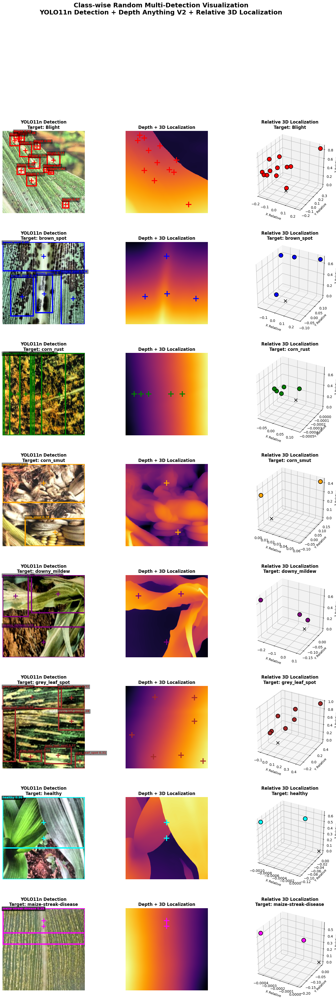


STEP 9.11 COMPLETED
Figure saved to:
/kaggle/working/maize_paper_final_results/Figures/Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png

Classes visualized: 8 / 8
All 8 classes are successfully visualized.

Selection method:
Random class-wise selection (seed = 42)

BBox area filtering:
NOT USED

Depth panel:
Only center markers — NO bounding boxes

3D panel:
All detections from the selected image


In [31]:
# ============================================================
# STEP 9.11 — RANDOM CLASS-WISE MULTI-DETECTION
# YOLO + DEPTH + RELATIVE 3D LOCALIZATION
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_DIR = Path(
    "/kaggle/working/maize_paper_final_results/Figures"
)

FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_PATH = (
    FIG_DIR /
    "Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png"
)

# ============================================================
# 2. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

# ============================================================
# 3. LOAD 3D LOCALIZATION CSV
# ============================================================

df = pd.read_csv(CSV_PATH)

print("Total detections:", len(df))
print("Total images:", df["image_name"].nunique())

# ============================================================
# 4. RANDOM SEED
# ============================================================

RANDOM_SEED = 42

# ============================================================
# 5. FIND IMAGES HAVING MULTIPLE DETECTIONS
# ============================================================
# IMPORTANT:
# NO bbox_area_ratio FILTER IS USED.
#
# We only prefer images that contain multiple detections.
# This means the selected class will be shown together
# with other detections from the same image.

image_detection_count = (
    df.groupby("image_name")
      .size()
      .reset_index(name="detection_count")
)

multi_detection_images = image_detection_count[
    image_detection_count["detection_count"] >= 2
]["image_name"].tolist()

print(
    "Images having multiple detections:",
    len(multi_detection_images)
)

# ============================================================
# 6. RANDOM CLASS-WISE SELECTION
# ============================================================

selected_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    # --------------------------------------------------------
    # First preference:
    # detections of this class that belong to an image
    # containing multiple detections
    # --------------------------------------------------------

    class_multi = df[
        (df["class_name"] == class_name) &
        (df["image_name"].isin(multi_detection_images))
    ].copy()

    if len(class_multi) > 0:

        selected = class_multi.sample(
            n=1,
            random_state=RANDOM_SEED + class_id
        ).iloc[0]

        selected_rows.append(selected)

        print(
            f"[{class_id}] {class_name:25s} "
            f"-> MULTI image -> {selected['image_name']}"
        )

    else:

        # ----------------------------------------------------
        # Fallback:
        # If no multi-detection image exists for this class,
        # randomly select any detection of that class.
        # ----------------------------------------------------

        class_all = df[
            df["class_name"] == class_name
        ].copy()

        if len(class_all) > 0:

            selected = class_all.sample(
                n=1,
                random_state=RANDOM_SEED + class_id
            ).iloc[0]

            selected_rows.append(selected)

            print(
                f"[{class_id}] {class_name:25s} "
                f"-> SINGLE fallback -> {selected['image_name']}"
            )

        else:

            print(
                f"WARNING — No detection found for: {class_name}"
            )

# ============================================================
# 7. SELECTED REPRESENTATIVES
# ============================================================

selected_df = pd.DataFrame(selected_rows).reset_index(drop=True)

print("\n" + "=" * 80)
print("RANDOM CLASS-WISE REPRESENTATIVES")
print("=" * 80)

print(
    selected_df[
        [
            "class_name",
            "image_name",
            "confidence",
            "bbox_area_ratio",
            "X_relative",
            "Y_relative",
            "Z_relative"
        ]
    ].to_string(index=False)
)

print("\nClasses visualized:",
      len(selected_df), "/", len(CLASS_NAMES))

# ============================================================
# 8. CHECK ALL 8 CLASSES
# ============================================================

selected_classes = set(selected_df["class_name"])

missing_classes = [
    c for c in CLASS_NAMES
    if c not in selected_classes
]

if missing_classes:
    print(
        "\nWARNING — Missing classes:",
        missing_classes
    )
else:
    print("\nSUCCESS — All 8 classes selected.")

# ============================================================
# 9. FIGURE SETUP
# ============================================================

n_classes = len(selected_df)

fig = plt.figure(
    figsize=(18, 5.5 * n_classes)
)

gs = GridSpec(
    nrows=n_classes,
    ncols=3,
    figure=fig,
    width_ratios=[1, 1, 1],
    wspace=0.15,
    hspace=0.35
)

# ============================================================
# 10. CLASS-WISE COLORS FOR CENTER MARKERS
# ============================================================

class_colors = {
    "Blight": "red",
    "brown_spot": "blue",
    "corn_rust": "green",
    "corn_smut": "orange",
    "downy_mildew": "purple",
    "grey_leaf_spot": "brown",
    "healthy": "cyan",
    "maize-streak-disease": "magenta"
}

# ============================================================
# 11. PROCESS EACH SELECTED CLASS
# ============================================================

for row_idx, selected in selected_df.iterrows():

    class_name = selected["class_name"]
    image_name = selected["image_name"]

    # --------------------------------------------------------
    # Get ALL detections from the same image
    # --------------------------------------------------------

    image_detections = df[
        df["image_name"] == image_name
    ].copy()

    # --------------------------------------------------------
    # Image path
    # --------------------------------------------------------

    image_path = TEST_DIR / image_name

    if not image_path.exists():
        print(
            f"WARNING: Image not found: {image_path}"
        )
        continue

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    image = Image.open(image_path).convert("RGB")

    img_np = np.array(image)

    H, W = img_np.shape[:2]

    # ========================================================
    # DEPTH ANYTHING V2
    # ========================================================

    inputs = depth_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = depth_model(**inputs)

    depth = outputs.predicted_depth

    # Resize depth to original image size

    depth = torch.nn.functional.interpolate(
        depth.unsqueeze(1),
        size=(H, W),
        mode="bicubic",
        align_corners=False
    ).squeeze()

    depth_map = depth.cpu().numpy()

    # --------------------------------------------------------
    # Normalize relative depth to [0, 1]
    # --------------------------------------------------------

    d_min = np.nanmin(depth_map)
    d_max = np.nanmax(depth_map)

    if d_max > d_min:

        depth_norm = (
            depth_map - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(depth_map)

    # ========================================================
    # CREATE 3 PANELS
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row_idx, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row_idx, 1]
    )

    ax_3d = fig.add_subplot(
        gs[row_idx, 2],
        projection="3d"
    )

    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(img_np)

    for _, det in image_detections.iterrows():

        x1 = int(det["x1"])
        y1 = int(det["y1"])
        x2 = int(det["x2"])
        y2 = int(det["y2"])

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]
        conf = float(det["confidence"])

        # Highlight selected class

        if det_class == class_name:

            linewidth = 3.5
            marker_size = 13
            text_weight = "bold"

        else:

            linewidth = 2.0
            marker_size = 9
            text_weight = "normal"

        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=linewidth,
            edgecolor=class_colors.get(
                det_class,
                "white"
            )
        )

        ax_yolo.add_patch(rect)

        # ----------------------------------------------------
        # Detection center
        # ----------------------------------------------------

        ax_yolo.plot(
            du,
            dv,
            marker="+",
            markersize=marker_size,
            markeredgewidth=2.5,
            color=class_colors.get(
                det_class,
                "white"
            )
        )

        # ----------------------------------------------------
        # Label
        # ----------------------------------------------------

        label = f"{det_class} {conf:.2f}"

        ax_yolo.text(
            x1,
            max(y1 - 5, 10),
            label,
            fontsize=8,
            fontweight=text_weight,
            color=class_colors.get(
                det_class,
                "white"
            ),
            bbox=dict(
                facecolor="black",
                alpha=0.45,
                pad=2
            )
        )

    ax_yolo.set_title(
        f"YOLO11n Detection\n"
        f"Target: {class_name}",
        fontsize=12,
        fontweight="bold"
    )

    ax_yolo.axis("off")

    # ========================================================
    # PANEL 2 — DEPTH + 3D LOCALIZATION
    # ========================================================
    # IMPORTANT:
    # NO bounding boxes here.
    # ONLY center markers for ALL detections.
    # ========================================================

    ax_depth.imshow(
        depth_norm,
        cmap="inferno"
    )

    for _, det in image_detections.iterrows():

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # ----------------------------------------------------
        # Only center marker
        # ----------------------------------------------------

        ax_depth.plot(
            du,
            dv,
            marker="+",
            markersize=16,
            markeredgewidth=2.8,
            color=marker_color
        )

    ax_depth.set_title(
        "Depth + 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    ax_depth.axis("off")

    # ========================================================
    # PANEL 3 — RELATIVE 3D LOCALIZATION
    # ========================================================

    # --------------------------------------------------------
    # Plot all detections from this image in 3D
    # --------------------------------------------------------

    for _, det in image_detections.iterrows():

        X = float(det["X_relative"])
        Y = float(det["Y_relative"])
        Z = float(det["Z_relative"])

        det_class = det["class_name"]

        marker_color = class_colors.get(
            det_class,
            "black"
        )

        if det_class == class_name:

            ax_3d.scatter(
                X,
                Y,
                Z,
                s=130,
                color=marker_color,
                edgecolors="black",
                linewidths=1.5,
                marker="o"
            )

        else:

            ax_3d.scatter(
                X,
                Y,
                Z,
                s=60,
                color=marker_color,
                alpha=0.65,
                marker="o"
            )

    # --------------------------------------------------------
    # Origin
    # --------------------------------------------------------

    ax_3d.scatter(
        0,
        0,
        0,
        s=70,
        color="black",
        marker="x"
    )

    ax_3d.set_xlabel(
        "X Relative",
        fontsize=9
    )

    ax_3d.set_ylabel(
        "Y Relative",
        fontsize=9
    )

    ax_3d.set_zlabel(
        "Z Relative",
        fontsize=9
    )

    ax_3d.set_title(
        f"Relative 3D Localization\n"
        f"Target: {class_name}",
        fontsize=12,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Keep aspect visually balanced
    # --------------------------------------------------------

    try:
        ax_3d.set_box_aspect(
            [1, 1, 1]
        )
    except:
        pass

# ============================================================
# 12. MAIN FIGURE TITLE
# ============================================================

fig.suptitle(
    "Class-wise Random Multi-Detection Visualization\n"
    "YOLO11n Detection + Depth Anything V2 + Relative 3D Localization",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

# ============================================================
# 13. SAVE FIGURE
# ============================================================

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 9.11 COMPLETED")
print("=" * 80)

print(
    "Figure saved to:"
)
print(SAVE_PATH)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

if missing_classes:

    print(
        "Missing classes:",
        missing_classes
    )

else:

    print(
        "All 8 classes are successfully visualized."
    )

print(
    "\nSelection method:"
)
print(
    "Random class-wise selection "
    "(seed = 42)"
)

print(
    "\nBBox area filtering:"
)
print(
    "NOT USED"
)

print(
    "\nDepth panel:"
)
print(
    "Only center markers — NO bounding boxes"
)

print(
    "\n3D panel:"
)
print(
    "All detections from the selected image"
)

print("=" * 80)

Total detections: 2903
Total images: 1493
Images with multiple detections: 616
Blight                    -> multi-detection image -> IMG_1005_jpg.rf.4e609347db5c97dd9ac5928214ad5995.jpg
brown_spot                -> multi-detection image -> 19c_jpg.rf.8dbec5dad48bb8bbc89b6860a8e238ef.jpg
corn_rust                 -> multi-detection image -> 1643674429204_jpeg_jpg.rf.2baa4645869b054b7d2f5e8a3b478547.jpg
corn_smut                 -> multi-detection image -> 30aaaaa_jpg.rf.f79e41b4687ea14c47488f4231f86ec0.jpg
downy_mildew              -> multi-detection image -> 10cccc_jpg.rf.e27bcede54f0994c5e7d88854b38622b.jpg
grey_leaf_spot            -> multi-detection image -> Corn_Gray_Spot-28-_jpg.rf.8779ba7d19555bd9a688cb568a3c8d8e.jpg
healthy                   -> multi-detection image -> 20200610_064314_jpg.rf.de3b97f2a9bceb1148e430fd66480671.jpg
maize-streak-disease      -> multi-detection image -> 1622020037676_jpg.rf.4d77939926a860975ca26935ea67a48f.jpg

SELECTED CLASS-WISE REPRESENTATIVES
    

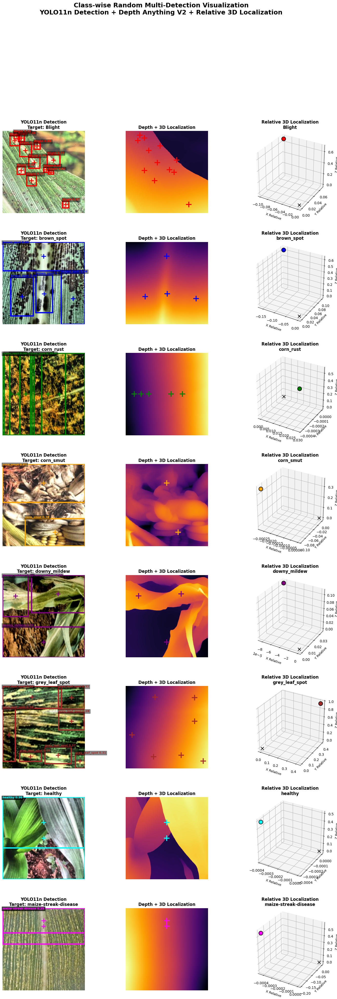


STEP 9.11 COMPLETED
Figure saved to:
/kaggle/working/maize_paper_final_results/Figures/Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png

Classes visualized: 8 / 8
All 8 classes successfully visualized.

Selection: Random class-wise
bbox_area_ratio filter: NOT USED
Depth panel: center markers only
Right panel: Relative 3D Localization


In [32]:
# ============================================================
# STEP 9.11 — RANDOM CLASS-WISE MULTI-DETECTION VISUALIZATION
# YOLO11n + Depth Anything V2 + Relative 3D Localization
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_DIR = Path(
    "/kaggle/working/maize_paper_final_results/Figures"
)

FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_PATH = (
    FIG_DIR /
    "Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png"
)

# ============================================================
# 2. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

# ============================================================
# 3. LOAD 3D LOCALIZATION DATA
# ============================================================

df = pd.read_csv(CSV_PATH)

print("Total detections:", len(df))
print("Total images:", df["image_name"].nunique())

# ============================================================
# 4. RANDOM SEED
# ============================================================

RANDOM_SEED = 42

# ============================================================
# 5. FIND IMAGES WITH MULTIPLE DETECTIONS
# ============================================================

image_counts = (
    df.groupby("image_name")
      .size()
      .reset_index(name="detection_count")
)

multi_detection_images = image_counts[
    image_counts["detection_count"] >= 2
]["image_name"].tolist()

print(
    "Images with multiple detections:",
    len(multi_detection_images)
)

# ============================================================
# 6. RANDOMLY SELECT ONE REPRESENTATIVE PER CLASS
# ============================================================
#
# NO bbox_area_ratio FILTER
#
# Priority:
#   1. Random detection from an image having >=2 detections
#   2. If unavailable, random detection from the class
#
# ============================================================

selected_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    # --------------------------------------------------------
    # Candidate detections from multi-detection images
    # --------------------------------------------------------

    class_multi = df[
        (df["class_name"] == class_name) &
        (df["image_name"].isin(multi_detection_images))
    ].copy()

    if len(class_multi) > 0:

        selected = class_multi.sample(
            n=1,
            random_state=RANDOM_SEED + class_id
        ).iloc[0]

        selected_rows.append(selected)

        print(
            f"{class_name:25s} -> "
            f"multi-detection image -> "
            f"{selected['image_name']}"
        )

    else:

        # ----------------------------------------------------
        # Fallback: any random detection from this class
        # ----------------------------------------------------

        class_all = df[
            df["class_name"] == class_name
        ].copy()

        if len(class_all) > 0:

            selected = class_all.sample(
                n=1,
                random_state=RANDOM_SEED + class_id
            ).iloc[0]

            selected_rows.append(selected)

            print(
                f"{class_name:25s} -> "
                f"fallback -> "
                f"{selected['image_name']}"
            )

        else:

            print(
                f"WARNING — No detection found for "
                f"{class_name}"
            )

# ============================================================
# 7. SELECTED REPRESENTATIVES
# ============================================================

selected_df = (
    pd.DataFrame(selected_rows)
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("SELECTED CLASS-WISE REPRESENTATIVES")
print("=" * 80)

print(
    selected_df[
        [
            "class_name",
            "image_name",
            "confidence",
            "bbox_area_ratio",
            "X_relative",
            "Y_relative",
            "Z_relative"
        ]
    ].to_string(index=False)
)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

# ============================================================
# 8. CHECK MISSING CLASSES
# ============================================================

selected_classes = set(
    selected_df["class_name"]
)

missing_classes = [
    c for c in CLASS_NAMES
    if c not in selected_classes
]

if missing_classes:

    print(
        "WARNING — Missing classes:",
        missing_classes
    )

else:

    print(
        "SUCCESS — All 8 classes selected."
    )

# ============================================================
# 9. CLASS COLORS
# ============================================================

class_colors = {
    "Blight": "red",
    "brown_spot": "blue",
    "corn_rust": "green",
    "corn_smut": "orange",
    "downy_mildew": "purple",
    "grey_leaf_spot": "brown",
    "healthy": "cyan",
    "maize-streak-disease": "magenta"
}

# ============================================================
# 10. FIGURE
# ============================================================

n_classes = len(selected_df)

fig = plt.figure(
    figsize=(18, 5.5 * n_classes)
)

gs = GridSpec(
    nrows=n_classes,
    ncols=3,
    figure=fig,
    width_ratios=[1, 1, 1],
    wspace=0.15,
    hspace=0.35
)

# ============================================================
# 11. PROCESS EACH CLASS
# ============================================================

for row_idx, selected in selected_df.iterrows():

    target_class = selected["class_name"]
    image_name = selected["image_name"]

    # --------------------------------------------------------
    # ALL detections from the SAME IMAGE
    # --------------------------------------------------------

    image_detections = df[
        df["image_name"] == image_name
    ].copy()

    # --------------------------------------------------------
    # Image path
    # --------------------------------------------------------

    image_path = TEST_DIR / image_name

    if not image_path.exists():

        print(
            f"WARNING — Image not found: "
            f"{image_path}"
        )

        continue

    # --------------------------------------------------------
    # Load RGB image
    # --------------------------------------------------------

    image = Image.open(
        image_path
    ).convert("RGB")

    img_np = np.array(image)

    H, W = img_np.shape[:2]

    # ========================================================
    # DEPTH ANYTHING V2
    # ========================================================

    inputs = depth_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = depth_model(**inputs)

    depth = outputs.predicted_depth

    # Resize depth map to image size

    depth = torch.nn.functional.interpolate(
        depth.unsqueeze(1),
        size=(H, W),
        mode="bicubic",
        align_corners=False
    ).squeeze()

    depth_map = depth.cpu().numpy()

    # --------------------------------------------------------
    # Normalize to relative depth [0,1]
    # --------------------------------------------------------

    d_min = np.nanmin(depth_map)
    d_max = np.nanmax(depth_map)

    if d_max > d_min:

        depth_norm = (
            depth_map - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_map
        )

    # ========================================================
    # CREATE THREE PANELS
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row_idx, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row_idx, 1]
    )

    ax_3d = fig.add_subplot(
        gs[row_idx, 2],
        projection="3d"
    )

    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(img_np)

    for _, det in image_detections.iterrows():

        x1 = int(det["x1"])
        y1 = int(det["y1"])
        x2 = int(det["x2"])
        y2 = int(det["y2"])

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]
        conf = float(det["confidence"])

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # Highlight target class

        if det_class == target_class:

            linewidth = 3.5
            marker_size = 13
            text_weight = "bold"

        else:

            linewidth = 2.0
            marker_size = 9
            text_weight = "normal"

        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=linewidth,
            edgecolor=marker_color
        )

        ax_yolo.add_patch(rect)

        # ----------------------------------------------------
        # Center marker
        # ----------------------------------------------------

        ax_yolo.plot(
            du,
            dv,
            marker="+",
            markersize=marker_size,
            markeredgewidth=2.5,
            color=marker_color
        )

        # ----------------------------------------------------
        # Class + confidence
        # ----------------------------------------------------

        ax_yolo.text(
            x1,
            max(y1 - 5, 10),
            f"{det_class} {conf:.2f}",
            fontsize=8,
            fontweight=text_weight,
            color=marker_color,
            bbox=dict(
                facecolor="black",
                alpha=0.45,
                pad=2
            )
        )

    ax_yolo.set_title(
        f"YOLO11n Detection\n"
        f"Target: {target_class}",
        fontsize=12,
        fontweight="bold"
    )

    ax_yolo.axis("off")

    # ========================================================
    # PANEL 2 — DEPTH + 3D LOCALIZATION
    # ========================================================
    #
    # NO bounding boxes.
    # ONLY center markers of all detections.
    # ========================================================

    ax_depth.imshow(
        depth_norm,
        cmap="inferno"
    )

    for _, det in image_detections.iterrows():

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        ax_depth.plot(
            du,
            dv,
            marker="+",
            markersize=16,
            markeredgewidth=2.8,
            color=marker_color
        )

    ax_depth.set_title(
        "Depth + 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    ax_depth.axis("off")

    # ========================================================
    # PANEL 3 — RELATIVE 3D LOCALIZATION
    # ========================================================
    #
    # RIGHT-MOST PANEL DESIGN KEPT AS BEFORE
    # ========================================================

    # --------------------------------------------------------
    # Target class 3D point
    # --------------------------------------------------------

    target_X = float(
        selected["X_relative"]
    )

    target_Y = float(
        selected["Y_relative"]
    )

    target_Z = float(
        selected["Z_relative"]
    )

    target_color = class_colors.get(
        target_class,
        "red"
    )

    ax_3d.scatter(
        target_X,
        target_Y,
        target_Z,
        s=130,
        color=target_color,
        edgecolors="black",
        linewidths=1.5,
        marker="o"
    )

    # --------------------------------------------------------
    # Origin
    # --------------------------------------------------------

    ax_3d.scatter(
        0,
        0,
        0,
        s=70,
        color="black",
        marker="x"
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax_3d.set_xlabel(
        "X Relative",
        fontsize=9
    )

    ax_3d.set_ylabel(
        "Y Relative",
        fontsize=9
    )

    ax_3d.set_zlabel(
        "Z Relative",
        fontsize=9
    )

    ax_3d.set_title(
        f"Relative 3D Localization\n"
        f"{target_class}",
        fontsize=12,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Keep same visual aspect
    # --------------------------------------------------------

    try:

        ax_3d.set_box_aspect(
            [1, 1, 1]
        )

    except:

        pass

# ============================================================
# 12. MAIN TITLE
# ============================================================

fig.suptitle(
    "Class-wise Random Multi-Detection Visualization\n"
    "YOLO11n Detection + Depth Anything V2 + Relative 3D Localization",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

# ============================================================
# 13. SAVE
# ============================================================

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 9.11 COMPLETED")
print("=" * 80)

print(
    "Figure saved to:"
)

print(SAVE_PATH)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

if missing_classes:

    print(
        "Missing classes:",
        missing_classes
    )

else:

    print(
        "All 8 classes successfully visualized."
    )

print(
    "\nSelection: Random class-wise"
)

print(
    "bbox_area_ratio filter: NOT USED"
)

print(
    "Depth panel: center markers only"
)

print(
    "Right panel: Relative 3D Localization"
)

print("=" * 80)

Total detections: 2903
Total images: 1493
Images with multiple detections: 616
Blight                    -> MULTI -> IMG_1005_jpg.rf.4e609347db5c97dd9ac5928214ad5995.jpg
brown_spot                -> MULTI -> 19c_jpg.rf.8dbec5dad48bb8bbc89b6860a8e238ef.jpg
corn_rust                 -> MULTI -> 1643674429204_jpeg_jpg.rf.2baa4645869b054b7d2f5e8a3b478547.jpg
corn_smut                 -> MULTI -> 30aaaaa_jpg.rf.f79e41b4687ea14c47488f4231f86ec0.jpg
downy_mildew              -> MULTI -> 10cccc_jpg.rf.e27bcede54f0994c5e7d88854b38622b.jpg
grey_leaf_spot            -> MULTI -> Corn_Gray_Spot-28-_jpg.rf.8779ba7d19555bd9a688cb568a3c8d8e.jpg
healthy                   -> MULTI -> 20200610_064314_jpg.rf.de3b97f2a9bceb1148e430fd66480671.jpg
maize-streak-disease      -> MULTI -> 1622020037676_jpg.rf.4d77939926a860975ca26935ea67a48f.jpg

SELECTED REPRESENTATIVES
          class_name                                                     image_name  confidence  bbox_area_ratio  X_relative  Y_relative  Z_rel

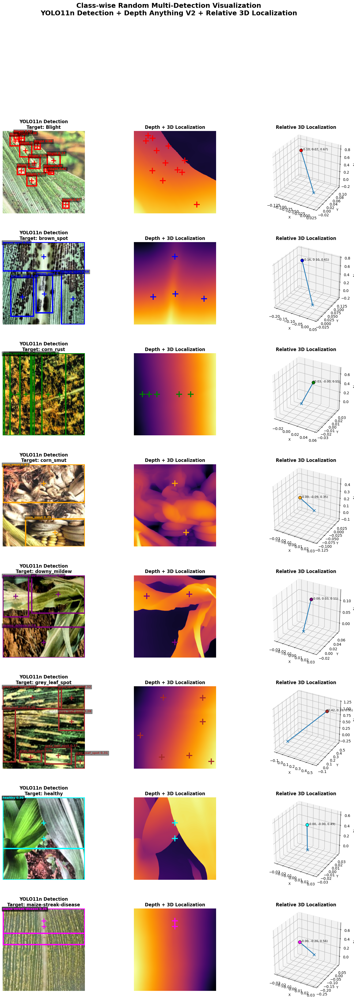


STEP 9.11 COMPLETED
Figure saved to:
/kaggle/working/maize_paper_final_results/Figures/Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png

Classes visualized: 8 / 8
All 8 classes successfully visualized.

Selection:
Random class-wise

BBox area filtering:
NOT USED

Depth panel:
Only center markers, NO bounding boxes

3D panel:
Single target point + origin + connecting line + coordinates


In [33]:
# ============================================================
# STEP 9.11 — RANDOM CLASS-WISE MULTI-DETECTION
# YOLO11n + Depth Anything V2 + Relative 3D Localization
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_DIR = Path(
    "/kaggle/working/maize_paper_final_results/Figures"
)

FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_PATH = (
    FIG_DIR /
    "Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png"
)

# ============================================================
# 2. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

# ============================================================
# 3. LOAD DATA
# ============================================================

df = pd.read_csv(CSV_PATH)

print("Total detections:", len(df))
print("Total images:", df["image_name"].nunique())

# ============================================================
# 4. RANDOM SEED
# ============================================================

RANDOM_SEED = 42

# ============================================================
# 5. FIND MULTI-DETECTION IMAGES
# ============================================================

image_counts = (
    df.groupby("image_name")
      .size()
      .reset_index(name="detection_count")
)

multi_detection_images = image_counts[
    image_counts["detection_count"] >= 2
]["image_name"].tolist()

print(
    "Images with multiple detections:",
    len(multi_detection_images)
)

# ============================================================
# 6. RANDOM CLASS-WISE REPRESENTATIVE SELECTION
# ============================================================
#
# NO bbox_area_ratio FILTER
#
# For each class:
#   First try a random detection from an image
#   containing multiple detections.
#
#   If unavailable, use any random detection
#   from that class.
#
# ============================================================

selected_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    # --------------------------------------------------------
    # Multi-detection candidates
    # --------------------------------------------------------

    class_multi = df[
        (df["class_name"] == class_name) &
        (df["image_name"].isin(multi_detection_images))
    ].copy()

    if len(class_multi) > 0:

        selected = class_multi.sample(
            n=1,
            random_state=RANDOM_SEED + class_id
        ).iloc[0]

        selected_rows.append(selected)

        print(
            f"{class_name:25s} -> "
            f"MULTI -> {selected['image_name']}"
        )

    else:

        # ----------------------------------------------------
        # Fallback
        # ----------------------------------------------------

        class_all = df[
            df["class_name"] == class_name
        ].copy()

        if len(class_all) > 0:

            selected = class_all.sample(
                n=1,
                random_state=RANDOM_SEED + class_id
            ).iloc[0]

            selected_rows.append(selected)

            print(
                f"{class_name:25s} -> "
                f"FALLBACK -> {selected['image_name']}"
            )

        else:

            print(
                f"WARNING — No detection found: "
                f"{class_name}"
            )

# ============================================================
# 7. SELECTED DATAFRAME
# ============================================================

selected_df = (
    pd.DataFrame(selected_rows)
    .reset_index(drop=True)
)

print("\n" + "=" * 80)
print("SELECTED REPRESENTATIVES")
print("=" * 80)

print(
    selected_df[
        [
            "class_name",
            "image_name",
            "confidence",
            "bbox_area_ratio",
            "X_relative",
            "Y_relative",
            "Z_relative"
        ]
    ].to_string(index=False)
)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

# ============================================================
# 8. CHECK MISSING CLASSES
# ============================================================

selected_classes = set(
    selected_df["class_name"]
)

missing_classes = [
    c for c in CLASS_NAMES
    if c not in selected_classes
]

if missing_classes:

    print(
        "WARNING — Missing classes:",
        missing_classes
    )

else:

    print(
        "SUCCESS — All 8 classes selected."
    )

# ============================================================
# 9. CLASS COLORS
# ============================================================

class_colors = {
    "Blight": "red",
    "brown_spot": "blue",
    "corn_rust": "green",
    "corn_smut": "orange",
    "downy_mildew": "purple",
    "grey_leaf_spot": "brown",
    "healthy": "cyan",
    "maize-streak-disease": "magenta"
}

# ============================================================
# 10. FIGURE SETUP
# ============================================================

n_classes = len(selected_df)

fig = plt.figure(
    figsize=(18, 5.2 * n_classes)
)

gs = GridSpec(
    nrows=n_classes,
    ncols=3,
    figure=fig,
    width_ratios=[1, 1, 1],
    wspace=0.18,
    hspace=0.35
)

# ============================================================
# 11. PROCESS EACH CLASS
# ============================================================

for row_idx, selected in selected_df.iterrows():

    target_class = selected["class_name"]
    image_name = selected["image_name"]

    # --------------------------------------------------------
    # ALL detections from same image
    # --------------------------------------------------------

    image_detections = df[
        df["image_name"] == image_name
    ].copy()

    # --------------------------------------------------------
    # Image path
    # --------------------------------------------------------

    image_path = TEST_DIR / image_name

    if not image_path.exists():

        print(
            f"WARNING — Image not found: {image_path}"
        )

        continue

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    image = Image.open(
        image_path
    ).convert("RGB")

    img_np = np.array(image)

    H, W = img_np.shape[:2]

    # ========================================================
    # DEPTH ANYTHING V2
    # ========================================================

    inputs = depth_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = depth_model(**inputs)

    depth = outputs.predicted_depth

    # --------------------------------------------------------
    # Resize depth map
    # --------------------------------------------------------

    depth = torch.nn.functional.interpolate(
        depth.unsqueeze(1),
        size=(H, W),
        mode="bicubic",
        align_corners=False
    ).squeeze()

    depth_map = depth.cpu().numpy()

    # --------------------------------------------------------
    # Normalize depth
    # --------------------------------------------------------

    d_min = np.nanmin(depth_map)
    d_max = np.nanmax(depth_map)

    if d_max > d_min:

        depth_norm = (
            depth_map - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_map
        )

    # ========================================================
    # THREE PANELS
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row_idx, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row_idx, 1]
    )

    ax_3d = fig.add_subplot(
        gs[row_idx, 2],
        projection="3d"
    )

    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(img_np)

    for _, det in image_detections.iterrows():

        x1 = int(det["x1"])
        y1 = int(det["y1"])
        x2 = int(det["x2"])
        y2 = int(det["y2"])

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]
        conf = float(det["confidence"])

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # Highlight selected class

        if det_class == target_class:

            linewidth = 3.5
            marker_size = 13
            text_weight = "bold"

        else:

            linewidth = 2.0
            marker_size = 9
            text_weight = "normal"

        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=linewidth,
            edgecolor=marker_color
        )

        ax_yolo.add_patch(rect)

        # ----------------------------------------------------
        # Center
        # ----------------------------------------------------

        ax_yolo.plot(
            du,
            dv,
            marker="+",
            markersize=marker_size,
            markeredgewidth=2.5,
            color=marker_color
        )

        # ----------------------------------------------------
        # Label
        # ----------------------------------------------------

        ax_yolo.text(
            x1,
            max(y1 - 5, 10),
            f"{det_class} {conf:.2f}",
            fontsize=8,
            fontweight=text_weight,
            color=marker_color,
            bbox=dict(
                facecolor="black",
                alpha=0.45,
                pad=2
            )
        )

    ax_yolo.set_title(
        f"YOLO11n Detection\n"
        f"Target: {target_class}",
        fontsize=12,
        fontweight="bold"
    )

    ax_yolo.axis("off")

    # ========================================================
    # PANEL 2 — DEPTH + 3D LOCALIZATION
    # ========================================================
    #
    # NO bounding boxes
    # ONLY center markers
    # ========================================================

    ax_depth.imshow(
        depth_norm,
        cmap="inferno"
    )

    for _, det in image_detections.iterrows():

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        ax_depth.plot(
            du,
            dv,
            marker="+",
            markersize=16,
            markeredgewidth=2.8,
            color=marker_color
        )

    ax_depth.set_title(
        "Depth + 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    ax_depth.axis("off")

    # ========================================================
    # PANEL 3 — RELATIVE 3D LOCALIZATION
    # ========================================================
    #
    # EXACT SIMPLE DESIGN:
    #   - One target point
    #   - Origin
    #   - Line from origin to point
    #   - Coordinate annotation
    #
    # ========================================================

    X = float(
        selected["X_relative"]
    )

    Y = float(
        selected["Y_relative"]
    )

    Z = float(
        selected["Z_relative"]
    )

    target_color = class_colors.get(
        target_class,
        "blue"
    )

    # --------------------------------------------------------
    # Line from origin to target
    # --------------------------------------------------------

    ax_3d.plot(
        [0, X],
        [0, Y],
        [0, Z],
        linewidth=2.0
    )

    # --------------------------------------------------------
    # Target point
    # --------------------------------------------------------

    ax_3d.scatter(
        X,
        Y,
        Z,
        s=70,
        color=target_color,
        edgecolors="black",
        linewidths=0.8,
        marker="o"
    )

    # --------------------------------------------------------
    # Origin
    # --------------------------------------------------------

    ax_3d.scatter(
        0,
        0,
        0,
        s=45,
        marker="x"
    )

    # --------------------------------------------------------
    # Coordinate annotation
    # --------------------------------------------------------

    ax_3d.text(
        X,
        Y,
        Z,
        f"({X:.2f}, {Y:.2f}, {Z:.2f})",
        fontsize=8
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax_3d.set_xlabel(
        "X",
        fontsize=9
    )

    ax_3d.set_ylabel(
        "Y",
        fontsize=9
    )

    ax_3d.set_zlabel(
        "Z",
        fontsize=9
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax_3d.set_title(
        "Relative 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Same visual style / aspect
    # --------------------------------------------------------

    try:

        ax_3d.set_box_aspect(
            [1, 1, 1]
        )

    except:

        pass

    # --------------------------------------------------------
    # Make sure zero/origin is visible
    # --------------------------------------------------------

    all_x = [0, X]
    all_y = [0, Y]
    all_z = [0, Z]

    x_range = max(
        max(all_x) - min(all_x),
        0.1
    )

    y_range = max(
        max(all_y) - min(all_y),
        0.1
    )

    z_range = max(
        max(all_z) - min(all_z),
        0.1
    )

    # Small padding

    x_pad = x_range * 0.35
    y_pad = y_range * 0.35
    z_pad = z_range * 0.35

    ax_3d.set_xlim(
        min(all_x) - x_pad,
        max(all_x) + x_pad
    )

    ax_3d.set_ylim(
        min(all_y) - y_pad,
        max(all_y) + y_pad
    )

    ax_3d.set_zlim(
        min(all_z) - z_pad,
        max(all_z) + z_pad
    )

# ============================================================
# 12. MAIN TITLE
# ============================================================

fig.suptitle(
    "Class-wise Random Multi-Detection Visualization\n"
    "YOLO11n Detection + Depth Anything V2 + Relative 3D Localization",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

# ============================================================
# 13. SAVE FIGURE
# ============================================================

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 9.11 COMPLETED")
print("=" * 80)

print(
    "Figure saved to:"
)

print(SAVE_PATH)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

if missing_classes:

    print(
        "Missing classes:",
        missing_classes
    )

else:

    print(
        "All 8 classes successfully visualized."
    )

print("\nSelection:")
print("Random class-wise")

print("\nBBox area filtering:")
print("NOT USED")

print("\nDepth panel:")
print("Only center markers, NO bounding boxes")

print("\n3D panel:")
print("Single target point + origin + connecting line + coordinates")

print("=" * 80)

Total detections: 2903
Total images: 1493
Images with multiple detections: 616
Blight                    -> MULTI -> IMG_1005_jpg.rf.4e609347db5c97dd9ac5928214ad5995.jpg
brown_spot                -> MULTI -> 19c_jpg.rf.8dbec5dad48bb8bbc89b6860a8e238ef.jpg
corn_rust                 -> MULTI -> 1643674429204_jpeg_jpg.rf.2baa4645869b054b7d2f5e8a3b478547.jpg
corn_smut                 -> MULTI -> 30aaaaa_jpg.rf.f79e41b4687ea14c47488f4231f86ec0.jpg
downy_mildew              -> MULTI -> 10cccc_jpg.rf.e27bcede54f0994c5e7d88854b38622b.jpg
grey_leaf_spot            -> MULTI -> Corn_Gray_Spot-28-_jpg.rf.8779ba7d19555bd9a688cb568a3c8d8e.jpg
healthy                   -> MULTI -> 20200610_064314_jpg.rf.de3b97f2a9bceb1148e430fd66480671.jpg
maize-streak-disease      -> MULTI -> 1622020037676_jpg.rf.4d77939926a860975ca26935ea67a48f.jpg

SELECTED CLASS-WISE REPRESENTATIVES
          class_name                                                     image_name  confidence  bbox_area_ratio  X_relative  Y_rela

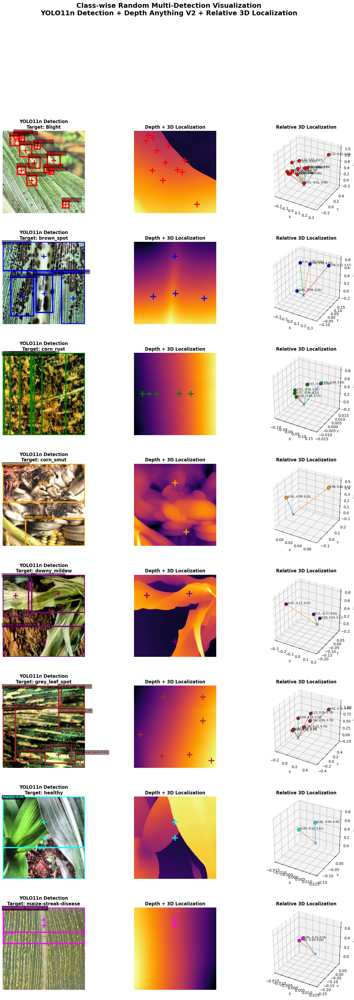


STEP 9.11 COMPLETED
Figure saved to:
/kaggle/working/maize_paper_final_results/Figures/Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png

Classes visualized: 8 / 8
All 8 classes successfully visualized.

Selection:
Random class-wise

BBox area filtering:
NOT USED

YOLO panel:
All detections + bounding boxes + centers

Depth panel:
All detections + center markers only

3D panel:
ALL detections + 3D points + origin + connecting lines


In [34]:
# ============================================================
# STEP 9.11 — RANDOM CLASS-WISE MULTI-DETECTION
# YOLO11n + Depth Anything V2 + RELATIVE 3D LOCALIZATION
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

FIG_DIR = Path(
    "/kaggle/working/maize_paper_final_results/Figures"
)

FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_PATH = (
    FIG_DIR /
    "Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png"
)

# ============================================================
# 2. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

# ============================================================
# 3. LOAD 3D LOCALIZATION DATA
# ============================================================

df = pd.read_csv(CSV_PATH)

print("Total detections:", len(df))
print("Total images:", df["image_name"].nunique())

# ============================================================
# 4. RANDOM SEED
# ============================================================

RANDOM_SEED = 42

# ============================================================
# 5. FIND IMAGES WITH MULTIPLE DETECTIONS
# ============================================================

image_counts = (
    df.groupby("image_name")
      .size()
      .reset_index(name="detection_count")
)

multi_detection_images = image_counts[
    image_counts["detection_count"] >= 2
]["image_name"].tolist()

print(
    "Images with multiple detections:",
    len(multi_detection_images)
)

# ============================================================
# 6. RANDOM CLASS-WISE REPRESENTATIVE SELECTION
# ============================================================
#
# NO bbox_area_ratio FILTER
#
# For each class:
#   Priority 1 -> random detection from multi-detection image
#   Priority 2 -> random detection from any image
#
# ============================================================

selected_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    # --------------------------------------------------------
    # Candidate detections from multi-detection images
    # --------------------------------------------------------

    class_multi = df[
        (df["class_name"] == class_name) &
        (df["image_name"].isin(multi_detection_images))
    ].copy()

    if len(class_multi) > 0:

        selected = class_multi.sample(
            n=1,
            random_state=RANDOM_SEED + class_id
        ).iloc[0]

        selected_rows.append(selected)

        print(
            f"{class_name:25s} -> MULTI -> "
            f"{selected['image_name']}"
        )

    else:

        # ----------------------------------------------------
        # Fallback
        # ----------------------------------------------------

        class_all = df[
            df["class_name"] == class_name
        ].copy()

        if len(class_all) > 0:

            selected = class_all.sample(
                n=1,
                random_state=RANDOM_SEED + class_id
            ).iloc[0]

            selected_rows.append(selected)

            print(
                f"{class_name:25s} -> FALLBACK -> "
                f"{selected['image_name']}"
            )

        else:

            print(
                f"WARNING — No detection found: "
                f"{class_name}"
            )

# ============================================================
# 7. SELECTED REPRESENTATIVES
# ============================================================

selected_df = (
    pd.DataFrame(selected_rows)
    .reset_index(drop=True)
)

print("\n" + "=" * 90)
print("SELECTED CLASS-WISE REPRESENTATIVES")
print("=" * 90)

print(
    selected_df[
        [
            "class_name",
            "image_name",
            "confidence",
            "bbox_area_ratio",
            "X_relative",
            "Y_relative",
            "Z_relative"
        ]
    ].to_string(index=False)
)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

# ============================================================
# 8. CHECK MISSING CLASSES
# ============================================================

selected_classes = set(
    selected_df["class_name"]
)

missing_classes = [
    c for c in CLASS_NAMES
    if c not in selected_classes
]

if missing_classes:

    print(
        "WARNING — Missing classes:",
        missing_classes
    )

else:

    print(
        "SUCCESS — All 8 classes selected."
    )

# ============================================================
# 9. CLASS COLORS
# ============================================================

class_colors = {
    "Blight": "red",
    "brown_spot": "blue",
    "corn_rust": "green",
    "corn_smut": "orange",
    "downy_mildew": "purple",
    "grey_leaf_spot": "brown",
    "healthy": "cyan",
    "maize-streak-disease": "magenta"
}

# ============================================================
# 10. FIGURE SETUP
# ============================================================

n_classes = len(selected_df)

fig = plt.figure(
    figsize=(18, 5.2 * n_classes)
)

gs = GridSpec(
    nrows=n_classes,
    ncols=3,
    figure=fig,
    width_ratios=[1, 1, 1],
    wspace=0.18,
    hspace=0.35
)

# ============================================================
# 11. PROCESS EACH SELECTED CLASS
# ============================================================

for row_idx, selected in selected_df.iterrows():

    target_class = selected["class_name"]
    image_name = selected["image_name"]

    # --------------------------------------------------------
    # ALL detections from SAME IMAGE
    # --------------------------------------------------------

    image_detections = df[
        df["image_name"] == image_name
    ].copy()

    # --------------------------------------------------------
    # Image path
    # --------------------------------------------------------

    image_path = TEST_DIR / image_name

    if not image_path.exists():

        print(
            f"WARNING — Image not found: "
            f"{image_path}"
        )

        continue

    # --------------------------------------------------------
    # Load RGB image
    # --------------------------------------------------------

    image = Image.open(
        image_path
    ).convert("RGB")

    img_np = np.array(image)

    H, W = img_np.shape[:2]

    # ========================================================
    # DEPTH ANYTHING V2
    # ========================================================

    inputs = depth_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = depth_model(**inputs)

    depth = outputs.predicted_depth

    # --------------------------------------------------------
    # Resize depth map
    # --------------------------------------------------------

    depth = torch.nn.functional.interpolate(
        depth.unsqueeze(1),
        size=(H, W),
        mode="bicubic",
        align_corners=False
    ).squeeze()

    depth_map = depth.cpu().numpy()

    # --------------------------------------------------------
    # Normalize depth to [0,1]
    # --------------------------------------------------------

    d_min = np.nanmin(depth_map)
    d_max = np.nanmax(depth_map)

    if d_max > d_min:

        depth_norm = (
            depth_map - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_map
        )

    # ========================================================
    # THREE PANELS
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row_idx, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row_idx, 1]
    )

    ax_3d = fig.add_subplot(
        gs[row_idx, 2],
        projection="3d"
    )

    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(img_np)

    for _, det in image_detections.iterrows():

        x1 = int(det["x1"])
        y1 = int(det["y1"])
        x2 = int(det["x2"])
        y2 = int(det["y2"])

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]
        conf = float(det["confidence"])

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # Highlight selected target

        if det_class == target_class:

            linewidth = 3.5
            marker_size = 13
            text_weight = "bold"

        else:

            linewidth = 2.0
            marker_size = 9
            text_weight = "normal"

        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=linewidth,
            edgecolor=marker_color
        )

        ax_yolo.add_patch(rect)

        # ----------------------------------------------------
        # Center marker
        # ----------------------------------------------------

        ax_yolo.plot(
            du,
            dv,
            marker="+",
            markersize=marker_size,
            markeredgewidth=2.5,
            color=marker_color
        )

        # ----------------------------------------------------
        # Label
        # ----------------------------------------------------

        ax_yolo.text(
            x1,
            max(y1 - 5, 10),
            f"{det_class} {conf:.2f}",
            fontsize=8,
            fontweight=text_weight,
            color=marker_color,
            bbox=dict(
                facecolor="black",
                alpha=0.45,
                pad=2
            )
        )

    ax_yolo.set_title(
        f"YOLO11n Detection\n"
        f"Target: {target_class}",
        fontsize=12,
        fontweight="bold"
    )

    ax_yolo.axis("off")

    # ========================================================
    # PANEL 2 — DEPTH + 3D LOCALIZATION
    # ========================================================
    #
    # NO BOUNDING BOXES
    # ONLY CENTER MARKERS
    # ========================================================

    ax_depth.imshow(
        depth_norm,
        cmap="inferno"
    )

    for _, det in image_detections.iterrows():

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # ----------------------------------------------------
        # Center marker only
        # ----------------------------------------------------

        ax_depth.plot(
            du,
            dv,
            marker="+",
            markersize=16,
            markeredgewidth=2.8,
            color=marker_color
        )

    ax_depth.set_title(
        "Depth + 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    ax_depth.axis("off")

    # ========================================================
    # PANEL 3 — RELATIVE 3D LOCALIZATION
    # ========================================================
    #
    # IMPORTANT:
    # ALL detections from the same image are plotted here.
    #
    # Each detection:
    #     center_u, center_v, Z_relative
    #          ↓
    #     X_relative, Y_relative, Z_relative
    #
    # Target class = larger highlighted point
    #
    # ========================================================

    # --------------------------------------------------------
    # Store coordinates for axis limits
    # --------------------------------------------------------

    all_X = []
    all_Y = []
    all_Z = []

    for _, det in image_detections.iterrows():

        X = float(det["X_relative"])
        Y = float(det["Y_relative"])
        Z = float(det["Z_relative"])

        all_X.append(X)
        all_Y.append(Y)
        all_Z.append(Z)

    # --------------------------------------------------------
    # Plot every detection
    # --------------------------------------------------------

    for _, det in image_detections.iterrows():

        X = float(det["X_relative"])
        Y = float(det["Y_relative"])
        Z = float(det["Z_relative"])

        det_class = det["class_name"]

        point_color = class_colors.get(
            det_class,
            "blue"
        )

        # ----------------------------------------------------
        # Highlight target class
        # ----------------------------------------------------

        if det_class == target_class:

            point_size = 70
            alpha_value = 1.0
            edge_width = 0.8

        else:

            point_size = 55
            alpha_value = 0.75
            edge_width = 0.5

        # ----------------------------------------------------
        # Line from origin to point
        # ----------------------------------------------------

        ax_3d.plot(
            [0, X],
            [0, Y],
            [0, Z],
            linewidth=1.5,
            alpha=0.65
        )

        # ----------------------------------------------------
        # 3D point
        # ----------------------------------------------------

        ax_3d.scatter(
            X,
            Y,
            Z,
            s=point_size,
            color=point_color,
            edgecolors="black",
            linewidths=edge_width,
            alpha=alpha_value,
            marker="o"
        )

        # ----------------------------------------------------
        # Coordinate annotation
        # ----------------------------------------------------

        ax_3d.text(
            X,
            Y,
            Z,
            f"({X:.2f}, {Y:.2f}, {Z:.2f})",
            fontsize=7
        )

    # --------------------------------------------------------
    # Origin
    # --------------------------------------------------------

    ax_3d.scatter(
        0,
        0,
        0,
        s=45,
        marker="x"
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax_3d.set_xlabel(
        "X",
        fontsize=9
    )

    ax_3d.set_ylabel(
        "Y",
        fontsize=9
    )

    ax_3d.set_zlabel(
        "Z",
        fontsize=9
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax_3d.set_title(
        "Relative 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Axis limits
    # --------------------------------------------------------

    if len(all_X) > 0:

        x_min = min(
            0,
            min(all_X)
        )

        x_max = max(
            0,
            max(all_X)
        )

        y_min = min(
            0,
            min(all_Y)
        )

        y_max = max(
            0,
            max(all_Y)
        )

        z_min = min(
            0,
            min(all_Z)
        )

        z_max = max(
            0,
            max(all_Z)
        )

        # ----------------------------------------------------
        # Padding
        # ----------------------------------------------------

        x_range = max(
            x_max - x_min,
            0.05
        )

        y_range = max(
            y_max - y_min,
            0.05
        )

        z_range = max(
            z_max - z_min,
            0.05
        )

        x_pad = x_range * 0.30
        y_pad = y_range * 0.30
        z_pad = z_range * 0.30

        ax_3d.set_xlim(
            x_min - x_pad,
            x_max + x_pad
        )

        ax_3d.set_ylim(
            y_min - y_pad,
            y_max + y_pad
        )

        ax_3d.set_zlim(
            z_min - z_pad,
            z_max + z_pad
        )

    # --------------------------------------------------------
    # Keep 3D aspect similar to previous design
    # --------------------------------------------------------

    try:

        ax_3d.set_box_aspect(
            [1, 1, 1]
        )

    except:

        pass

# ============================================================
# 12. MAIN TITLE
# ============================================================

fig.suptitle(
    "Class-wise Random Multi-Detection Visualization\n"
    "YOLO11n Detection + Depth Anything V2 + Relative 3D Localization",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

# ============================================================
# 13. SAVE FIGURE
# ============================================================

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("STEP 9.11 COMPLETED")
print("=" * 90)

print(
    "Figure saved to:"
)

print(SAVE_PATH)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

if missing_classes:

    print(
        "Missing classes:",
        missing_classes
    )

else:

    print(
        "All 8 classes successfully visualized."
    )

print("\nSelection:")
print("Random class-wise")

print("\nBBox area filtering:")
print("NOT USED")

print("\nYOLO panel:")
print("All detections + bounding boxes + centers")

print("\nDepth panel:")
print("All detections + center markers only")

print("\n3D panel:")
print("ALL detections + 3D points + origin + connecting lines")

print("=" * 90)

CHECKING IMAGE FOLDER
Image folder:
/kaggle/input/datasets/siam2461/chck-folder/Checking
Images found in Checking folder: 8

3D LOCALIZATION DATA
Total detections: 2903
Total images: 1493

CSV images matched with Checking folder: 18
CSV images NOT found in Checking folder: 2885

First missing images:
   0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_270deg_JPG_jpg.rf.621424bc15ab235f6713a6f7194acdb9.jpg
   0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_90deg_JPG_jpg.rf.a2c40ae78ca87852512cf798ffb3c1d2.jpg
   0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.3eae18f3e80ea236fdb5db3cc4568dc5.jpg
   0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.7c338f732b4c42b6e56a135d4391e44a.jpg
   0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.ba35bf7152cf71114b202321aa6bfc2d.jpg
   0a01cc10-3892-4311-9c48-0ac6ab3c7c43___RS_GLSp-9352_JPG_jpg.rf.c2743dd0a402b26a811636590801204d.jpg
   100-12_11_16_jpeg_jpg.rf.f18d6ade667a7e36a760dbd9df5ca7cd.jpg
  

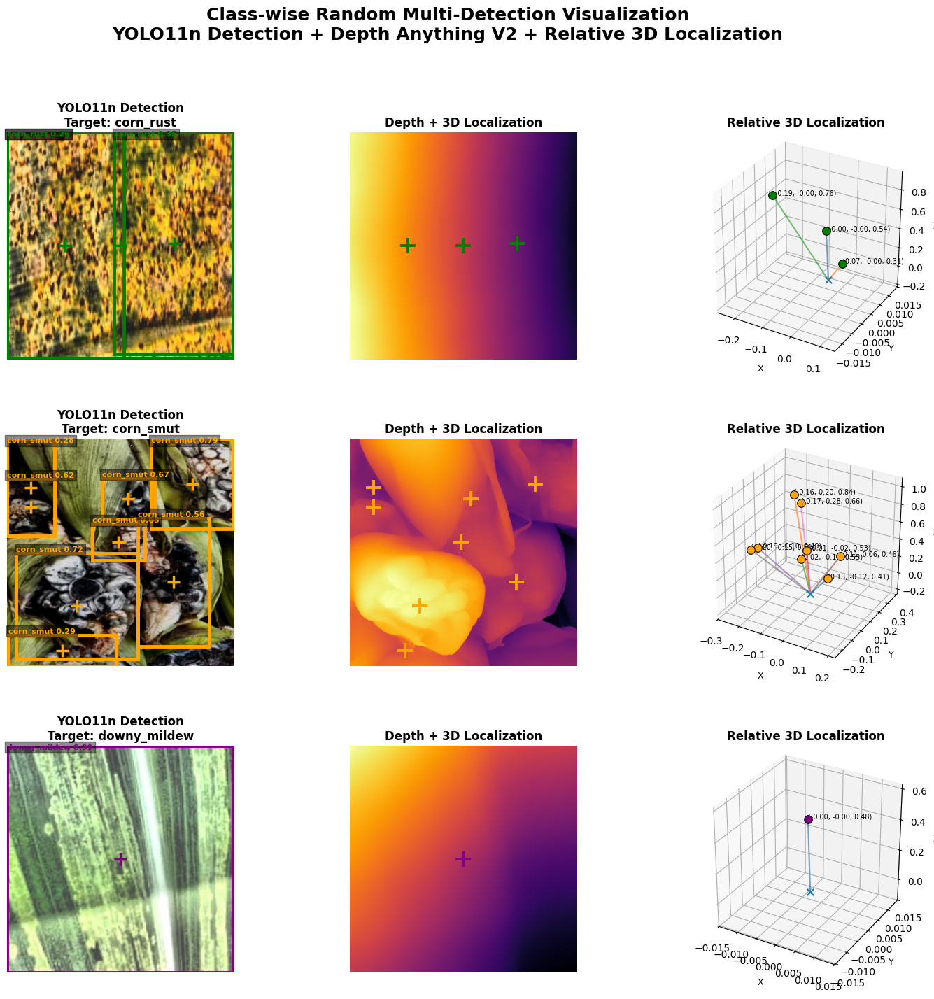


STEP 9.11 COMPLETED
Figure saved to:
/kaggle/working/maize_paper_final_results/Figures/Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png

Classes visualized: 3 / 8
Missing classes: ['Blight', 'brown_spot', 'grey_leaf_spot', 'healthy', 'maize-streak-disease']

Selection:
Random class-wise

BBox area filtering:
NOT USED

YOLO panel:
All detections + bounding boxes + centers

Depth panel:
All detections + center markers only

3D panel:
ALL detections + 3D points + origin + connecting lines


In [35]:
# ============================================================
# STEP 9.11 — RANDOM CLASS-WISE MULTI-DETECTION
# YOLO11n + Depth Anything V2 + RELATIVE 3D LOCALIZATION
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pathlib import Path
from matplotlib.gridspec import GridSpec


# ============================================================
# 1. PATHS
# ============================================================

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

# YOUR ACTUAL CHECKING IMAGE FOLDER
IMAGE_DIR = Path(
    "/kaggle/input/datasets/siam2461/chck-folder/Checking"
)

FIG_DIR = Path(
    "/kaggle/working/maize_paper_final_results/Figures"
)

FIG_DIR.mkdir(parents=True, exist_ok=True)

SAVE_PATH = (
    FIG_DIR /
    "Figure_8_classwise_random_multi_disease_RGB_Depth_3D.png"
)


# ============================================================
# 2. CHECK IMAGE FOLDER
# ============================================================

print("=" * 90)
print("CHECKING IMAGE FOLDER")
print("=" * 90)

if not IMAGE_DIR.exists():
    raise FileNotFoundError(
        f"Checking folder not found:\n{IMAGE_DIR}"
    )

# Find all image files recursively
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
}

available_image_paths = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg",
        ".jpeg",
        ".png"
    }
]

print("Image folder:")
print(IMAGE_DIR)

print(
    "Images found in Checking folder:",
    len(available_image_paths)
)

if len(available_image_paths) == 0:
    raise RuntimeError(
        "No image files found inside Checking folder."
    )


# ============================================================
# 3. CREATE ROBUST IMAGE NAME LOOKUP
# ============================================================
#
# This handles:
#   .jpg vs .JPG
#   uppercase/lowercase differences
#   nested folders
# ============================================================

image_lookup = {}

for p in available_image_paths:

    # Full filename
    image_lookup[p.name.lower()] = p

    # Filename without extension
    image_lookup[p.stem.lower()] = p


def find_image(image_name):

    """
    Find actual image path from CSV image_name.
    Handles case differences and extension differences.
    """

    if pd.isna(image_name):
        return None

    image_name = str(image_name).strip()

    # --------------------------------------------------------
    # 1. Exact path
    # --------------------------------------------------------

    exact_path = IMAGE_DIR / image_name

    if exact_path.exists():
        return exact_path

    # --------------------------------------------------------
    # 2. Case-insensitive full filename
    # --------------------------------------------------------

    key = image_name.lower()

    if key in image_lookup:
        return image_lookup[key]

    # --------------------------------------------------------
    # 3. Filename without extension
    # --------------------------------------------------------

    stem = Path(image_name).stem.lower()

    if stem in image_lookup:
        return image_lookup[stem]

    return None


# ============================================================
# 4. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]


# ============================================================
# 5. LOAD 3D LOCALIZATION DATA
# ============================================================

df = pd.read_csv(CSV_PATH)

print("\n" + "=" * 90)
print("3D LOCALIZATION DATA")
print("=" * 90)

print("Total detections:", len(df))
print("Total images:", df["image_name"].nunique())


# ============================================================
# 6. MATCH CSV IMAGES WITH CHECKING FOLDER
# ============================================================

df["actual_image_path"] = df["image_name"].apply(
    find_image
)

matched_count = df["actual_image_path"].notna().sum()
missing_count = df["actual_image_path"].isna().sum()

print("\nCSV images matched with Checking folder:", matched_count)
print("CSV images NOT found in Checking folder:", missing_count)

if missing_count > 0:

    print("\nFirst missing images:")

    missing_names = (
        df.loc[
            df["actual_image_path"].isna(),
            "image_name"
        ]
        .drop_duplicates()
        .head(10)
        .tolist()
    )

    for name in missing_names:
        print("  ", name)


# ============================================================
# 7. ONLY USE IMAGES THAT ACTUALLY EXIST
# ============================================================

df_available = df[
    df["actual_image_path"].notna()
].copy()

print(
    "\nUsable detections:",
    len(df_available)
)

print(
    "Usable images:",
    df_available["image_name"].nunique()
)

if len(df_available) == 0:
    raise RuntimeError(
        "No CSV image was found inside Checking folder."
    )


# ============================================================
# 8. RANDOM SEED
# ============================================================

RANDOM_SEED = 42


# ============================================================
# 9. FIND IMAGES WITH MULTIPLE DETECTIONS
# ============================================================

image_counts = (
    df_available.groupby("image_name")
    .size()
    .reset_index(name="detection_count")
)

multi_detection_images = image_counts[
    image_counts["detection_count"] >= 2
]["image_name"].tolist()

print(
    "\nImages with multiple detections:",
    len(multi_detection_images)
)


# ============================================================
# 10. RANDOM CLASS-WISE REPRESENTATIVE SELECTION
# ============================================================

selected_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    # --------------------------------------------------------
    # Candidate detections from multi-detection images
    # --------------------------------------------------------

    class_multi = df_available[
        (df_available["class_name"] == class_name) &
        (df_available["image_name"].isin(
            multi_detection_images
        ))
    ].copy()

    if len(class_multi) > 0:

        selected = class_multi.sample(
            n=1,
            random_state=RANDOM_SEED + class_id
        ).iloc[0]

        selected_rows.append(selected)

        print(
            f"{class_name:25s} -> MULTI -> "
            f"{selected['image_name']}"
        )

    else:

        # ----------------------------------------------------
        # Fallback
        # ----------------------------------------------------

        class_all = df_available[
            df_available["class_name"] == class_name
        ].copy()

        if len(class_all) > 0:

            selected = class_all.sample(
                n=1,
                random_state=RANDOM_SEED + class_id
            ).iloc[0]

            selected_rows.append(selected)

            print(
                f"{class_name:25s} -> FALLBACK -> "
                f"{selected['image_name']}"
            )

        else:

            print(
                f"WARNING — No usable detection found: "
                f"{class_name}"
            )


# ============================================================
# 11. SELECTED REPRESENTATIVES
# ============================================================

selected_df = (
    pd.DataFrame(selected_rows)
    .reset_index(drop=True)
)

print("\n" + "=" * 90)
print("SELECTED CLASS-WISE REPRESENTATIVES")
print("=" * 90)

print(
    selected_df[
        [
            "class_name",
            "image_name",
            "confidence",
            "bbox_area_ratio",
            "X_relative",
            "Y_relative",
            "Z_relative"
        ]
    ].to_string(index=False)
)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)


# ============================================================
# 12. CHECK MISSING CLASSES
# ============================================================

selected_classes = set(
    selected_df["class_name"]
)

missing_classes = [
    c for c in CLASS_NAMES
    if c not in selected_classes
]

if missing_classes:

    print(
        "WARNING — Missing classes:",
        missing_classes
    )

else:

    print(
        "SUCCESS — All 8 classes selected."
    )


# ============================================================
# 13. CLASS COLORS
# ============================================================

class_colors = {
    "Blight": "red",
    "brown_spot": "blue",
    "corn_rust": "green",
    "corn_smut": "orange",
    "downy_mildew": "purple",
    "grey_leaf_spot": "brown",
    "healthy": "cyan",
    "maize-streak-disease": "magenta"
}


# ============================================================
# 14. FIGURE SETUP
# ============================================================

n_classes = len(selected_df)

fig = plt.figure(
    figsize=(18, 5.2 * n_classes)
)

gs = GridSpec(
    nrows=n_classes,
    ncols=3,
    figure=fig,
    width_ratios=[1, 1, 1],
    wspace=0.18,
    hspace=0.35
)


# ============================================================
# 15. PROCESS EACH SELECTED CLASS
# ============================================================

for row_idx, selected in selected_df.iterrows():

    target_class = selected["class_name"]
    image_name = selected["image_name"]

    # --------------------------------------------------------
    # ALL detections from SAME IMAGE
    # --------------------------------------------------------

    image_detections = df_available[
        df_available["image_name"] == image_name
    ].copy()

    # --------------------------------------------------------
    # GET ACTUAL IMAGE PATH
    # --------------------------------------------------------

    image_path = selected["actual_image_path"]

    print(
        f"\n[{row_idx + 1}/{n_classes}] "
        f"{target_class} -> {image_path.name}"
    )

    # --------------------------------------------------------
    # Load RGB image
    # --------------------------------------------------------

    image = Image.open(
        image_path
    ).convert("RGB")

    img_np = np.array(image)

    H, W = img_np.shape[:2]

    # ========================================================
    # DEPTH ANYTHING V2
    # ========================================================

    inputs = depth_processor(
        images=image,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    with torch.no_grad():

        outputs = depth_model(**inputs)

    depth = outputs.predicted_depth

    # --------------------------------------------------------
    # Resize depth map
    # --------------------------------------------------------

    depth = torch.nn.functional.interpolate(
        depth.unsqueeze(1),
        size=(H, W),
        mode="bicubic",
        align_corners=False
    ).squeeze()

    depth_map = depth.cpu().numpy()

    # --------------------------------------------------------
    # Normalize depth to [0,1]
    # --------------------------------------------------------

    d_min = np.nanmin(depth_map)
    d_max = np.nanmax(depth_map)

    if d_max > d_min:

        depth_norm = (
            depth_map - d_min
        ) / (
            d_max - d_min
        )

    else:

        depth_norm = np.zeros_like(
            depth_map
        )

    # ========================================================
    # THREE PANELS
    # ========================================================

    ax_yolo = fig.add_subplot(
        gs[row_idx, 0]
    )

    ax_depth = fig.add_subplot(
        gs[row_idx, 1]
    )

    ax_3d = fig.add_subplot(
        gs[row_idx, 2],
        projection="3d"
    )

    # ========================================================
    # PANEL 1 — YOLO11n DETECTION
    # ========================================================

    ax_yolo.imshow(img_np)

    for _, det in image_detections.iterrows():

        x1 = int(det["x1"])
        y1 = int(det["y1"])
        x2 = int(det["x2"])
        y2 = int(det["y2"])

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]
        conf = float(det["confidence"])

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # Highlight selected target

        if det_class == target_class:

            linewidth = 3.5
            marker_size = 13
            text_weight = "bold"

        else:

            linewidth = 2.0
            marker_size = 9
            text_weight = "normal"

        # ----------------------------------------------------
        # Bounding box
        # ----------------------------------------------------

        rect = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            linewidth=linewidth,
            edgecolor=marker_color
        )

        ax_yolo.add_patch(rect)

        # ----------------------------------------------------
        # Center marker
        # ----------------------------------------------------

        ax_yolo.plot(
            du,
            dv,
            marker="+",
            markersize=marker_size,
            markeredgewidth=2.5,
            color=marker_color
        )

        # ----------------------------------------------------
        # Label
        # ----------------------------------------------------

        ax_yolo.text(
            x1,
            max(y1 - 5, 10),
            f"{det_class} {conf:.2f}",
            fontsize=8,
            fontweight=text_weight,
            color=marker_color,
            bbox=dict(
                facecolor="black",
                alpha=0.45,
                pad=2
            )
        )

    ax_yolo.set_title(
        f"YOLO11n Detection\n"
        f"Target: {target_class}",
        fontsize=12,
        fontweight="bold"
    )

    ax_yolo.axis("off")


    # ========================================================
    # PANEL 2 — DEPTH + 3D LOCALIZATION
    # ========================================================
    #
    # NO BOUNDING BOXES
    # ONLY CENTER MARKERS
    # ========================================================

    ax_depth.imshow(
        depth_norm,
        cmap="inferno"
    )

    for _, det in image_detections.iterrows():

        du = float(det["center_u"])
        dv = float(det["center_v"])

        det_class = det["class_name"]

        marker_color = class_colors.get(
            det_class,
            "white"
        )

        # ----------------------------------------------------
        # Center marker only
        # ----------------------------------------------------

        ax_depth.plot(
            du,
            dv,
            marker="+",
            markersize=16,
            markeredgewidth=2.8,
            color=marker_color
        )

    ax_depth.set_title(
        "Depth + 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    ax_depth.axis("off")


    # ========================================================
    # PANEL 3 — RELATIVE 3D LOCALIZATION
    # ========================================================

    all_X = []
    all_Y = []
    all_Z = []

    for _, det in image_detections.iterrows():

        X = float(det["X_relative"])
        Y = float(det["Y_relative"])
        Z = float(det["Z_relative"])

        all_X.append(X)
        all_Y.append(Y)
        all_Z.append(Z)

    # --------------------------------------------------------
    # Plot every detection
    # --------------------------------------------------------

    for _, det in image_detections.iterrows():

        X = float(det["X_relative"])
        Y = float(det["Y_relative"])
        Z = float(det["Z_relative"])

        det_class = det["class_name"]

        point_color = class_colors.get(
            det_class,
            "blue"
        )

        # Highlight target class

        if det_class == target_class:

            point_size = 70
            alpha_value = 1.0
            edge_width = 0.8

        else:

            point_size = 55
            alpha_value = 0.75
            edge_width = 0.5

        # ----------------------------------------------------
        # Line from origin to point
        # ----------------------------------------------------

        ax_3d.plot(
            [0, X],
            [0, Y],
            [0, Z],
            linewidth=1.5,
            alpha=0.65
        )

        # ----------------------------------------------------
        # 3D point
        # ----------------------------------------------------

        ax_3d.scatter(
            X,
            Y,
            Z,
            s=point_size,
            color=point_color,
            edgecolors="black",
            linewidths=edge_width,
            alpha=alpha_value,
            marker="o"
        )

        # ----------------------------------------------------
        # Coordinate annotation
        # ----------------------------------------------------

        ax_3d.text(
            X,
            Y,
            Z,
            f"({X:.2f}, {Y:.2f}, {Z:.2f})",
            fontsize=7
        )

    # --------------------------------------------------------
    # Origin
    # --------------------------------------------------------

    ax_3d.scatter(
        0,
        0,
        0,
        s=45,
        marker="x"
    )

    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax_3d.set_xlabel(
        "X",
        fontsize=9
    )

    ax_3d.set_ylabel(
        "Y",
        fontsize=9
    )

    ax_3d.set_zlabel(
        "Z",
        fontsize=9
    )

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    ax_3d.set_title(
        "Relative 3D Localization",
        fontsize=12,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Axis limits
    # --------------------------------------------------------

    if len(all_X) > 0:

        x_min = min(
            0,
            min(all_X)
        )

        x_max = max(
            0,
            max(all_X)
        )

        y_min = min(
            0,
            min(all_Y)
        )

        y_max = max(
            0,
            max(all_Y)
        )

        z_min = min(
            0,
            min(all_Z)
        )

        z_max = max(
            0,
            max(all_Z)
        )

        # ----------------------------------------------------
        # Padding
        # ----------------------------------------------------

        x_range = max(
            x_max - x_min,
            0.05
        )

        y_range = max(
            y_max - y_min,
            0.05
        )

        z_range = max(
            z_max - z_min,
            0.05
        )

        x_pad = x_range * 0.30
        y_pad = y_range * 0.30
        z_pad = z_range * 0.30

        ax_3d.set_xlim(
            x_min - x_pad,
            x_max + x_pad
        )

        ax_3d.set_ylim(
            y_min - y_pad,
            y_max + y_pad
        )

        ax_3d.set_zlim(
            z_min - z_pad,
            z_max + z_pad
        )

    # --------------------------------------------------------
    # Keep 3D aspect similar to previous design
    # --------------------------------------------------------

    try:

        ax_3d.set_box_aspect(
            [1, 1, 1]
        )

    except:

        pass


# ============================================================
# 16. MAIN TITLE
# ============================================================

fig.suptitle(
    "Class-wise Random Multi-Detection Visualization\n"
    "YOLO11n Detection + Depth Anything V2 + Relative 3D Localization",
    fontsize=18,
    fontweight="bold",
    y=0.995
)


# ============================================================
# 17. SAVE FIGURE
# ============================================================

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("STEP 9.11 COMPLETED")
print("=" * 90)

print(
    "Figure saved to:"
)

print(SAVE_PATH)

print(
    f"\nClasses visualized: "
    f"{len(selected_df)} / {len(CLASS_NAMES)}"
)

if missing_classes:

    print(
        "Missing classes:",
        missing_classes
    )

else:

    print(
        "All 8 classes successfully visualized."
    )

print("\nSelection:")
print("Random class-wise")

print("\nBBox area filtering:")
print("NOT USED")

print("\nYOLO panel:")
print("All detections + bounding boxes + centers")

print("\nDepth panel:")
print("All detections + center markers only")

print("\n3D panel:")
print("ALL detections + 3D points + origin + connecting lines")

print("=" * 90)

In [36]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path(
    "/kaggle/working/maize_paper_results/3D_Results/3d_localization.csv"
)

IMAGE_DIR = Path(
    "/kaggle/input/datasets/siam2461/chck-folder/Checking"
)

df = pd.read_csv(CSV_PATH)

# Same selection logic
CLASS_NAMES = [
    "Blight",
    "brown_spot",
    "corn_rust",
    "corn_smut",
    "downy_mildew",
    "grey_leaf_spot",
    "healthy",
    "maize-streak-disease"
]

RANDOM_SEED = 42

image_counts = (
    df.groupby("image_name")
      .size()
      .reset_index(name="detection_count")
)

multi_detection_images = image_counts[
    image_counts["detection_count"] >= 2
]["image_name"].tolist()

selected_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    class_multi = df[
        (df["class_name"] == class_name) &
        (df["image_name"].isin(multi_detection_images))
    ].copy()

    if len(class_multi) > 0:

        selected = class_multi.sample(
            n=1,
            random_state=RANDOM_SEED + class_id
        ).iloc[0]

        selected_rows.append(selected)

    else:

        class_all = df[
            df["class_name"] == class_name
        ].copy()

        if len(class_all) > 0:

            selected = class_all.sample(
                n=1,
                random_state=RANDOM_SEED + class_id
            ).iloc[0]

            selected_rows.append(selected)


selected_df = pd.DataFrame(selected_rows).reset_index(drop=True)

print("=" * 100)
print("SELECTED 8 IMAGES FROM CSV")
print("=" * 100)

for _, row in selected_df.iterrows():

    csv_name = row["image_name"]

    print("\nCSV:")
    print(csv_name)

    # Search recursively
    matches = list(IMAGE_DIR.rglob(csv_name))

    if matches:
        print("FOUND:")
        print(matches[0])

    else:
        # Case-insensitive search
        matches = [
            p for p in IMAGE_DIR.rglob("*")
            if p.is_file()
            and p.name.lower() == csv_name.lower()
        ]

        if matches:
            print("FOUND (case-insensitive):")
            print(matches[0])

        else:
            print("NOT FOUND")

print("\n" + "=" * 100)
print("ALL FILES ACTUALLY INSIDE CHECKING")
print("=" * 100)

for p in IMAGE_DIR.rglob("*"):
    if p.is_file():
        print(p.name)

SELECTED 8 IMAGES FROM CSV

CSV:
IMG_1005_jpg.rf.4e609347db5c97dd9ac5928214ad5995.jpg
NOT FOUND

CSV:
19c_jpg.rf.8dbec5dad48bb8bbc89b6860a8e238ef.jpg
NOT FOUND

CSV:
1643674429204_jpeg_jpg.rf.2baa4645869b054b7d2f5e8a3b478547.jpg
NOT FOUND

CSV:
30aaaaa_jpg.rf.f79e41b4687ea14c47488f4231f86ec0.jpg
NOT FOUND

CSV:
10cccc_jpg.rf.e27bcede54f0994c5e7d88854b38622b.jpg
NOT FOUND

CSV:
Corn_Gray_Spot-28-_jpg.rf.8779ba7d19555bd9a688cb568a3c8d8e.jpg
NOT FOUND

CSV:
20200610_064314_jpg.rf.de3b97f2a9bceb1148e430fd66480671.jpg
NOT FOUND

CSV:
1622020037676_jpg.rf.4d77939926a860975ca26935ea67a48f.jpg
NOT FOUND

ALL FILES ACTUALLY INSIDE CHECKING
16ccc_jpg.rf.51643751ccec852991a504a5163dbadb.jpg
17_jpg.rf.2bf724b9e126526cdff6a1c4ce60bf46.jpg
18cccccc_jpg.rf.26bac338cc7bfab227b3935622b9d9fa.jpg
1cccccc_jpg.rf.0e00bf7b681eb8bf3c75fc9eda54aeba.jpg
31aa_jpg.rf.b9b3a7a86e8ae8f063e7d76c8726206e.jpg
42aaaa_jpg.rf.9d4b116df0a79738fe610423588066c5.jpg
9cccccc_jpg.rf.15b02475d6224b3f1ee5f29dd00601c7.jpg
Corn_Co